# Proyecto Final — Confiabilidad y planeación de capacidad de un servicio de inferencia de IA (AndesVision AI)

**Materia:** Ciencia Computacional Intermedia — Universidad Sergio Arboleda
**Docente:** Ph.D. Ricardo Andrés Fonseca Perdomo

**Integrantes:**
- Dady Sneider Loaiza Loaiza
- Martín Santiago Pinzón Quiceno
- Duban Enrique Vargas Fula

**Parámetros de identificación:**
- C1 = 1106891817 + 1141318622 = 2248210439
- C2 = 1011099583
- S = C1 + C2 = 3259310022

In [94]:
import numpy as np  # arreglos y algebra numerica
import pandas as pd  # tablas de datos
import matplotlib.pyplot as plt  # graficos
import seaborn as sns  # graficos estadisticos con estilo
from scipy import stats  # distribuciones y pruebas estadisticas
from scipy import optimize  # optimizadores (para maxima verosimilitud)
from scipy.special import gammaln  # log de la funcion gamma (C2)
import os  # utilidades del sistema operativo

pd.set_option("display.width", 140)  # tablas mas anchas al imprimir
pd.set_option("display.max_columns", 30)  # maximo de columnas al imprimir
sns.set_theme(style="whitegrid")  # fondo con rejilla en los graficos

C1 = 1106891817 + 1141318622  # suma de las dos cedulas del primer bloque
C2 = 1011099583  # cedula del segundo bloque
S = C1 + C2  # semilla y base de todos los parametros

tau = 180 + 10 * (S % 9)  # umbral del SLO en ms
epsilon = 0.01 * (1 + S % 3)  # proporcion maxima tolerada de L > tau
niveles = {0: 0.90, 1: 0.95, 2: 0.99}  # nivel de confianza segun S mod 3
confianza = niveles[S % 3]  # nivel 1 - alpha
alpha = 1 - confianza  # probabilidad de error
g = 1.4 + 0.1 * (S % 7)  # factor de crecimiento de la tasa
t1 = 80 + 10 * (S % 5)  # frontera pequena / mediana en KB
t2 = 400 + 25 * (S % 5)  # frontera mediana / grande en KB
pi_prod = (4 + S % 6) / 1000  # prevalencia de incidentes en produccion
k_max = 4 + (S % 5)  # falsas alarmas maximas por dia
r = S % 6  # desplazamiento para B4
N = 10 + (S % 11)  # solicitudes consecutivas para C4

rng = np.random.default_rng(S)  # unica fuente de aleatoriedad del notebook

parametros = pd.DataFrame({  # tabla resumen de parametros
    "parametro": ["S", "tau (ms)", "epsilon", "1 - alpha", "g", "t1 (KB)", "t2 (KB)", "pi", "k_max", "r", "N"],  # nombres de los parametros
    "valor": [str(S), str(tau), str(round(epsilon, 2)), str(confianza), str(round(g, 1)), str(t1), str(t2),  # valores convertidos a texto
              str(pi_prod), str(k_max), str(r), str(N)],  # como texto para que no salga en notacion cientifica
})
print(parametros.to_string(index=False))  # muestra la tabla sin indice

parametro      valor
        S 3259310022
 tau (ms)        180
  epsilon       0.01
1 - alpha        0.9
        g        1.7
  t1 (KB)        100
  t2 (KB)        450
       pi      0.004
    k_max          6
        r          0
        N         11


# Parte A — Auditoría y preparación de los datos

## A1. Auditoría de `solicitudes.csv`

Revisamos cada columna desde la lógica del sistema: una solicitud con caché no usa GPU, la latencia no puede ser menor que red + GPU (la espera en cola es mayor o igual a cero), los intentos van de 1 a 3 y una solicitud solo puede fallar si agotó los 3 intentos. También buscamos duplicados, nulos, valores negativos y valores fuera de escala. Primero contamos cada problema sobre los datos crudos.

In [95]:
crudos = pd.read_csv("solicitudes.csv")  # datos tal como llegan
print("filas crudas:", len(crudos))  # cantidad de filas leidas
print(crudos.head())  # primeras filas
print()  # linea en blanco
print("nulos por columna:")  # titulo de la salida
print(crudos.isna().sum())  # cuenta de nulos por columna

filas crudas: 40951
   id_solicitud  t_llegada_s  tam_kb  cache_hit version  red_ms  gpu_ms  latencia_ms  intentos  exito
0             1       0.0822  308.08          0       A   13.77   49.45        63.22         1      1
1             2       0.1876  827.28          1       B   19.56    0.00        19.56         1      1
2             3       0.2032  608.65          0       B   20.98   23.39        44.37         1      1
3             4       0.2169  278.76          0       A   21.91   30.20        52.10         1      1
4             5       0.2267   84.03          1       A   20.71    0.00        20.71         1      1

nulos por columna:
id_solicitud     0
t_llegada_s      0
tam_kb           0
cache_hit        0
version          0
red_ms          41
gpu_ms          40
latencia_ms      0
intentos         0
exito            0
dtype: int64


In [96]:
duplicados_exactos = crudos.duplicated().sum()  # filas identicas en todas las columnas
ids_repetidos = crudos["id_solicitud"].duplicated().sum()  # ids que aparecen mas de una vez
print("filas duplicadas exactas:", duplicados_exactos)  # imprime duplicados exactos
print("ids repetidos:", ids_repetidos)  # imprime ids repetidos

conteo_ids = crudos["id_solicitud"].value_counts()  # veces que aparece cada id
ids_con_copia = conteo_ids[conteo_ids > 1].index  # ids que aparecen mas de una vez
ids_de_exactos = set(crudos[crudos.duplicated(keep=False)]["id_solicitud"])  # ids cuyas copias son identicas
ids_raros = [i for i in ids_con_copia if i not in ids_de_exactos]  # id repetido pero con filas distintas
print("ids repetidos que no son copia exacta:", ids_raros)  # imprime los ids raros
print(crudos[crudos["id_solicitud"].isin(ids_raros)])  # muestra esas filas completas

filas duplicadas exactas: 121
ids repetidos: 122
ids repetidos que no son copia exacta: [21359]
       id_solicitud  t_llegada_s  tam_kb  cache_hit version  red_ms  gpu_ms  latencia_ms  intentos  exito
21416         21359     718.3461  193.45          0       A    12.8     NaN       136.97         1      1
21417         21359     718.3461  193.45          0       A    12.8   14.97       136.97         1      1


In [97]:
print("latencia negativa:", (crudos["latencia_ms"] < 0).sum())  # latencias negativas
print("valores de latencia negativa:", crudos.loc[crudos["latencia_ms"] < 0, "latencia_ms"].unique())  # que valores negativos hay
print("red negativa:", (crudos["red_ms"] < 0).sum())  # tiempos de red negativos
print("gpu negativa:", (crudos["gpu_ms"] < 0).sum())  # tiempos de gpu negativos
print("tam_kb <= 0:", (crudos["tam_kb"] <= 0).sum())  # tamanos no positivos
print("gpu > 0 con cache_hit = 1:", ((crudos["gpu_ms"] > 0) & (crudos["cache_hit"] == 1)).sum())  # gpu usada aunque hubo cache
print("gpu = 0 con cache_hit = 0:", ((crudos["gpu_ms"] == 0) & (crudos["cache_hit"] == 0)).sum())  # sin gpu y sin cache
print("intentos fuera de 1..3:", (~crudos["intentos"].isin([1, 2, 3])).sum())  # intentos fuera del rango valido
print("tiempos de llegada fuera de [0, 1200]:", ((crudos["t_llegada_s"] < 0) | (crudos["t_llegada_s"] > 1200)).sum())  # llegadas fuera de la ventana de 1200 s
print("llegadas desordenadas:", (crudos["t_llegada_s"].diff() < 0).sum())  # llegadas que retroceden en el tiempo
print()  # linea en blanco
print("tabla intentos vs exito:")  # titulo de la tabla
print(pd.crosstab(crudos["intentos"], crudos["exito"]))  # intentos contra exito

latencia negativa: 122
valores de latencia negativa: [-1.]
red negativa: 0
gpu negativa: 0
tam_kb <= 0: 0
gpu > 0 con cache_hit = 1: 0
gpu = 0 con cache_hit = 0: 0
intentos fuera de 1..3: 0
tiempos de llegada fuera de [0, 1200]: 0
llegadas desordenadas: 0

tabla intentos vs exito:
exito       0      1
intentos            
1           0  34209
2           0   5491
3         242   1009


La tabla de intentos contra éxito es coherente: solo hay fallos (`exito` = 0) con 3 intentos, que es justo cuando el SDK abandona. Ahora miramos `tam_kb`, que tiene un máximo de más de un millón de KB (un GB por imagen no tiene sentido para una API de clasificación).

In [98]:
tamanos_ordenados = np.sort(crudos["tam_kb"].values)  # tamanos ordenados de menor a mayor
print("los 70 tamanos mas grandes:")  # titulo de la salida
print(tamanos_ordenados[-70:].round(1))  # se ve el salto entre ~1600 y ~17000

limite_tam = 5000  # hay un hueco enorme entre ~1600 y ~17000 KB
grandes = crudos[crudos["tam_kb"] > limite_tam]  # filas con tamano anomalo
print("filas con tam_kb > 5000:", len(grandes))  # cuantas son
print("mayor tamano normal:", crudos.loc[crudos["tam_kb"] <= limite_tam, "tam_kb"].max())  # mayor tamano normal
print("menor tamano anomalo:", grandes["tam_kb"].min())  # menor tamano anomalo
print()  # linea en blanco
print("cuantiles de los anomalos divididos por 1024:")  # titulo de la salida
print((grandes["tam_kb"] / 1024).quantile([0, 0.25, 0.5, 0.75, 1]).round(1))  # cuantiles de anomalos escalados a KB
print("cuantiles de los tamanos normales:")  # titulo de la salida
print(crudos.loc[crudos["tam_kb"] <= limite_tam, "tam_kb"].quantile([0, 0.25, 0.5, 0.75, 1]).round(1))  # cuantiles de los normales
prueba_ks = stats.ks_2samp(grandes["tam_kb"] / 1024, crudos.loc[crudos["tam_kb"] <= limite_tam, "tam_kb"])  # KS: compara anomalos/1024 con normales
print("KS entre anomalos/1024 y normales: estadistico =", round(prueba_ks.statistic, 3), " p =", round(prueba_ks.pvalue, 3))  # resultado de la prueba KS

los 70 tamanos mas grandes:
[   1269.2    1277.4    1281.5    1288.4    1296.6    1317.8    1351.6
    1396.2    1566.8   17162.2   18606.1   18821.1   40038.4   46489.6
   50288.6   62648.3   85043.2   91658.2   97361.9  121630.7  124129.3
  130252.8  130273.3  131532.8  137502.7  139786.2  141148.2  147425.3
  148377.6  149575.7  151081.   156723.2  156835.8  160983.   161085.4
  161116.2  170690.6  173649.9  175226.9  175851.5  177950.7  203192.3
  213749.8  218204.2  220303.4  226795.5  231977.   239493.1  247275.5
  258897.9  266025.   271953.9  280811.5  282593.3  289003.5  292628.5
  299182.1  315637.8  317829.1  320327.7  374681.6  376350.7  411545.6
  481976.3  498452.5  508825.6  510699.5  679936.   719155.2 1015705.6]
filas con tam_kb > 5000: 61
mayor tamano normal: 1566.78
menor tamano anomalo: 17162.24

cuantiles de los anomalos divididos por 1024:
0.00     16.8
0.25    134.3
0.50    171.7
0.75    282.2
1.00    991.9
Name: tam_kb, dtype: float64
cuantiles de los tamanos no

Los 61 tamaños gigantes, divididos por 1024, caen en el mismo rango que los tamaños normales y la prueba KS no distingue las dos distribuciones. La explicación física más simple es que esas filas se registraron en bytes en lugar de KB, así que los corregimos dividiendo por 1024 en vez de borrarlos.

Ahora revisamos la ecuación de latencia: L = red + espera + G, con espera mayor o igual a 0. Como los datos están redondeados a 0,01 ms, usamos una tolerancia de 0,02 ms.

In [99]:
tolerancia = 0.02  # ms, por el redondeo a dos decimales
residuo = crudos["latencia_ms"] - crudos["red_ms"] - crudos["gpu_ms"]  # esto deberia ser la espera en cola
latencia_valida = crudos["latencia_ms"] > 0  # latencia medida (no centinela)
imposibles = latencia_valida & (residuo < -tolerancia)  # latencias menores que red + gpu
print("filas con latencia < red + gpu (fuera de tolerancia):", imposibles.sum())  # cuenta de imposibles
print("de esas, con cache_hit = 1:", (imposibles & (crudos["cache_hit"] == 1)).sum())  # cuantas con cache
print("faltante de latencia en esas filas (ms):")  # titulo de la salida
print(residuo[imposibles].describe().round(2))  # resumen del faltante
print("filas con residuo entre -0.02 y 0 (solo redondeo):", (latencia_valida & (residuo < 0) & (residuo >= -tolerancia)).sum())  # casos que solo son redondeo

filas con latencia < red + gpu (fuera de tolerancia): 80
de esas, con cache_hit = 1: 28
faltante de latencia en esas filas (ms):
count     80.00
mean     -19.80
std       19.45
min     -134.98
25%      -21.85
50%      -14.50
75%       -9.70
max       -3.58
dtype: float64
filas con residuo entre -0.02 y 0 (solo redondeo): 4796


In [100]:
print("nulos de gpu_ms segun cache_hit:")  # titulo de la salida
print(pd.crosstab(crudos["gpu_ms"].isna(), crudos["cache_hit"]))  # nulos de gpu contra cache_hit
print("nulos de red_ms segun cache_hit:")  # titulo de la salida
print(pd.crosstab(crudos["red_ms"].isna(), crudos["cache_hit"]))  # nulos de red contra cache_hit
print("latencia = -1 segun exito:")  # titulo de la salida
print(pd.crosstab(crudos["latencia_ms"] < 0, crudos["exito"]))  # centinela -1 contra exito

nulos de gpu_ms segun cache_hit:
cache_hit      0      1
gpu_ms                 
False      25951  14960
True          24     16
nulos de red_ms segun cache_hit:
cache_hit      0      1
red_ms                 
False      25946  14964
True          29     12
latencia = -1 segun exito:
exito          0      1
latencia_ms            
False        242  40587
True           0    122


Con lo encontrado aplicamos los tratamientos. La regla general es: **no borrar una solicitud que sí ocurrió**, porque las llegadas, los intentos y la caché siguen siendo información válida aunque otra columna esté mal. Solo se borran las copias (filas que no son solicitudes nuevas). Cuando un valor es imposible y no sabemos cuál de las columnas está mal, se marca como faltante (NaN) solo esa columna.

In [101]:
datos = crudos.copy()  # copia de trabajo
filas_iniciales = len(datos)  # conteo inicial de filas

datos = datos.drop_duplicates()  # 1. quitar copias exactas
quitadas_exactas = filas_iniciales - len(datos)  # cuantas se quitaron

fila_incompleta = datos["id_solicitud"].isin(ids_raros) & datos["gpu_ms"].isna()  # 2. copia del id repetido sin gpu
datos = datos[~fila_incompleta]  # descarta la copia incompleta
quitadas_id = fila_incompleta.sum()  # cuantas se quitaron

centinela = datos["latencia_ms"] < 0  # 3. latencia = -1 es un codigo de "no medido"
datos.loc[centinela, "latencia_ms"] = np.nan  # latencia -1 pasa a NaN

en_bytes = datos["tam_kb"] > limite_tam  # 4. tamanos registrados en bytes
datos.loc[en_bytes, "tam_kb"] = datos.loc[en_bytes, "tam_kb"] / 1024  # pasa de bytes a KB

gpu_nula_cache = datos["gpu_ms"].isna() & (datos["cache_hit"] == 1)  # 5. con cache la gpu es 0 por definicion
datos.loc[gpu_nula_cache, "gpu_ms"] = 0.0  # gpu = 0 cuando hubo cache
gpu_nula_sin_cache = datos["gpu_ms"].isna()  # 6. sin cache no se puede saber la gpu: se deja NaN
red_nula = datos["red_ms"].isna()  # 7. red faltante: se deja NaN

residuo = datos["latencia_ms"] - datos["red_ms"] - datos["gpu_ms"]  # espera en cola implicita
latencia_imposible = residuo < -tolerancia  # 8. latencia menor que red + gpu
datos.loc[latencia_imposible, "latencia_ms"] = np.nan  # latencia imposible pasa a NaN

datos = datos.reset_index(drop=True)  # reinicia el indice
print("filas finales:", len(datos))  # filas despues de limpiar

filas finales: 40829


In [102]:
tabla_a1 = pd.DataFrame({  # tabla de auditoria de la limpieza
    "filas afectadas": [  # filas afectadas por cada criterio
        quitadas_exactas, quitadas_id, centinela.sum(), en_bytes.sum(),  # conteos de las reglas 1 a 4
        gpu_nula_cache.sum(), gpu_nula_sin_cache.sum(), red_nula.sum(), latencia_imposible.sum(), 0, 0, 0,  # conteos de las reglas 5 a 8 y tres reglas sin casos
    ],
    "criterio": [  # descripcion de cada criterio
        "fila identica a otra en todas las columnas",
        "id repetido; una copia tiene gpu_ms nulo y la otra completa",
        "latencia_ms = -1 (codigo de 'no medido', no es un tiempo)",
        "tam_kb > 5000: hueco entre 1567 y 17162; /1024 coincide con la distribucion normal (KS)",
        "gpu_ms nulo con cache_hit = 1",
        "gpu_ms nulo con cache_hit = 0",
        "red_ms nulo",
        "latencia < red + gpu - 0.02 ms (espera en cola negativa)",
        "gpu_ms > 0 con cache_hit = 1, o gpu_ms = 0 sin cache",
        "intentos fuera de 1..3, o exito = 0 con menos de 3 intentos",
        "tiempos negativos o llegadas fuera de [0, 1200] s",
    ],
    "tratamiento": [  # tratamiento aplicado a cada criterio
        "eliminar la copia",
        "conservar la fila completa",
        "latencia -> NaN; la solicitud se conserva para llegadas, intentos y gpu",
        "dividir tam_kb entre 1024 (estaba en bytes)",
        "imputar gpu_ms = 0 (por definicion del sistema)",
        "dejar NaN; se excluye solo en analisis de gpu",
        "dejar NaN; se excluye solo en analisis de red",
        "latencia -> NaN (no se sabe que columna fallo)",
        "ninguno (0 casos)",
        "ninguno (0 casos)",
        "ninguno (0 casos)",
    ],
})
print(tabla_a1.to_string(index=False))  # imprime la tabla sin indice
print()  # linea en blanco
print("filas crudas:", filas_iniciales, " -> filas limpias:", len(datos))  # filas antes y despues
print("latencias disponibles:", datos["latencia_ms"].notna().sum())  # latencias utilizables

 filas afectadas                                                                                criterio                                                             tratamiento
             121                                              fila identica a otra en todas las columnas                                                       eliminar la copia
               1                             id repetido; una copia tiene gpu_ms nulo y la otra completa                                              conservar la fila completa
             122                               latencia_ms = -1 (codigo de 'no medido', no es un tiempo) latencia -> NaN; la solicitud se conserva para llegadas, intentos y gpu
              61 tam_kb > 5000: hueco entre 1567 y 17162; /1024 coincide con la distribucion normal (KS)                             dividir tam_kb entre 1024 (estaba en bytes)
              16                                                           gpu_ms nulo con cache_hit = 1           

**Conclusión A1.** Solo se eliminan las copias (122 filas), porque no son solicitudes nuevas e inflarían la tasa de llegadas. El resto de problemas se corrige (tamaños en bytes, GPU nula con caché) o se marca como faltante solo en la columna afectada. Las comprobaciones de coherencia entre caché y GPU, intentos y éxito, y tiempos de llegada no encontraron problemas.

## A2. ¿Un solo régimen en toda la ventana?

Si toda la ventana fuera un único proceso de Poisson, los conteos por intervalo tendrían varianza igual a la media (índice de dispersión 1). Lo probamos con la prueba de dispersión (chi-cuadrado). Después buscamos el segmento anómalo con un barrido de punto de cambio: probamos todos los pares (inicio, fin) y nos quedamos con el que maximiza la log-verosimilitud de un modelo con una tasa adentro y otra afuera.

In [103]:
ancho = 10  # segundos por intervalo
bordes = np.arange(0, 1200 + ancho, ancho)  # bordes de los intervalos de 10 s
conteos, _ = np.histogram(datos["t_llegada_s"], bins=bordes)  # llegadas por intervalo de 10 s

media_conteos = conteos.mean()  # media de llegadas por intervalo
var_conteos = conteos.var(ddof=1)  # varianza muestral
indice_dispersion = var_conteos / media_conteos  # varianza / media (1 si es Poisson)
estadistico_disp = (len(conteos) - 1) * indice_dispersion  # chi-cuadrado con k-1 grados de libertad
p_disp = stats.chi2.sf(estadistico_disp, df=len(conteos) - 1)  # p-valor de la prueba de dispersion
print("media de conteos por 10 s:", round(media_conteos, 1))  # imprime la media
print("varianza:", round(var_conteos, 1))  # imprime la varianza
print("indice de dispersion:", round(indice_dispersion, 2))  # imprime el indice
print("p-valor prueba de dispersion:", p_disp)  # imprime el p-valor

media de conteos por 10 s: 340.2
varianza: 19261.9
indice de dispersion: 56.61
p-valor prueba de dispersion: 0.0


El índice de dispersión es muy mayor que 1 y el p-valor es prácticamente 0, así que la ventana completa **no** es un solo proceso de Poisson. Ahora buscamos dónde está el cambio. Para un modelo de Poisson, la log-verosimilitud de un segmento con total T y m intervalos es T·log(T/m) − T (más una constante que no depende del corte). Para los reintentos usamos el mismo barrido con un modelo binomial.

In [104]:
def barrido_segmento(exitos, totales, modelo):  # barrido de segmentos: busca la mejor ventana anomala
    # busca el par (i, j) que separa los intervalos i..j-1 del resto
    m = len(exitos)  # numero de intervalos
    mejor = (-np.inf, 0, 0)  # mejor = (log-verosimilitud, i, j)
    for i in range(1, m):  # prueba cada inicio i
        for j in range(i + 1, m + 1):  # prueba cada fin j
            dentro_e = exitos[i:j].sum()  # eventos dentro de la ventana
            fuera_e = exitos.sum() - dentro_e  # eventos fuera
            dentro_n = totales[i:j].sum()  # exposicion dentro (intervalos o ensayos)
            fuera_n = totales.sum() - dentro_n  # exposicion fuera
            if modelo == "poisson":  # caso Poisson
                ll = dentro_e * np.log(dentro_e / dentro_n) - dentro_e + fuera_e * np.log(fuera_e / fuera_n) - fuera_e  # log-verosimilitud con dos tasas
            else:  # caso binomial
                p1 = dentro_e / dentro_n  # proporcion dentro
                p2 = fuera_e / fuera_n  # proporcion fuera
                ll = dentro_e * np.log(p1) + (dentro_n - dentro_e) * np.log(1 - p1) + fuera_e * np.log(p2) + (fuera_n - fuera_e) * np.log(1 - p2)  # log-verosimilitud con dos proporciones
            if ll > mejor[0]:  # se queda con la mejor
                mejor = (ll, i, j)  # actualiza el maximo
    return mejor  # devuelve (ll, i, j)


def log_ver_un_regimen(exitos, totales, modelo):  # log-verosimilitud con un solo regimen
    tot_e = exitos.sum()  # total de eventos
    tot_n = totales.sum()  # total de exposicion
    if modelo == "poisson":  # caso Poisson
        return tot_e * np.log(tot_e / tot_n) - tot_e  # log-verosimilitud con tasa unica
    p = tot_e / tot_n  # caso binomial: proporcion global
    return tot_e * np.log(p) + (tot_n - tot_e) * np.log(1 - p)  # log-verosimilitud con proporcion unica

In [105]:
resultados_a2 = []  # lista de resultados del barrido
for ancho_prueba in [5, 10, 20]:  # prueba tres anchos de intervalo
    bordes_prueba = np.arange(0, 1200 + ancho_prueba, ancho_prueba)  # bordes para ese ancho
    llegadas, _ = np.histogram(datos["t_llegada_s"], bins=bordes_prueba)  # llegadas por intervalo
    reintentos, _ = np.histogram(datos.loc[datos["intentos"] > 1, "t_llegada_s"], bins=bordes_prueba)  # reintentos por intervalo

    ll, i, j = barrido_segmento(llegadas, np.ones(len(llegadas)), "poisson")  # tasa de llegadas
    razon = 2 * (ll - log_ver_un_regimen(llegadas, np.ones(len(llegadas)), "poisson"))  # razon de verosimilitud contra un regimen
    resultados_a2.append(["llegadas (Poisson)", ancho_prueba, i * ancho_prueba, j * ancho_prueba, razon, stats.chi2.sf(razon, df=3)])  # guarda la fila de resultados

    ll, i, j = barrido_segmento(reintentos, llegadas, "binomial")  # proporcion de reintentos
    razon = 2 * (ll - log_ver_un_regimen(reintentos, llegadas, "binomial"))  # razon de verosimilitud
    resultados_a2.append(["reintentos (binomial)", ancho_prueba, i * ancho_prueba, j * ancho_prueba, razon, stats.chi2.sf(razon, df=3)])  # guarda la fila de resultados

tabla_a2 = pd.DataFrame(resultados_a2, columns=["criterio", "ancho (s)", "inicio (s)", "fin (s)", "razon de verosimilitud", "p-valor aprox"])  # arma la tabla de resultados
print(tabla_a2.to_string(index=False))  # imprime la tabla sin indice

             criterio  ancho (s)  inicio (s)  fin (s)  razon de verosimilitud  p-valor aprox
   llegadas (Poisson)          5         695      860             5397.291103   0.000000e+00
reintentos (binomial)          5         695      860              927.176011  1.127915e-200
   llegadas (Poisson)         10         690      860             5262.152312   0.000000e+00
reintentos (binomial)         10         690      860              917.056836  1.767051e-198
   llegadas (Poisson)         20         700      860             5232.359596   0.000000e+00
reintentos (binomial)         20         680      860              900.351306  7.427210e-195


La razón de verosimilitud compara "dos regímenes" contra "uno". Como los puntos de corte se eligen buscando el máximo, el p-valor chi-cuadrado (3 grados de libertad: dos cortes y una tasa extra) es solo aproximado, pero la razón es tan grande que la conclusión no cambia. Los seis criterios ubican el segmento anómalo prácticamente en el mismo lugar (entre ~690 y ~860 s), lo que muestra que la conclusión es poco sensible al ancho del intervalo y a la variable usada. Fijamos el criterio principal: llegadas con intervalos de 10 s.

In [106]:
fila_principal = tabla_a2[(tabla_a2["criterio"] == "llegadas (Poisson)") & (tabla_a2["ancho (s)"] == 10)]  # fila de llegadas con ancho 10
inicio_anomalo = float(fila_principal["inicio (s)"].iloc[0])  # inicio de la ventana anomala
fin_anomalo = float(fila_principal["fin (s)"].iloc[0])  # fin de la ventana anomala
print("segmento anomalo: [", inicio_anomalo, ",", fin_anomalo, ") s")  # imprime la ventana

datos["regimen"] = "estable"  # por defecto todo es estable
en_anomalo = (datos["t_llegada_s"] >= inicio_anomalo) & (datos["t_llegada_s"] < fin_anomalo)  # solicitudes dentro de la ventana
datos.loc[en_anomalo, "regimen"] = "anomalo"  # las marca como anomalas
duracion_anomalo = fin_anomalo - inicio_anomalo  # duracion de la ventana
duracion_estable = 1200 - duracion_anomalo  # duracion del resto

resumen_regimen = datos.groupby("regimen").agg(  # resumen por regimen
    solicitudes=("id_solicitud", "size"),  # numero de solicitudes
    prop_reintentos=("intentos", lambda x: (x > 1).mean()),  # proporcion de reintentos
    prop_cache=("cache_hit", "mean"),  # proporcion de cache
    latencia_media=("latencia_ms", "mean"),  # latencia media
)
resumen_regimen["duracion (s)"] = [duracion_anomalo, duracion_estable]  # agrega la duracion
resumen_regimen["tasa (sol/s)"] = resumen_regimen["solicitudes"] / resumen_regimen["duracion (s)"]  # tasa de llegadas por regimen
print(resumen_regimen.round(3))  # imprime el resumen

segmento anomalo: [ 690.0 , 860.0 ) s
         solicitudes  prop_reintentos  prop_cache  latencia_media  duracion (s)  tasa (sol/s)
regimen                                                                                      
anomalo        11442            0.257       0.372         119.259         170.0        67.306
estable        29387            0.129       0.363          48.413        1030.0        28.531


Falta comprobar que el tramo antes del segmento anómalo y el tramo después son **el mismo** régimen (si no, no podríamos juntarlos). Condicionado al total, el número de llegadas en el primer tramo es binomial con p = duración1 / (duración1 + duración2) si las tasas son iguales. Hacemos lo mismo con la proporción de reintentos (prueba chi-cuadrado de una tabla 2x2).

In [107]:
antes = datos[datos["t_llegada_s"] < inicio_anomalo]  # solicitudes antes de la ventana
despues = datos[datos["t_llegada_s"] >= fin_anomalo]  # solicitudes despues de la ventana
duracion_antes = inicio_anomalo  # duracion antes
duracion_despues = 1200 - fin_anomalo  # duracion despues

prueba_tasas = stats.binomtest(len(antes), len(antes) + len(despues), duracion_antes / (duracion_antes + duracion_despues))  # binomial: ¿misma tasa antes y despues?
print("tasa antes:", round(len(antes) / duracion_antes, 2), "sol/s  | tasa despues:", round(len(despues) / duracion_despues, 2), "sol/s")  # imprime ambas tasas
print("p-valor igualdad de tasas:", round(prueba_tasas.pvalue, 3))  # imprime el p-valor

tabla_reint = [[(antes["intentos"] > 1).sum(), (antes["intentos"] == 1).sum()],  # tabla 2x2 de reintentos antes
               [(despues["intentos"] > 1).sum(), (despues["intentos"] == 1).sum()]]  # tabla 2x2 de reintentos despues
chi2_reint, p_reint, _, _ = stats.chi2_contingency(tabla_reint)  # chi-cuadrado de homogeneidad
print("reintentos antes:", round((antes["intentos"] > 1).mean(), 4), " despues:", round((despues["intentos"] > 1).mean(), 4))  # imprime proporciones de reintentos
print("p-valor igualdad de reintentos:", round(p_reint, 3))  # imprime el p-valor

conteos_estable, _ = np.histogram(datos.loc[datos["regimen"] == "estable", "t_llegada_s"], bins=bordes)  # conteos solo del regimen estable
conteos_estable = conteos_estable[(bordes[:-1] < inicio_anomalo) | (bordes[:-1] >= fin_anomalo)]  # solo intervalos del regimen estable
indice_estable = conteos_estable.var(ddof=1) / conteos_estable.mean()  # dispersion en el regimen estable
p_disp_estable = 2 * min(stats.chi2.sf((len(conteos_estable) - 1) * indice_estable, len(conteos_estable) - 1),  # p-valor a dos colas (cola superior)
                         stats.chi2.cdf((len(conteos_estable) - 1) * indice_estable, len(conteos_estable) - 1))  # cola inferior
print("indice de dispersion dentro del regimen estable:", round(indice_estable, 3), " p-valor (dos colas):", round(p_disp_estable, 3))  # imprime indice y p-valor

tasa antes: 28.5 sol/s  | tasa despues: 28.59 sol/s
p-valor igualdad de tasas: 0.818
reintentos antes: 0.128  despues: 0.1304
p-valor igualdad de reintentos: 0.578
indice de dispersion dentro del regimen estable: 0.932  p-valor (dos colas): 0.653


In [108]:
sensibilidad = []  # lista de resultados
for _, fila in tabla_a2.iterrows():  # recorre cada ventana candidata
    fuera = (datos["t_llegada_s"] < fila["inicio (s)"]) | (datos["t_llegada_s"] >= fila["fin (s)"])  # solicitudes fuera de la ventana
    dur = 1200 - (fila["fin (s)"] - fila["inicio (s)"])  # duracion del regimen estable
    sensibilidad.append([fila["criterio"], fila["ancho (s)"], fila["inicio (s)"], fila["fin (s)"],  # guarda criterio, ancho y ventana
                         fuera.sum(), fuera.sum() / dur, (datos.loc[fuera, "intentos"] > 1).mean()])  # tasa y reintentos estables
tabla_sens = pd.DataFrame(sensibilidad, columns=["criterio", "ancho (s)", "inicio", "fin", "n estable", "tasa estable (sol/s)", "prop reintentos estable"])  # arma la tabla
print(tabla_sens.round(4).to_string(index=False))  # imprime la tabla

             criterio  ancho (s)  inicio  fin  n estable  tasa estable (sol/s)  prop reintentos estable
   llegadas (Poisson)          5     695  860      29536               28.5372                   0.1289
reintentos (binomial)          5     695  860      29536               28.5372                   0.1289
   llegadas (Poisson)         10     690  860      29387               28.5311                   0.1288
reintentos (binomial)         10     690  860      29387               28.5311                   0.1288
   llegadas (Poisson)         20     700  860      29859               28.7106                   0.1302
reintentos (binomial)         20     680  860      29098               28.5275                   0.1285


**Conclusión A2.** La ventana no puede modelarse con un único régimen: la prueba de dispersión y la razón de verosimilitud rechazan un solo régimen con p-valor prácticamente 0. Hay un segmento anómalo, aproximadamente entre 690 y 860 s, donde la tasa de llegadas se multiplica por más de 2 y la proporción de reintentos casi se duplica. Los tramos antes y después de ese segmento no muestran diferencias significativas en tasa ni en reintentos, y dentro de ellos los conteos se comportan como Poisson (índice de dispersión cercano a 1). Por eso el **régimen estable** de las partes B a F es la unión de [0, 690) s y [860, 1200] s. La tabla de sensibilidad muestra que, con cualquiera de los seis criterios, la tasa y la proporción de reintentos del régimen estable cambian solo en el tercer o cuarto decimal.

## A3. Resumen descriptivo por versión y por régimen

Calculamos centro (media y mediana), dispersión (desviación estándar y rango intercuartílico), asimetría y curtosis en exceso (0 para la normal) de las cuatro variables. Para `gpu_ms` usamos solo las solicitudes sin caché, porque con caché vale 0 por definición y mezclar ambas cosas distorsiona el resumen (en C1 se trata la variable mixta completa).

In [109]:
def resumen(serie):  # resumen descriptivo de una serie
    serie = serie.dropna()  # quita nulos
    q1, q3 = serie.quantile([0.25, 0.75])  # cuartiles
    return pd.Series({  # devuelve una serie con los estadisticos
        "n": len(serie),  # tamano
        "media": serie.mean(),  # media
        "mediana": serie.median(),  # mediana
        "desv_est": serie.std(),  # desviacion estandar
        "RIC": q3 - q1,  # rango intercuartil
        "asimetria": stats.skew(serie),  # asimetria
        "curtosis_exc": stats.kurtosis(serie),  # curtosis en exceso
    })


variables = {"latencia_ms": datos, "gpu_ms (sin cache)": datos[datos["cache_hit"] == 0],  # variables a describir
             "red_ms": datos, "tam_kb": datos}  # con su tabla de origen
tablas_a3 = []  # acumulador de filas
for nombre, tabla in variables.items():  # recorre cada variable
    columna = nombre.split(" ")[0]  # nombre de columna
    for (regimen, version), grupo in tabla.groupby(["regimen", "version"]):  # por regimen y version
        fila = resumen(grupo[columna])  # calcula el resumen
        fila["variable"] = nombre  # guarda el nombre
        fila["regimen"] = regimen  # guarda el regimen
        fila["version"] = version  # guarda la version
        tablas_a3.append(fila)  # agrega la fila
tabla_a3 = pd.DataFrame(tablas_a3)[["variable", "regimen", "version", "n", "media", "mediana", "desv_est", "RIC", "asimetria", "curtosis_exc"]]  # ordena columnas de la tabla
print(tabla_a3.round(2).to_string(index=False))  # imprime la tabla redondeada

          variable regimen version       n  media  mediana  desv_est    RIC  asimetria  curtosis_exc
       latencia_ms anomalo       A  5652.0 119.17    64.48    142.42 136.37       2.06          4.45
       latencia_ms anomalo       B  5731.0 119.35    61.73    144.30 137.38       2.07          4.39
       latencia_ms estable       A 14633.0  50.17    40.17     37.63  46.25       1.88          5.51
       latencia_ms estable       B 14610.0  46.65    37.00     34.43  41.13       1.88          5.16
gpu_ms (sin cache) anomalo       A  3546.0  42.44    34.06     33.36  34.72       2.47         11.21
gpu_ms (sin cache) anomalo       B  3633.0  38.44    30.09     29.37  30.69       2.10          7.20
gpu_ms (sin cache) estable       A  9464.0  43.07    34.22     33.57  35.35       2.17          7.65
gpu_ms (sin cache) estable       B  9238.0  38.42    30.70     29.68  31.16       2.08          6.93
            red_ms anomalo       A  5678.0  19.00    19.01      2.80   3.84      -0.00     

**Figura 1.** Evolución temporal del sistema en intervalos de 10 s: tasa de llegadas, proporción de solicitudes con reintento, latencia media y tiempo medio de GPU (sin caché). La franja sombreada es el segmento anómalo detectado en A2.

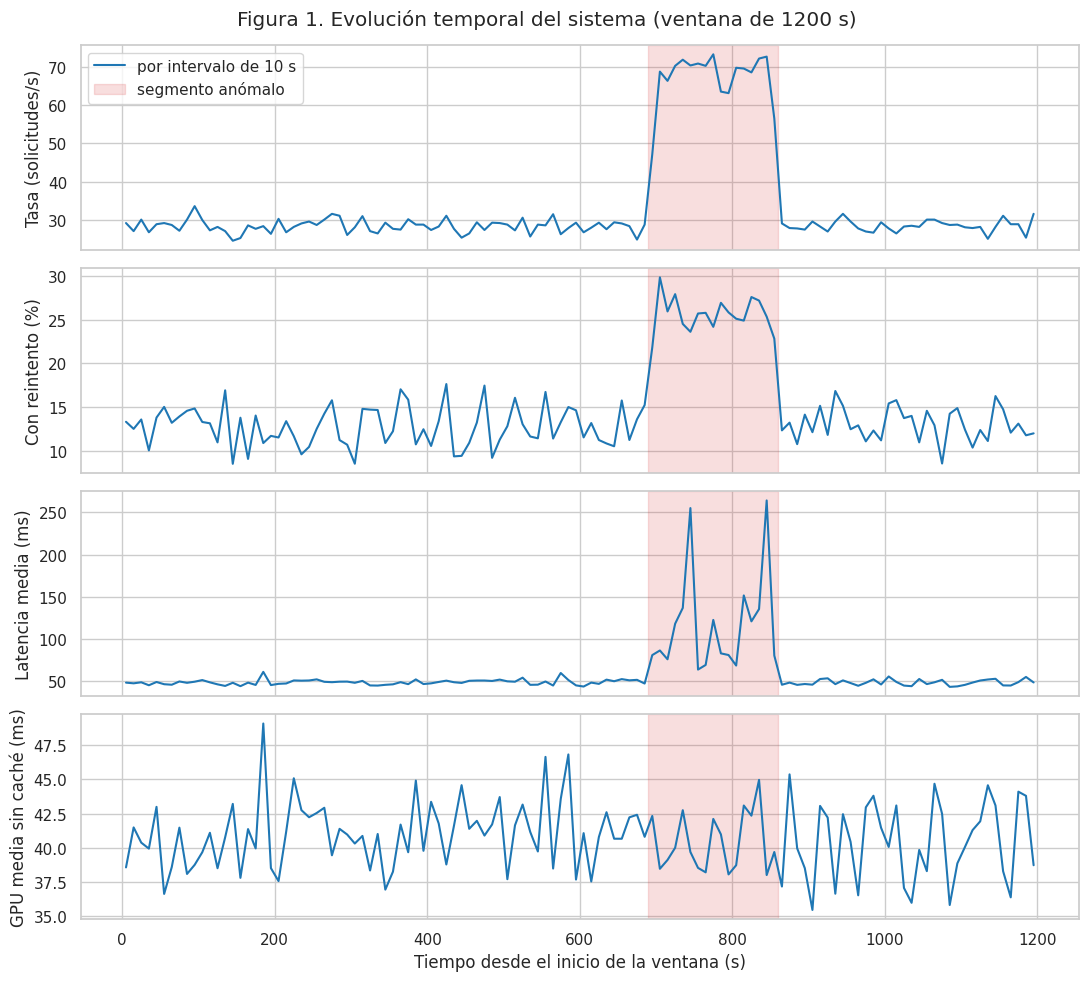

In [110]:
datos["intervalo"] = (datos["t_llegada_s"] // ancho).astype(int)  # indice del intervalo de 10 s
por_intervalo = datos.groupby("intervalo").agg(  # agrupa por intervalo
    llegadas=("id_solicitud", "size"),  # llegadas por intervalo
    reintentos=("intentos", lambda x: (x > 1).mean()),  # proporcion de reintentos
    latencia=("latencia_ms", "mean"),  # latencia media
)
por_intervalo["gpu"] = datos[datos["cache_hit"] == 0].groupby("intervalo")["gpu_ms"].mean()  # gpu media sin cache
tiempo_centro = por_intervalo.index * ancho + ancho / 2  # centro de cada intervalo en s

fig, ejes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)  # figura con 4 paneles
series = [  # series a graficar
    (por_intervalo["llegadas"] / ancho, "Tasa (solicitudes/s)"),  # tasa de llegadas por segundo
    (por_intervalo["reintentos"] * 100, "Con reintento (%)"),  # porcentaje con reintento
    (por_intervalo["latencia"], "Latencia media (ms)"),  # latencia media
    (por_intervalo["gpu"], "GPU media sin caché (ms)"),  # gpu media sin cache
]
for eje, (valores, etiqueta) in zip(ejes, series):  # un panel por serie
    eje.plot(tiempo_centro, valores, color="tab:blue", label="por intervalo de 10 s")  # dibuja la serie
    eje.axvspan(inicio_anomalo, fin_anomalo, color="tab:red", alpha=0.15, label="segmento anómalo")  # sombrea el segmento anomalo
    eje.set_ylabel(etiqueta)  # etiqueta del eje y
ejes[0].legend(loc="upper left")  # leyenda en el primer panel
ejes[-1].set_xlabel("Tiempo desde el inicio de la ventana (s)")  # etiqueta del eje x
fig.suptitle("Figura 1. Evolución temporal del sistema (ventana de 1200 s)")  # titulo general
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de Figura 1.* Entre ~690 y ~860 s la tasa de llegadas se dispara, los reintentos casi se duplican y la latencia media sube mucho, pero el tiempo de GPU por solicitud no cambia. El lector debe concluir que el episodio es una ráfaga de tráfico que congestiona la cola, no una GPU más lenta, y que fuera de esa franja el sistema es estable.

**Conclusión A3.** La latencia es la variable que más cambia entre regímenes: en el anómalo su media se duplica con creces y su desviación estándar casi se cuadruplica, por la espera en cola. `gpu_ms`, `red_ms` y `tam_kb` tienen resúmenes casi iguales en ambos regímenes, así que lo que cambia en el episodio anómalo es la carga, no el costo de cada solicitud. `gpu_ms` y `latencia_ms` son muy asimétricas a la derecha y con curtosis alta (colas pesadas); `tam_kb` también es asimétrica, pero menos. `red_ms` es casi simétrica (asimetría y curtosis cercanas a 0), lo que anticipa que podría ser normal (C3). Entre versiones, la B muestra un tiempo medio de GPU unos 4 a 5 ms menor que la A en ambos regímenes, sin diferencias en red ni en tamaño; esto se analiza formalmente en F3.

# Parte B — Llegadas, fallos y reintentos

Desde aquí trabajamos con el régimen estable definido en A2: [0, 690) ∪ [860, 1200] s, que dura 1030 s. Creamos las tablas que se usan en el resto del notebook y el valor z del nivel de confianza del grupo.

In [111]:
estable = datos[datos["regimen"] == "estable"].copy()  # regimen estable de A2
anomalo = datos[datos["regimen"] == "anomalo"].copy()  # solicitudes del regimen anomalo
z = stats.norm.ppf(1 - alpha / 2)  # valor critico para intervalos al nivel 1 - alpha
print("solicitudes en regimen estable:", len(estable), " duracion:", duracion_estable, "s")  # imprime tamano y duracion estable
print("solicitudes en regimen anomalo:", len(anomalo), " duracion:", duracion_anomalo, "s")  # imprime tamano y duracion anomala
print("nivel de confianza:", confianza, " z =", round(z, 4))  # imprime nivel y z

solicitudes en regimen estable: 29387  duracion: 1030.0 s
solicitudes en regimen anomalo: 11442  duracion: 170.0 s
nivel de confianza: 0.9  z = 1.6449


## B1. Modelo del proceso de llegadas

Proponemos un **proceso de Poisson homogéneo** con tasa λ: los tiempos entre llegadas son exponenciales independientes con media 1/λ y el número de llegadas en un intervalo de largo h es Poisson(λh). El estimador de máxima verosimilitud de λ observando una ventana de duración T es λ̂ = n / T. El intervalo de confianza exacto sale de la relación entre la Poisson y la chi-cuadrado (intervalo de Garwood).

Los tiempos entre llegadas se calculan **dentro** de cada tramo estable, para no contar el hueco del segmento anómalo como un tiempo entre llegadas.

In [112]:
llegadas_antes = estable.loc[estable["t_llegada_s"] < inicio_anomalo, "t_llegada_s"].values  # llegadas estables antes de la ventana
llegadas_despues = estable.loc[estable["t_llegada_s"] >= fin_anomalo, "t_llegada_s"].values  # llegadas estables despues de la ventana
tiempos_entre_llegadas = np.concatenate([np.diff(llegadas_antes), np.diff(llegadas_despues)])  # en segundos

n_llegadas = len(estable)  # total de llegadas estables
lambda_hat = n_llegadas / duracion_estable  # EMV de la tasa (sol/s)
lambda_inf = stats.chi2.ppf(alpha / 2, 2 * n_llegadas) / (2 * duracion_estable)  # Garwood
lambda_sup = stats.chi2.ppf(1 - alpha / 2, 2 * n_llegadas + 2) / (2 * duracion_estable)  # limite superior de Garwood

print("numero de tiempos entre llegadas:", len(tiempos_entre_llegadas))  # imprime cuantos tiempos hay
print("media de los tiempos entre llegadas:", round(tiempos_entre_llegadas.mean() * 1000, 3), "ms")  # media en ms
print("coeficiente de variacion (exponencial = 1):", round(tiempos_entre_llegadas.std() / tiempos_entre_llegadas.mean(), 4))  # desv/media: vale 1 si es exponencial
print(f"lambda = {lambda_hat:.3f} [{lambda_inf:.3f}, {lambda_sup:.3f}] sol/s, nivel {confianza}, metodo exacto chi-cuadrado (Garwood)")  # lambda con su IC
print(f"media entre llegadas 1/lambda = {1000 / lambda_hat:.3f} [{1000 / lambda_sup:.3f}, {1000 / lambda_inf:.3f}] ms, mismo nivel y metodo (transformado)")  # media entre llegadas con su IC

numero de tiempos entre llegadas: 29385
media de los tiempos entre llegadas: 35.038 ms
coeficiente de variacion (exponencial = 1): 1.0052
lambda = 28.531 [28.258, 28.806] sol/s, nivel 0.9, metodo exacto chi-cuadrado (Garwood)
media entre llegadas 1/lambda = 35.050 [34.715, 35.388] ms, mismo nivel y metodo (transformado)


**Validación 1 — tiempos entre llegadas (prueba KS).** Comparamos la distribución empírica de los tiempos entre llegadas con una exponencial de tasa λ̂. Como λ se estimó con los mismos datos, el p-valor de la tabla KS es optimista; por eso calculamos el p-valor por **bootstrap paramétrico**: simulamos muestras exponenciales del mismo tamaño, re-estimamos λ en cada una y vemos qué tan seguido el estadístico KS simulado supera al observado.

In [113]:
ks_observado = stats.kstest(tiempos_entre_llegadas, "expon", args=(0, 1 / lambda_hat)).statistic  # KS contra exponencial ajustada
print("estadistico KS observado:", round(ks_observado, 5))  # imprime el KS observado

replicas_ks = 300  # suficiente para un p-valor con error estandar menor a 0.03
ks_simulados = np.zeros(replicas_ks)  # vector de KS simulados
for i in range(replicas_ks):  # repite el bootstrap
    muestra = rng.exponential(1 / lambda_hat, size=len(tiempos_entre_llegadas))  # muestra exponencial simulada
    tasa_muestra = 1 / muestra.mean()  # re-estimar como con los datos reales
    ks_simulados[i] = stats.kstest(muestra, "expon", args=(0, 1 / tasa_muestra)).statistic  # KS de la muestra simulada
p_ks_bootstrap = (ks_simulados >= ks_observado).mean()  # fraccion de KS simulados >= observado
print("p-valor KS por bootstrap parametrico:", round(p_ks_bootstrap, 3))  # imprime el p-valor

estadistico KS observado: 0.00428
p-valor KS por bootstrap parametrico: 0.457


**Validación 2 — conteos por segundo (chi-cuadrado de bondad de ajuste).** Contamos las llegadas en cada segundo del régimen estable (1030 intervalos) y comparamos las frecuencias observadas con las esperadas bajo Poisson(λ̂·1 s). Agrupamos las colas para que cada categoría tenga frecuencia esperada de al menos 5. Los grados de libertad son (categorías − 1 − 1) porque estimamos λ.

In [114]:
segundos_estables = np.r_[np.arange(0, inicio_anomalo), np.arange(fin_anomalo, 1200)]  # inicio de cada segundo estable
conteos_por_segundo = np.zeros(len(segundos_estables), dtype=int)  # conteos por segundo
segundo_de_llegada = np.floor(estable["t_llegada_s"].values).astype(int)  # segundo al que pertenece cada llegada
for i, segundo in enumerate(segundos_estables):  # recorre cada segundo estable
    conteos_por_segundo[i] = (segundo_de_llegada == segundo).sum()  # cuenta llegadas de ese segundo

media_seg = conteos_por_segundo.mean()  # media de los conteos
var_seg = conteos_por_segundo.var(ddof=1)  # varianza de los conteos
print("media por segundo:", round(media_seg, 3), " varianza:", round(var_seg, 3), " indice de dispersion:", round(var_seg / media_seg, 3))  # imprime media, varianza e indice

limite_bajo = int(stats.poisson.ppf(0.01, lambda_hat))  # agrupar cola izquierda
limite_alto = int(stats.poisson.ppf(0.99, lambda_hat))  # agrupar cola derecha
valores = np.arange(limite_bajo, limite_alto + 1)  # valores del conteo a evaluar
observadas = []  # frecuencias observadas
esperadas = []  # frecuencias esperadas
for v in valores:  # recorre cada valor
    if v == limite_bajo:  # primera categoria agrupa la cola izquierda
        observadas.append((conteos_por_segundo <= v).sum())  # observadas <= v
        esperadas.append(stats.poisson.cdf(v, lambda_hat) * len(conteos_por_segundo))  # esperadas Poisson acumuladas
    elif v == limite_alto:  # ultima categoria agrupa la cola derecha
        observadas.append((conteos_por_segundo >= v).sum())  # observadas >= v
        esperadas.append(stats.poisson.sf(v - 1, lambda_hat) * len(conteos_por_segundo))  # esperadas de la cola derecha
    else:  # cualquier otro valor
        observadas.append((conteos_por_segundo == v).sum())  # observadas == v
        esperadas.append(stats.poisson.pmf(v, lambda_hat) * len(conteos_por_segundo))  # esperadas Poisson puntuales
observadas = np.array(observadas)  # a arreglo numpy
esperadas = np.array(esperadas)  # a arreglo numpy
chi2_conteos = ((observadas - esperadas) ** 2 / esperadas).sum()  # estadistico chi-cuadrado
gl_conteos = len(valores) - 2  # grados de libertad (k - 1 - 1 parametro)
p_conteos = stats.chi2.sf(chi2_conteos, gl_conteos)  # p-valor
print("categorias:", len(valores), " menor esperada:", round(esperadas.min(), 1))  # imprime categorias
print("chi-cuadrado =", round(chi2_conteos, 2), " gl =", gl_conteos, " p-valor =", round(p_conteos, 3))  # imprime chi-cuadrado y p-valor

estadistico_disp_seg = (len(conteos_por_segundo) - 1) * var_seg / media_seg  # estadistico de dispersion
p_disp_seg = 2 * min(stats.chi2.sf(estadistico_disp_seg, len(conteos_por_segundo) - 1),  # p-valor a dos colas
                     stats.chi2.cdf(estadistico_disp_seg, len(conteos_por_segundo) - 1))  # cola inferior
print("prueba de dispersion por segundo: p-valor (dos colas) =", round(p_disp_seg, 3))  # imprime el p-valor

media por segundo: 28.531  varianza: 28.329  indice de dispersion: 0.993
categorias: 26  menor esperada: 5.8
chi-cuadrado = 18.71  gl = 24  p-valor = 0.768
prueba de dispersion por segundo: p-valor (dos colas) = 0.884


**Validación 3 — independencia.** Un proceso de Poisson tiene tiempos entre llegadas independientes. Revisamos la autocorrelación de los tiempos entre llegadas consecutivos en los primeros rezagos; bajo independencia cada una debería estar dentro de ±z/√n.

In [115]:
banda = z / np.sqrt(len(tiempos_entre_llegadas))  # banda de +/- z/sqrt(n) para autocorrelacion
for rezago in [1, 2, 3, 5, 10]:  # prueba varios rezagos
    autocorr = np.corrcoef(tiempos_entre_llegadas[:-rezago], tiempos_entre_llegadas[rezago:])[0, 1]  # correlacion entre la serie y su desplazada
    print("rezago", rezago, " autocorrelacion =", round(autocorr, 4), " dentro de la banda:", abs(autocorr) < banda)  # imprime si cae dentro de la banda
print("banda: +/-", round(banda, 4))  # imprime la banda

rezago 1  autocorrelacion = -0.0025  dentro de la banda: True
rezago 2  autocorrelacion = 0.0021  dentro de la banda: True
rezago 3  autocorrelacion = -0.0036  dentro de la banda: True
rezago 5  autocorrelacion = -0.0061  dentro de la banda: True
rezago 10  autocorrelacion = -0.0023  dentro de la banda: True
banda: +/- 0.0096


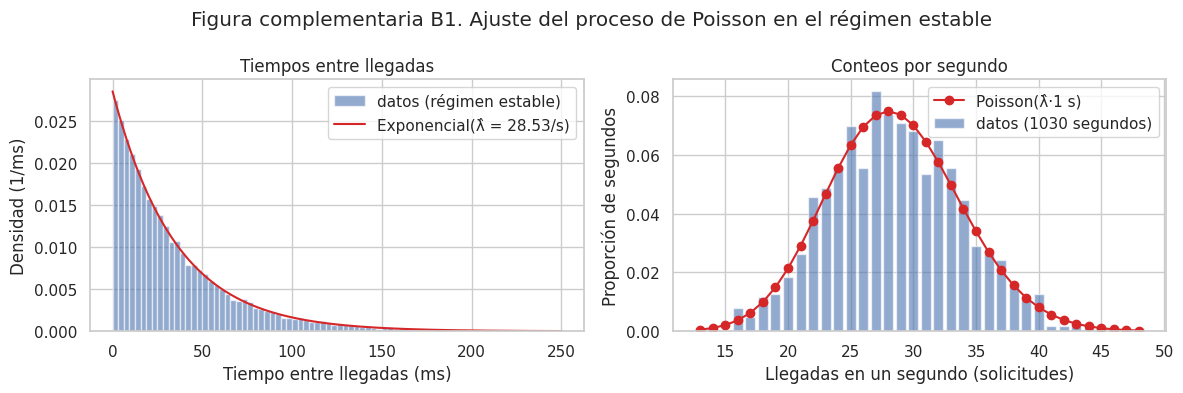

In [116]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))  # dos paneles
x_ms = np.linspace(0, 250, 300)  # eje x en ms
ejes[0].hist(tiempos_entre_llegadas * 1000, bins=80, range=(0, 250), density=True, alpha=0.6, label="datos (régimen estable)")  # histograma de tiempos entre llegadas
ejes[0].plot(x_ms, lambda_hat / 1000 * np.exp(-lambda_hat * x_ms / 1000), color="tab:red", label=f"Exponencial(λ̂ = {lambda_hat:.2f}/s)")  # curva exponencial ajustada
ejes[0].set_xlabel("Tiempo entre llegadas (ms)")  # etiqueta x
ejes[0].set_ylabel("Densidad (1/ms)")  # etiqueta y
ejes[0].set_title("Tiempos entre llegadas")  # titulo
ejes[0].legend()  # leyenda

valores_k = np.arange(conteos_por_segundo.min(), conteos_por_segundo.max() + 1)  # valores posibles del conteo
frec_obs = np.array([(conteos_por_segundo == k).mean() for k in valores_k])  # frecuencia observada de cada valor
ejes[1].bar(valores_k, frec_obs, alpha=0.6, label="datos (1030 segundos)")  # barras de los datos
ejes[1].plot(valores_k, stats.poisson.pmf(valores_k, lambda_hat), "o-", color="tab:red", label="Poisson(λ̂·1 s)")  # curva Poisson teorica
ejes[1].set_xlabel("Llegadas en un segundo (solicitudes)")  # etiqueta x
ejes[1].set_ylabel("Proporción de segundos")  # etiqueta y
ejes[1].set_title("Conteos por segundo")  # titulo
ejes[1].legend()  # leyenda
fig.suptitle("Figura complementaria B1. Ajuste del proceso de Poisson en el régimen estable")  # titulo general
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de figura complementaria B1.* Tanto el histograma de tiempos entre llegadas como la distribución de conteos por segundo siguen de cerca las curvas teóricas. El lector debe concluir que el proceso de Poisson describe bien las llegadas del régimen estable.

**Conclusión B1.** En el régimen estable las llegadas se modelan como un proceso de Poisson. Tres vías cuantitativas distintas no encuentran evidencia contra el modelo: la prueba KS de los tiempos entre llegadas con p-valor por bootstrap, la chi-cuadrado de los conteos por segundo con su prueba de dispersión, y la autocorrelación. El coeficiente de variación de los tiempos entre llegadas es prácticamente 1, como en la exponencial. La tasa estimada y su intervalo aparecen arriba en el formato pedido.

## B2. Solicitudes con más de un intento por bloque de 100

Si cada solicitud necesita más de un intento con la misma probabilidad p, independientemente de las demás, el número de ellas en un bloque de 100 solicitudes consecutivas es **Binomial(100, p)**. Armamos los bloques dentro de cada régimen por separado, estimamos p en cada uno y contrastamos el modelo de tres formas: media y varianza contra las de la binomial, prueba de dispersión y chi-cuadrado de bondad de ajuste.

In [117]:
def conteos_por_bloque(tabla, tamano_bloque):  # cuenta reintentos por bloque de solicitudes
    con_reintento = (tabla["intentos"].values > 1).astype(int)  # 1 si necesito mas de un intento
    num_bloques = len(con_reintento) // tamano_bloque  # se descarta el bloque incompleto del final
    return con_reintento[:num_bloques * tamano_bloque].reshape(num_bloques, tamano_bloque).sum(axis=1)  # suma de reintentos por bloque


def chi2_binomial(conteos, n_ensayos, p):  # chi-cuadrado contra binomial
    # agrupa en ~6 categorias de probabilidad parecida para que las esperadas sean grandes
    cortes = np.unique(stats.binom.ppf([1 / 6, 2 / 6, 3 / 6, 4 / 6, 5 / 6], n_ensayos, p))  # cortes que dan categorias equiprobables
    observadas = []  # observadas por categoria
    esperadas = []  # esperadas por categoria
    anterior = -1  # limite inferior previo
    for corte in list(cortes) + [n_ensayos]:  # recorre cada corte
        observadas.append(((conteos > anterior) & (conteos <= corte)).sum())  # cuenta bloques en la categoria
        esperadas.append((stats.binom.cdf(corte, n_ensayos, p) - stats.binom.cdf(anterior, n_ensayos, p)) * len(conteos))  # esperado binomial de la categoria
        anterior = corte  # avanza el limite
    observadas = np.array(observadas)  # a arreglo numpy
    esperadas = np.array(esperadas)  # a arreglo numpy
    estadistico = ((observadas - esperadas) ** 2 / esperadas).sum()  # estadistico chi-cuadrado
    gl = len(observadas) - 2  # se estimo p
    return estadistico, gl, stats.chi2.sf(estadistico, gl)  # devuelve estadistico, gl y p-valor

In [118]:
tamano_bloque = 100  # solicitudes por bloque
filas_b2 = []  # filas de resultados
bloques = {}  # conteos por bloque de cada conjunto
for nombre, tabla in [("estable", estable), ("anomalo", anomalo), ("ventana completa", datos)]:  # estable, anomalo y completo
    conteos_b = conteos_por_bloque(tabla, tamano_bloque)  # reintentos por bloque
    bloques[nombre] = conteos_b  # guarda los conteos
    p_bloque = conteos_b.sum() / (len(conteos_b) * tamano_bloque)  # proporcion estimada de reintentos
    var_binomial = tamano_bloque * p_bloque * (1 - p_bloque)  # varianza si fuera binomial
    razon_var = conteos_b.var(ddof=1) / var_binomial  # razon varianza observada / binomial
    estad_disp = (len(conteos_b) - 1) * razon_var  # estadistico de dispersion
    p_disp_b = stats.chi2.sf(estad_disp, len(conteos_b) - 1)  # una cola: sobredispersion
    chi2_b, gl_b, p_chi2_b = chi2_binomial(conteos_b, tamano_bloque, p_bloque)  # bondad de ajuste binomial
    filas_b2.append([nombre, len(conteos_b), p_bloque, conteos_b.mean(), conteos_b.var(ddof=1), var_binomial,  # guarda la fila
                     razon_var, p_disp_b, chi2_b, gl_b, p_chi2_b])
tabla_b2 = pd.DataFrame(filas_b2, columns=["datos", "bloques", "p estimado", "media", "varianza", "var binomial",  # arma la tabla
                                            "razon var", "p dispersion", "chi2", "gl", "p chi2"])
print(tabla_b2.round(4).to_string(index=False))  # imprime la tabla

           datos  bloques  p estimado   media  varianza  var binomial  razon var  p dispersion     chi2  gl  p chi2
         estable      293      0.1288 12.8840   13.3427       11.2240     1.1888        0.0147   6.8489   4  0.1441
         anomalo      114      0.2575 25.7456   24.5276       19.1172     1.2830        0.0229   3.9117   4  0.4181
ventana completa      408      0.1647 16.4657   48.8145       13.7545     3.5490        0.0000 192.7483   4  0.0000


Ahora cuantificamos la discrepancia principal: ¿la probabilidad de reintento es la misma en los dos regímenes? Construimos el intervalo de la diferencia de proporciones (Wald para dos muestras) y revisamos si la proporción de reintentos sube con la carga, correlacionando la tasa de llegadas y la proporción de reintentos en los intervalos de 10 s de toda la ventana.

In [119]:
p_est = (estable["intentos"] > 1).mean()  # proporcion de reintentos en estable
p_anom = (anomalo["intentos"] > 1).mean()  # proporcion de reintentos en anomalo
error_dif = np.sqrt(p_est * (1 - p_est) / len(estable) + p_anom * (1 - p_anom) / len(anomalo))  # error estandar de la diferencia
dif_p = p_anom - p_est  # diferencia de proporciones
print(f"p(mas de un intento) estable = {p_est:.4f}, anomalo = {p_anom:.4f}")  # imprime ambas proporciones
print(f"diferencia anomalo - estable = {dif_p:.4f} [{dif_p - z * error_dif:.4f}, {dif_p + z * error_dif:.4f}], nivel {confianza}, metodo Wald dos muestras")  # IC de la diferencia (Wald)

tasa_10s = por_intervalo["llegadas"] / ancho  # de la Figura 1
reint_10s = por_intervalo["reintentos"]  # proporcion de reintentos por intervalo
correlacion_carga = stats.pearsonr(tasa_10s, reint_10s)  # Pearson entre tasa y reintentos
print("correlacion entre tasa de llegadas y proporcion de reintentos (intervalos de 10 s):",  # imprime la correlacion
      round(correlacion_carga.statistic, 3), " p-valor:", correlacion_carga.pvalue)

p_mezcla = bloques["ventana completa"].mean() / tamano_bloque  # proporcion en la ventana completa
var_esperada_mezcla = tamano_bloque * p_mezcla * (1 - p_mezcla)  # varianza esperada si fuera binomial
print("varianza de bloques en la ventana completa:", round(bloques["ventana completa"].var(ddof=1), 2),  # imprime varianza observada
      " vs binomial con p comun:", round(var_esperada_mezcla, 2))

p(mas de un intento) estable = 0.1288, anomalo = 0.2568
diferencia anomalo - estable = 0.1280 [0.1206, 0.1355], nivel 0.9, metodo Wald dos muestras
correlacion entre tasa de llegadas y proporcion de reintentos (intervalos de 10 s): 0.906  p-valor: 8.759634399353115e-46
varianza de bloques en la ventana completa: 48.81  vs binomial con p comun: 13.75


In [120]:
autocorr_reint = []  # autocorrelaciones
con_reintento_est = (estable["intentos"].values > 1).astype(float)  # 1 si hubo reintento
for rezago in [1, 2, 5, 10]:  # prueba varios rezagos
    autocorr_reint.append(np.corrcoef(con_reintento_est[:-rezago], con_reintento_est[rezago:])[0, 1])  # guarda la autocorrelacion
banda_reint = z / np.sqrt(len(con_reintento_est))  # banda de independencia
print("autocorrelacion de 'mas de un intento' en el regimen estable (rezagos 1, 2, 5, 10):", np.round(autocorr_reint, 4))  # imprime autocorrelaciones
print("banda de independencia: +/-", round(banda_reint, 4))  # imprime la banda

autocorrelacion de 'mas de un intento' en el regimen estable (rezagos 1, 2, 5, 10): [0.0017 0.0066 0.0051 0.0052]
banda de independencia: +/- 0.0096


**Conclusión B2.** Dentro de cada régimen, el modelo Binomial(100, p) reproduce bien la media de los bloques, pero con un p distinto en cada uno: cerca de 0,13 en el estable y cerca de 0,26 en el anómalo. La diferencia está bien determinada por el intervalo de arriba. En la ventana completa los bloques muestran una sobredispersión fuerte: es el efecto de mezclar dos binomiales con p distinto (la varianza total suma la varianza entre regímenes). La proporción de reintentos sube con la tasa de llegadas, como se espera si la congestión provoca fallos por tiempo de espera, así que la discrepancia tiene una explicación física y no es un error del modelo. Dentro de cada régimen queda una sobredispersión leve (razón de varianzas de 1,2 a 1,3), que la prueba de dispersión detecta al nivel del grupo, aunque la chi-cuadrado de bondad de ajuste no rechaza la forma binomial. Las autocorrelaciones individuales son muy pequeñas, pero positivas en varios rezagos, y eso basta para inflar un poco la varianza de una suma de 100 indicadores. Para las partes siguientes lo tomamos como una limitación menor: el efecto en la media es nulo y en la varianza es de alrededor del 20 %.

## B3. Modelo de la variable `intentos` y su estimador de máxima verosimilitud

**Modelo.** Cada intento falla con probabilidad q, de forma independiente. El SDK reintenta hasta tener éxito o hasta completar 3 fallos. Por eso `intentos` es una geométrica **truncada en 3**, y además vemos `exito`, que distingue "éxito al tercer intento" de "abandono":

| Caso observado | Probabilidad | Intentos fallidos | Éxitos |
|---|---|---|---|
| intentos = 1 | 1 − q | 0 | 1 |
| intentos = 2 | q(1 − q) | 1 | 1 |
| intentos = 3, exito = 1 | q²(1 − q) | 2 | 1 |
| intentos = 3, exito = 0 | q³ | 3 | 0 |

**Verosimilitud.** Si F es el total de intentos fallidos y E el total de intentos exitosos (uno por cada solicitud con éxito), cada solicitud aporta q^(fallos)(1 − q)^(éxito), y entonces

L(q) = q^F (1 − q)^E,  ℓ(q) = F log q + E log(1 − q).

Derivando e igualando a cero: F/q − E/(1 − q) = 0, de donde **q̂ = F / (F + E) = intentos fallidos / intentos totales**. La información observada es F/q² + E/(1 − q)², que evaluada en q̂ vale A / (q̂(1 − q̂)) con A = F + E el total de intentos. Por eso Var(q̂) ≈ q̂(1 − q̂) / A.

El **estimador ingenuo** ignora el truncamiento: supone que `intentos` es geométrica sin límite, con E[I] = 1/(1 − q), y despeja q̃ = 1 − 1/Ī.

In [121]:
intentos_est = estable["intentos"].values  # intentos de cada solicitud estable
exito_est = estable["exito"].values  # exito de cada solicitud estable
intentos_totales = intentos_est.sum()  # A
intentos_exitosos = exito_est.sum()  # E (uno por solicitud exitosa)
intentos_fallidos = intentos_totales - intentos_exitosos  # F

q_hat = intentos_fallidos / intentos_totales  # EMV
error_q = np.sqrt(q_hat * (1 - q_hat) / intentos_totales)  # error estandar de q
q_ingenuo = 1 - 1 / intentos_est.mean()  # estimador ingenuo sesgado

print("intentos totales A =", intentos_totales, " fallidos F =", intentos_fallidos, " exitosos E =", intentos_exitosos)  # imprime A, F y E
print(f"q (EMV) = {q_hat:.4f} [{q_hat - z * error_q:.4f}, {q_hat + z * error_q:.4f}], nivel {confianza}, metodo Wald con informacion observada")  # q con su IC Wald
print(f"q ingenuo (1 - 1/promedio) = {q_ingenuo:.4f}")  # imprime el ingenuo

intentos totales A = 33667  fallidos F = 4327  exitosos E = 29340
q (EMV) = 0.1285 [0.1255, 0.1315], nivel 0.9, metodo Wald con informacion observada
q ingenuo (1 - 1/promedio) = 0.1271


Comprobamos la fórmula cerrada maximizando numéricamente la log-verosimilitud, y revisamos con una chi-cuadrado si el modelo reproduce las frecuencias de los cuatro casos (gl = 4 − 1 − 1 = 2).

In [122]:
def menos_log_ver_intentos(parametro):  # menos log-verosimilitud de q
    q = parametro[0]  # extrae q del vector
    return -(intentos_fallidos * np.log(q) + intentos_exitosos * np.log(1 - q))  # devuelve -log L


resultado_q = optimize.minimize(menos_log_ver_intentos, x0=[0.5], bounds=[(1e-6, 1 - 1e-6)])  # minimiza numericamente
print("q por optimizacion numerica:", round(resultado_q.x[0], 6), " q por formula:", round(q_hat, 6))  # compara con la formula cerrada

casos_obs = np.array([  # casos observados
    (intentos_est == 1).sum(),  # un intento
    (intentos_est == 2).sum(),  # dos intentos
    ((intentos_est == 3) & (exito_est == 1)).sum(),  # tres intentos con exito
    ((intentos_est == 3) & (exito_est == 0)).sum(),  # tres intentos y abandono
])
prob_casos = np.array([1 - q_hat, q_hat * (1 - q_hat), q_hat ** 2 * (1 - q_hat), q_hat ** 3])  # probabilidades teoricas
casos_esp = prob_casos * len(intentos_est)  # casos esperados
chi2_intentos = ((casos_obs - casos_esp) ** 2 / casos_esp).sum()  # estadistico chi-cuadrado
p_intentos = stats.chi2.sf(chi2_intentos, 2)  # p-valor con 2 gl
print(pd.DataFrame({"caso": ["I=1", "I=2", "I=3 exito", "I=3 abandono"], "observado": casos_obs, "esperado": casos_esp.round(1)}).to_string(index=False))  # tabla observado contra esperado
print("chi-cuadrado =", round(chi2_intentos, 2), " gl = 2  p-valor =", round(p_intentos, 3))  # imprime chi-cuadrado y p-valor

q por optimizacion numerica: 0.128523  q por formula: 0.128523
        caso  observado  esperado
         I=1      25603   25610.1
         I=2       3288    3291.5
   I=3 exito        449     423.0
I=3 abandono         47      62.4
chi-cuadrado = 5.39  gl = 2  p-valor = 0.067


El p-valor queda por debajo de α = 0,10, así que al nivel del grupo hay evidencia (débil) contra el modelo de q constante. Las mayores diferencias están en el tercer intento: hay más éxitos y menos abandonos de los esperados. Para medirlo, ajustamos un modelo más general con una probabilidad de fallo distinta en cada intento (q1, q2, q3). Su EMV es la proporción de fallos entre los intentos de ese número. Lo comparamos con el de q constante mediante una razón de verosimilitud con 2 grados de libertad.

In [123]:
llegaron_a_2 = (intentos_est >= 2).sum()  # hicieron segundo intento = fallaron el primero
llegaron_a_3 = (intentos_est == 3).sum()  # llegaron al tercer intento
abandonos = ((intentos_est == 3) & (exito_est == 0)).sum()  # abandonaron tras 3 intentos
ensayos_por_intento = np.array([len(intentos_est), llegaron_a_2, llegaron_a_3])  # cuantos hicieron el intento 1, 2 y 3
fallos_por_intento = np.array([llegaron_a_2, llegaron_a_3, abandonos])  # fallos en cada intento
q_por_intento = fallos_por_intento / ensayos_por_intento  # q de cada intento
for j in range(3):  # recorre los tres intentos
    error_j = np.sqrt(q_por_intento[j] * (1 - q_por_intento[j]) / ensayos_por_intento[j])  # error estandar de q_j
    print(f"q{j + 1} = {q_por_intento[j]:.4f} [{q_por_intento[j] - z * error_j:.4f}, {q_por_intento[j] + z * error_j:.4f}], nivel {confianza}, Wald  (n = {ensayos_por_intento[j]})")  # imprime q_j con su IC

log_ver_general = (fallos_por_intento * np.log(q_por_intento) + (ensayos_por_intento - fallos_por_intento) * np.log(1 - q_por_intento)).sum()  # log-verosimilitud con q distinta por intento
log_ver_constante = intentos_fallidos * np.log(q_hat) + intentos_exitosos * np.log(1 - q_hat)  # log-verosimilitud con q constante
razon_intentos = 2 * (log_ver_general - log_ver_constante)  # razon de verosimilitud
print("razon de verosimilitud =", round(razon_intentos, 2), " gl = 2  p-valor =", round(stats.chi2.sf(razon_intentos, 2), 3))  # imprime razon y p-valor
print("fraccion de solicitudes que llegan al tercer intento:", round(llegaron_a_3 / len(intentos_est), 4))  # fraccion que llega al tercer intento

q1 = 0.1288 [0.1256, 0.1320], nivel 0.9, Wald  (n = 29387)
q2 = 0.1311 [0.1221, 0.1401], nivel 0.9, Wald  (n = 3784)
q3 = 0.0948 [0.0731, 0.1164], nivel 0.9, Wald  (n = 496)
razon de verosimilitud = 5.72  gl = 2  p-valor = 0.057
fraccion de solicitudes que llegan al tercer intento: 0.0169


**Simulación calibrada.** Generamos muchas muestras del mismo tamaño que el régimen estable con q = q̂, aplicando el mismo mecanismo del SDK (máximo 3 intentos), y en cada una calculamos los dos estimadores. Así medimos el sesgo, la dispersión, el error cuadrático medio y la cobertura del intervalo de cada uno. Con truncamiento, E[I] = 1 + q + q², así que el ingenuo converge a 1 − 1/(1 + q + q²), que es menor que q: se espera un sesgo negativo que no desaparece con más datos.

In [124]:
replicas_b3 = 2000  # numero de replicas
n_solicitudes = len(intentos_est)  # solicitudes por replica
q_emv_sim = np.zeros(replicas_b3)  # EMV simulados
q_ing_sim = np.zeros(replicas_b3)  # ingenuos simulados
cubre_emv = np.zeros(replicas_b3)  # cubrimiento del IC del EMV
cubre_ing = np.zeros(replicas_b3)  # cubrimiento del IC del ingenuo
for i in range(replicas_b3):  # repite el experimento
    intentos_hasta_exito = rng.geometric(1 - q_hat, size=n_solicitudes)  # sin limite del SDK
    intentos_sim = np.minimum(intentos_hasta_exito, 3)  # el SDK corta en 3
    exito_sim = (intentos_hasta_exito <= 3).astype(int)  # 1 si tuvo exito dentro de 3
    total_sim = intentos_sim.sum()  # intentos totales simulados
    q_emv_sim[i] = (total_sim - exito_sim.sum()) / total_sim  # EMV de la replica
    media_sim = intentos_sim.mean()  # promedio de intentos
    q_ing_sim[i] = 1 - 1 / media_sim  # ingenuo de la replica
    error_emv = np.sqrt(q_emv_sim[i] * (1 - q_emv_sim[i]) / total_sim)  # error estandar del EMV
    error_ing = intentos_sim.std(ddof=1) / np.sqrt(n_solicitudes) / media_sim ** 2  # metodo delta para 1 - 1/media
    cubre_emv[i] = abs(q_emv_sim[i] - q_hat) <= z * error_emv  # ¿el IC del EMV cubre a q?
    cubre_ing[i] = abs(q_ing_sim[i] - q_hat) <= z * error_ing  # ¿el IC del ingenuo cubre a q?

limite_ingenuo = 1 - 1 / (1 + q_hat + q_hat ** 2)  # limite teorico del ingenuo
tabla_b3 = pd.DataFrame({  # tabla de resultados
    "estimador": ["EMV (con truncamiento)", "ingenuo (1 - 1/promedio)"],
    "media simulada": [q_emv_sim.mean(), q_ing_sim.mean()],
    "sesgo": [q_emv_sim.mean() - q_hat, q_ing_sim.mean() - q_hat],
    "desv. est.": [q_emv_sim.std(), q_ing_sim.std()],
    "ECM raiz": [np.sqrt(((q_emv_sim - q_hat) ** 2).mean()), np.sqrt(((q_ing_sim - q_hat) ** 2).mean())],
    "cobertura IC": [cubre_emv.mean(), cubre_ing.mean()],
})
print("q verdadero en la simulacion:", round(q_hat, 4), " limite teorico del ingenuo:", round(limite_ingenuo, 4))  # imprime q y limite del ingenuo
print(tabla_b3.round(5).to_string(index=False))  # imprime la tabla
print("cobertura nominal:", confianza)  # imprime cobertura nominal

q verdadero en la simulacion: 0.1285  limite teorico del ingenuo: 0.1267
               estimador  media simulada    sesgo  desv. est.  ECM raiz  cobertura IC
  EMV (con truncamiento)         0.12858  0.00006     0.00182   0.00182        0.8955
ingenuo (1 - 1/promedio)         0.12673 -0.00179     0.00176   0.00251        0.7320
cobertura nominal: 0.9


Repetimos la comparación para varios valores de q, para ver cómo crece el problema cuando hay más fallos (por ejemplo, en el régimen anómalo q es cerca del doble).

In [125]:
filas_q = []  # filas de resultados
for q_prueba in [0.05, q_hat, 0.25, 0.40]:  # prueba varios q verdaderos
    estimaciones_emv = []  # EMV simulados
    estimaciones_ing = []  # ingenuos simulados
    for i in range(300):  # 300 replicas por q
        hasta_exito = rng.geometric(1 - q_prueba, size=n_solicitudes)  # intentos hasta exito
        intentos_sim = np.minimum(hasta_exito, 3)  # trunca en 3
        exitos = (hasta_exito <= 3).sum()  # exitos de la replica
        estimaciones_emv.append((intentos_sim.sum() - exitos) / intentos_sim.sum())  # guarda el EMV
        estimaciones_ing.append(1 - 1 / intentos_sim.mean())  # guarda el ingenuo
    filas_q.append([q_prueba, np.mean(estimaciones_emv) - q_prueba, np.mean(estimaciones_ing) - q_prueba,  # sesgos y desviacion
                    1 - 1 / (1 + q_prueba + q_prueba ** 2) - q_prueba, np.std(estimaciones_emv)])
print(pd.DataFrame(filas_q, columns=["q verdadero", "sesgo EMV", "sesgo ingenuo (sim)", "sesgo ingenuo (teorico)", "desv. est. EMV"]).round(5).to_string(index=False))  # imprime la tabla

 q verdadero  sesgo EMV  sesgo ingenuo (sim)  sesgo ingenuo (teorico)  desv. est. EMV
     0.05000   -0.00004             -0.00016                 -0.00012         0.00122
     0.12852   -0.00014             -0.00198                 -0.00185         0.00190
     0.25000   -0.00012             -0.01205                 -0.01190         0.00205
     0.40000    0.00023             -0.04088                 -0.04103         0.00223


**Conclusión B3.** El estimador de máxima verosimilitud que respeta cómo se generan los datos es simplemente la proporción de intentos fallidos sobre intentos totales, y la optimización numérica da el mismo valor. El modelo de q constante encaja muy bien en el primer y segundo intento. En el tercero hay menos fallos de los esperados, con evidencia débil (p cercano a 0,07, por debajo de α = 0,10). Como solo una pequeña fracción de solicitudes llega al tercer intento, eso casi no mueve q̂ ni P(I > 1) = q1. Mantenemos el modelo simple y lo anotamos como limitación: el SDK podría esperar más antes del tercer intento (backoff) y fallar menos ahí. El estimador ingenuo, basado en el promedio, tiene un sesgo negativo que no desaparece con más datos: con nuestro q ese sesgo es de un tamaño parecido al error estándar, por eso su intervalo cubre menos de lo nominal. Con más fallos (q = 0,25 o 0,40) el sesgo crece mucho. Conclusión: el estimador ingenuo **no** es adecuado.

## B4. Probabilidad de al menos k solicitudes con reintento en 10 s

**Planteamiento analítico.**
1. Las llegadas son un proceso de Poisson de tasa λ (B1): incrementos independientes y estacionarios.
2. Cada solicitud necesita más de un intento con probabilidad q (en el modelo de B3, P(I > 1) = q), independientemente del proceso de llegadas y de las demás solicitudes. Esto lo respaldan B2 (autocorrelaciones muy pequeñas) y lo que comprobamos abajo (la proporción no depende de la versión ni de la caché).
3. **Propiedad de adelgazamiento (thinning):** si a un proceso de Poisson de tasa λ se le marca cada punto de forma independiente con probabilidad q, los puntos marcados forman un proceso de Poisson de tasa λq.
4. Entonces X = número de solicitudes con reintento en 10 s ~ Poisson(μ) con μ = 10·λ·q, y P(X ≥ k) = 1 − Σ_{j=0}^{k−1} e^(−μ) μ^j / j!.

In [126]:
print("proporcion con mas de un intento por version:")  # titulo de la salida
print(estable.groupby("version")["intentos"].apply(lambda x: (x > 1).mean()).round(4))  # reintentos por version
print("proporcion con mas de un intento por cache_hit:")  # titulo de la salida
print(estable.groupby("cache_hit")["intentos"].apply(lambda x: (x > 1).mean()).round(4))  # reintentos por cache_hit

ventana_b4 = 10  # segundos
mu_hat = ventana_b4 * lambda_hat * q_hat  # media de solicitudes con reintento en 10 s
k_b4 = int(np.ceil(mu_hat)) + r  # umbral k = ceil(mu) + r
prob_analitica = stats.poisson.sf(k_b4 - 1, mu_hat)  # P(X >= k)
print()  # linea en blanco
print("mu =", round(mu_hat, 3), " k = ceil(mu) + r =", k_b4)  # imprime mu y k
print("P(X >= k) analitica =", round(prob_analitica, 5))  # imprime la probabilidad

proporcion con mas de un intento por version:
version
A    0.1281
B    0.1294
Name: intentos, dtype: float64
proporcion con mas de un intento por cache_hit:
cache_hit
0    0.1288
1    0.1286
Name: intentos, dtype: float64

mu = 36.669  k = ceil(mu) + r = 37
P(X >= k) analitica = 0.50013


**Verificación por Montecarlo.** Simulamos ventanas de 10 s desde cero: generamos tiempos entre llegadas exponenciales hasta pasar los 10 s y, para cada solicitud, sus intentos con el mecanismo del SDK. Contamos las que necesitaron más de un intento. Con 50 000 ventanas, el error estándar de la proporción simulada es menor que 0,0023.

In [127]:
ventanas_mc = 50000  # numero de ventanas simuladas
lote = 10000  # se simula por lotes para no usar demasiada memoria
max_llegadas = int(stats.poisson.ppf(1 - 1e-12, lambda_hat * ventana_b4))  # mas llegadas de las que caben en 10 s
cuentas_mc = []  # conteos de cada lote
for inicio_lote in range(0, ventanas_mc, lote):  # simula por lotes
    entre_llegadas = rng.exponential(1 / lambda_hat, size=(lote, max_llegadas))  # tiempos entre llegadas simulados
    instantes = np.cumsum(entre_llegadas, axis=1)  # instantes de llegada
    dentro = instantes < ventana_b4  # llegadas que caen en la ventana
    intentos_mc = np.minimum(rng.geometric(1 - q_hat, size=(lote, max_llegadas)), 3)  # intentos simulados con tope 3
    cuentas_mc.append(((intentos_mc > 1) & dentro).sum(axis=1))  # reintentos dentro de la ventana
cuentas_mc = np.concatenate(cuentas_mc)  # junta todos los lotes
prob_mc = (cuentas_mc >= k_b4).mean()  # P(X >= k) por Montecarlo
error_mc = np.sqrt(prob_mc * (1 - prob_mc) / ventanas_mc)  # error estandar de la estimacion

print(f"P(X >= {k_b4}) analitica   = {prob_analitica:.5f}")  # imprime la analitica
print(f"P(X >= {k_b4}) Montecarlo  = {prob_mc:.5f} [{prob_mc - z * error_mc:.5f}, {prob_mc + z * error_mc:.5f}], nivel {confianza}, Wald")  # imprime Montecarlo con IC
print("media simulada de X:", round(cuentas_mc.mean(), 3), " varianza:", round(cuentas_mc.var(), 3), " (Poisson: media = varianza =", round(mu_hat, 3), ")")  # imprime media y varianza simuladas

P(X >= 37) analitica   = 0.50013
P(X >= 37) Montecarlo  = 0.49664 [0.49296, 0.50032], nivel 0.9, Wald
media simulada de X: 36.655  varianza: 36.889  (Poisson: media = varianza = 36.669 )


In [128]:
ventanas_datos = []  # conteos observados por ventana
for inicio_v in list(np.arange(0, inicio_anomalo, ventana_b4)) + list(np.arange(fin_anomalo, 1200 - ventana_b4 + 1, ventana_b4)):  # inicio de cada ventana estable
    en_ventana = (estable["t_llegada_s"] >= inicio_v) & (estable["t_llegada_s"] < inicio_v + ventana_b4)  # llegadas dentro de la ventana
    ventanas_datos.append((estable.loc[en_ventana, "intentos"] > 1).sum())  # cuenta reintentos de la ventana
ventanas_datos = np.array(ventanas_datos)  # a arreglo numpy
print("ventanas de 10 s en los datos estables:", len(ventanas_datos))  # imprime el numero de ventanas
print("proporcion empirica con X >= k:", round((ventanas_datos >= k_b4).mean(), 4))  # proporcion empirica con X >= k
print("media empirica de X:", round(ventanas_datos.mean(), 3), " varianza:", round(ventanas_datos.var(ddof=1), 3))  # imprime media y varianza empiricas

ventanas de 10 s en los datos estables: 103
proporcion empirica con X >= k: 0.4757
media empirica de X: 36.738  varianza: 46.862


**Conclusión B4.** El valor analítico y el de Montecarlo coinciden dentro del error de simulación, y la media y la varianza simuladas son prácticamente iguales, como corresponde a una Poisson. Como k está muy cerca de μ (r = 0 para nuestro grupo), la probabilidad queda cerca de 1/2. En las 103 ventanas reales del régimen estable, la media de X coincide con μ, pero la varianza es mayor que la media. Es la misma sobredispersión leve que vimos en B2: los reintentos se agrupan un poco en el tiempo. Con k tan cerca de la media eso casi no cambia P(X ≥ k), y la proporción empírica es compatible. Para valores de k lejos de la media, en cambio, el modelo Poisson subestimaría las colas.

# Parte C — Tiempo de cómputo y tiempo de red

## C1. Distribución de G considerando todas las solicitudes

**Naturaleza de la variable.** Si la respuesta está en caché, la solicitud no usa GPU y G = 0 exactamente. Si no, G es un tiempo continuo y positivo. Por eso G es una variable **mixta**: tiene un átomo (masa puntual) en 0 con probabilidad p = P(caché) y una parte continua con densidad f_c en (0, ∞). No es discreta (toma un continuo de valores) ni continua (P(G = 0) > 0).

**Modelo.** Para la parte continua usamos una **lognormal(m, s)**: log G | no caché ~ Normal(m, s²). En C2 justificamos esta elección y la comparamos con otras.

**Función de distribución acumulada.**

F_G(x) = 0 si x < 0;  F_G(x) = p + (1 − p)·Φ((ln x − m)/s) si x > 0;  F_G(0) = p.

Tiene un salto de altura p en x = 0 y después crece de forma continua.

**Momentos (por la ley de la esperanza total, condicionando en caché o no).** Con μ_c = E[G | no caché] = e^(m + s²/2) y E[G² | no caché] = e^(2m + 2s²):

- E[G] = p·0 + (1 − p)·μ_c = (1 − p)·e^(m + s²/2)
- E[G²] = (1 − p)·e^(2m + 2s²)
- Var(G) = E[G²] − E[G]² = (1 − p)·σ_c² + p(1 − p)·μ_c², con σ_c² = (e^(s²) − 1)·e^(2m + s²)

El EMV de p es la proporción de caché, y el de (m, s) es la media y la desviación estándar (con divisor n) de los logaritmos; en C2 lo comprobamos optimizando la log-verosimilitud.

In [129]:
gpu_todas = estable["gpu_ms"].dropna().values  # todas las solicitudes con gpu conocida (incluye ceros de cache)
gpu_continua = estable.loc[estable["cache_hit"] == 0, "gpu_ms"].dropna().values  # parte continua
p_cache = (gpu_todas == 0).mean()  # EMV de p
m_log = np.log(gpu_continua).mean()  # EMV de m
s_log = np.log(gpu_continua).std()  # EMV de s (divisor n)

media_continua_modelo = np.exp(m_log + s_log ** 2 / 2)  # media lognormal del modelo
var_continua_modelo = (np.exp(s_log ** 2) - 1) * np.exp(2 * m_log + s_log ** 2)  # varianza lognormal del modelo
media_g_modelo = (1 - p_cache) * media_continua_modelo  # E[G] del modelo
var_g_modelo = (1 - p_cache) * var_continua_modelo + p_cache * (1 - p_cache) * media_continua_modelo ** 2  # Var(G) del modelo

print("n total:", len(gpu_todas), " n continua:", len(gpu_continua))  # imprime tamanos
print(f"p (cache) = {p_cache:.4f}   m = {m_log:.4f}   s = {s_log:.4f}")  # imprime parametros
print()  # linea en blanco
print("              modelo     muestra")  # encabezado
print(f"E[G]        {media_g_modelo:9.3f}  {gpu_todas.mean():9.3f}")  # compara E[G]
print(f"Var(G)      {var_g_modelo:9.1f}  {gpu_todas.var(ddof=1):9.1f}")  # compara Var(G)
print(f"DE(G)       {np.sqrt(var_g_modelo):9.3f}  {gpu_todas.std(ddof=1):9.3f}")  # compara DE(G)
print(f"P(G = 0)    {p_cache:9.4f}  {(gpu_todas == 0).mean():9.4f}")  # compara P(G=0)

n total: 29369  n continua: 18702
p (cache) = 0.3632   m = 3.4398   s = 0.7591

              modelo     muestra
E[G]           26.486     25.965
Var(G)         1258.7     1028.1
DE(G)          35.479     32.064
P(G = 0)       0.3632     0.3632


Para saber si la diferencia entre modelo y muestra es grande, construimos el intervalo de la media muestral de G y verificamos las fórmulas por Montecarlo: simulamos G directamente del modelo mixto (primero se decide si hay caché y, si no, se genera la lognormal).

In [130]:
error_media_g = gpu_todas.std(ddof=1) / np.sqrt(len(gpu_todas))  # error estandar de la media de G
print(f"media muestral de G = {gpu_todas.mean():.3f} [{gpu_todas.mean() - z * error_media_g:.3f}, {gpu_todas.mean() + z * error_media_g:.3f}] ms, nivel {confianza}, t/normal")  # IC de la media de G
print("la media del modelo cae dentro del intervalo:", abs(media_g_modelo - gpu_todas.mean()) <= z * error_media_g)  # ¿la media del modelo cae en el IC?

n_mc = 1_000_000  # un millon de simulaciones
hay_cache = rng.random(n_mc) < p_cache  # decide si hay cache
g_simulada = np.where(hay_cache, 0.0, rng.lognormal(m_log, s_log, size=n_mc))  # G simulada: 0 si hay cache, lognormal si no
print()  # linea en blanco
print("                 formula     Montecarlo")  # encabezado
print(f"E[G]          {media_g_modelo:9.3f}    {g_simulada.mean():9.3f}")  # compara E[G]
print(f"Var(G)        {var_g_modelo:9.1f}    {g_simulada.var():9.1f}")  # compara Var(G)

media muestral de G = 25.965 [25.657, 26.273] ms, nivel 0.9, t/normal
la media del modelo cae dentro del intervalo: False

                 formula     Montecarlo
E[G]             26.486       26.513
Var(G)           1258.7       1261.9


La media del modelo queda un poco por encima del intervalo y la varianza del modelo es claramente mayor que la muestral. Para separar si el problema está en las fórmulas o en la lognormal, evaluamos las mismas fórmulas con los momentos **muestrales** de la parte continua (μ_c y σ_c² observados) en lugar de los de la lognormal. Así también vemos qué parte de Var(G) se debe a la mezcla caché / no caché.

In [131]:
media_c_muestral = gpu_continua.mean()  # media muestral de la parte continua
var_c_muestral = gpu_continua.var(ddof=1)  # varianza muestral de la parte continua
media_g_formula = (1 - p_cache) * media_c_muestral  # E[G] por formula de esperanza total
dentro_c = (1 - p_cache) * var_c_muestral  # varianza dentro de "no cache"
entre_c = p_cache * (1 - p_cache) * media_c_muestral ** 2  # varianza por la mezcla
print("con momentos muestrales de la parte continua:")  # titulo
print(f"  E[G]   formula = {media_g_formula:.3f}   muestra = {gpu_todas.mean():.3f}")  # compara E[G]
print(f"  Var(G) formula = {dentro_c + entre_c:.1f}   muestra = {gpu_todas.var(ddof=1):.1f}")  # compara Var(G) por varianza total
print(f"  parte de Var(G) debida a la mezcla cache / no cache: {entre_c / (dentro_c + entre_c):.3f}")  # aporte de la mezcla a la varianza
print()  # linea en blanco
print(f"lognormal: media continua = {media_continua_modelo:.2f} (muestra {media_c_muestral:.2f}), "  # compara media y varianza lognormal
      f"varianza continua = {var_continua_modelo:.1f} (muestra {var_c_muestral:.1f})")

con momentos muestrales de la parte continua:
  E[G]   formula = 25.965   muestra = 25.965
  Var(G) formula = 1028.1   muestra = 1028.1
  parte de Var(G) debida a la mezcla cache / no cache: 0.374

lognormal: media continua = 41.59 (muestra 40.77), varianza continua = 1348.4 (muestra 1010.7)


**Figura 2.** Izquierda: función de distribución acumulada de G para todas las solicitudes del régimen estable, empírica contra la del modelo mixto (se ve el salto en 0). Derecha: histograma de la parte continua con la densidad lognormal ajustada.

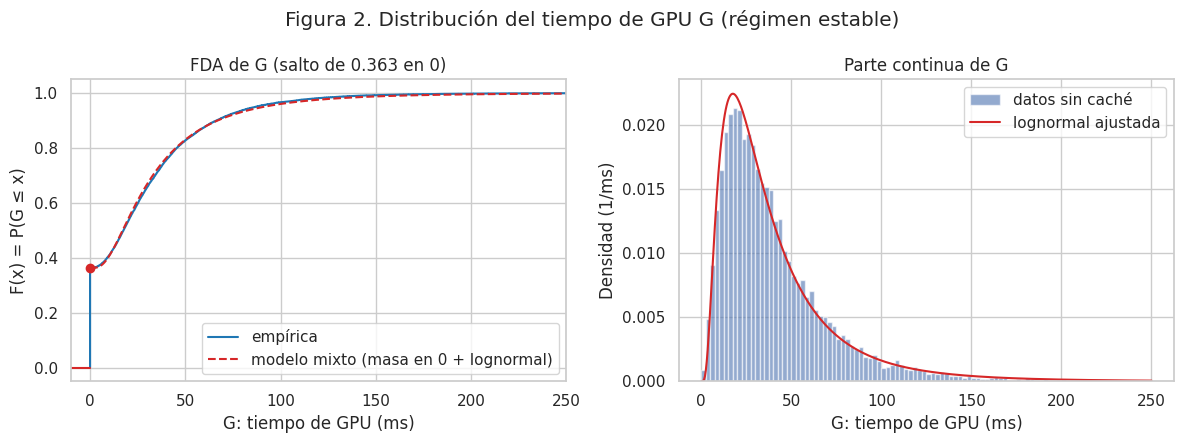

In [132]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))  # dos paneles
gpu_ordenada = np.sort(gpu_todas)  # G ordenada
fda_empirica = np.arange(1, len(gpu_ordenada) + 1) / len(gpu_ordenada)  # FDA empirica
x_modelo = np.linspace(0.01, 250, 500)  # rejilla para el modelo
fda_modelo = p_cache + (1 - p_cache) * stats.norm.cdf((np.log(x_modelo) - m_log) / s_log)  # FDA del modelo mixto
ejes[0].step(gpu_ordenada, fda_empirica, where="post", label="empírica", color="tab:blue")  # FDA empirica en escalera
ejes[0].plot(np.r_[-10, 0], [0, 0], color="tab:red")  # tramo en cero antes del salto
ejes[0].plot(x_modelo, fda_modelo, color="tab:red", linestyle="--", label="modelo mixto (masa en 0 + lognormal)")  # FDA del modelo
ejes[0].scatter([0], [p_cache], color="tab:red", zorder=3)  # punto del salto en 0
ejes[0].set_xlim(-10, 250)  # limites del eje x
ejes[0].set_xlabel("G: tiempo de GPU (ms)")  # etiqueta x
ejes[0].set_ylabel("F(x) = P(G ≤ x)")  # etiqueta y
ejes[0].set_title(f"FDA de G (salto de {p_cache:.3f} en 0)")  # titulo
ejes[0].legend(loc="lower right")  # leyenda

ejes[1].hist(gpu_continua, bins=100, range=(0, 250), density=True, alpha=0.6, label="datos sin caché")  # histograma de la parte continua
ejes[1].plot(x_modelo, stats.lognorm.pdf(x_modelo, s_log, scale=np.exp(m_log)), color="tab:red", label="lognormal ajustada")  # densidad lognormal ajustada
ejes[1].set_xlabel("G: tiempo de GPU (ms)")  # etiqueta x
ejes[1].set_ylabel("Densidad (1/ms)")  # etiqueta y
ejes[1].set_title("Parte continua de G")  # titulo
ejes[1].legend()  # leyenda
fig.suptitle("Figura 2. Distribución del tiempo de GPU G (régimen estable)")  # titulo general
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de Figura 2.* G tiene un salto de altura igual a la proporción de caché en x = 0 y después una parte continua muy asimétrica a la derecha. El lector debe concluir que G es una variable mixta y que el modelo "masa en 0 + lognormal" sigue de cerca la FDA observada; las diferencias son pequeñas y están en el pico y en la cola derecha.

**Conclusión C1.** G es una variable mixta: un átomo en 0 por la caché más una parte continua. Montecarlo confirma las fórmulas de E[G] y Var(G), y con los momentos muestrales de la parte continua las fórmulas reproducen exactamente la media y la varianza observadas. Con la lognormal, en cambio, el modelo sobreestima la media en cerca de 0,5 ms (2 %) y la varianza en cerca del 22 %. El motivo es que la cola derecha de los datos es más corta que la de la lognormal (se ve en C2), y la varianza es muy sensible a esa cola. Alrededor de un tercio de Var(G) viene de la mezcla caché / no caché, es decir, del término p(1 − p)μ_c².

## C2. Máxima verosimilitud para la parte continua de G

Escribimos nosotros mismos la log-verosimilitud de dos familias candidatas para la parte continua (lognormal y gamma) y la maximizamos numéricamente con `scipy.optimize.minimize`. Para que el optimizador trabaje sin restricciones, los parámetros positivos se optimizan en escala logarítmica.

- Lognormal(m, s): ℓ(m, s) = Σ [ −ln x_i − ln s − ½ ln(2π) − (ln x_i − m)² / (2s²) ]
- Gamma(k, θ): ℓ(k, θ) = Σ [ (k − 1) ln x_i − x_i/θ − k ln θ − ln Γ(k) ]

In [133]:
log_x = np.log(gpu_continua)  # log de la gpu continua
n_cont = len(gpu_continua)  # tamano de la muestra continua


def menos_log_ver_lognormal(parametros):  # menos log-verosimilitud lognormal
    m, log_s = parametros  # desempaca m y log(s)
    s = np.exp(log_s)  # s siempre positiva
    return -np.sum(-log_x - np.log(s) - 0.5 * np.log(2 * np.pi) - (log_x - m) ** 2 / (2 * s ** 2))  # devuelve -log L


def menos_log_ver_gamma(parametros):  # menos log-verosimilitud gamma
    k = np.exp(parametros[0])  # forma k positiva
    theta = np.exp(parametros[1])  # escala theta positiva
    return -np.sum((k - 1) * log_x - gpu_continua / theta - k * np.log(theta) - gammaln(k))  # devuelve -log L


ajuste_lognormal = optimize.minimize(menos_log_ver_lognormal, x0=[3.0, 0.0], method="Nelder-Mead")  # ajusta lognormal con Nelder-Mead
m_emv, s_emv = ajuste_lognormal.x[0], np.exp(ajuste_lognormal.x[1])  # m y s estimados
ajuste_gamma = optimize.minimize(menos_log_ver_gamma, x0=[0.0, np.log(gpu_continua.mean())], method="Nelder-Mead")  # ajusta gamma con Nelder-Mead
k_emv, theta_emv = np.exp(ajuste_gamma.x)  # k y theta estimados

print("lognormal (nuestra EMV):  m =", round(m_emv, 4), " s =", round(s_emv, 4), " log-ver =", round(-ajuste_lognormal.fun, 1))  # imprime lognormal por EMV
print("lognormal (forma cerrada): m =", round(m_log, 4), " s =", round(s_log, 4))  # imprime lognormal por formula cerrada
print("gamma (nuestra EMV):      k =", round(k_emv, 4), " theta =", round(theta_emv, 4), " log-ver =", round(-ajuste_gamma.fun, 1))  # imprime gamma por EMV

forma_scipy, _, escala_scipy = stats.lognorm.fit(gpu_continua, floc=0)  # solo como comparacion
print("comparacion con .fit() de scipy (lognormal): m =", round(np.log(escala_scipy), 4), " s =", round(forma_scipy, 4))  # imprime el ajuste de scipy
aic_lognormal = 2 * 2 + 2 * ajuste_lognormal.fun  # AIC lognormal
aic_gamma = 2 * 2 + 2 * ajuste_gamma.fun  # AIC gamma
print("AIC lognormal =", round(aic_lognormal, 1), "  AIC gamma =", round(aic_gamma, 1), "  (menor es mejor)")  # imprime ambos AIC

lognormal (nuestra EMV):  m = 3.4398  s = 0.7591  log-ver = -85713.9
lognormal (forma cerrada): m = 3.4398  s = 0.7591
gamma (nuestra EMV):      k = 2.0145  theta = 20.2407  log-ver = -85842.7
comparacion con .fit() de scipy (lognormal): m = 3.4398  s = 0.7591
AIC lognormal = 171431.8   AIC gamma = 171689.5   (menor es mejor)


**Intervalos para los parámetros.** Para la lognormal, la información de Fisher da Var(m̂) ≈ s²/n y Var(ŝ) ≈ s²/(2n). La comprobamos con la matriz hessiana numérica de nuestra propia −ℓ.

**Otro método de estimación: momentos.** Igualando la media y la varianza muestrales a las de la lognormal: s² = ln(1 + var/media²), m = ln(media) − s²/2.

In [134]:
def hessiana_numerica(funcion, punto, paso=1e-4):  # hessiana por diferencias finitas
    k = len(punto)  # numero de parametros
    hess = np.zeros((k, k))  # matriz vacia
    for i in range(k):  # recorre filas
        for j in range(k):  # recorre columnas
            pp = np.array(punto, dtype=float); pm = pp.copy(); mp = pp.copy(); mm = pp.copy()  # cuatro puntos perturbados
            pp[i] += paso; pp[j] += paso  # ++
            pm[i] += paso; pm[j] -= paso  # +-
            mp[i] -= paso; mp[j] += paso  # -+
            mm[i] -= paso; mm[j] -= paso  # --
            hess[i, j] = (funcion(pp) - funcion(pm) - funcion(mp) + funcion(mm)) / (4 * paso ** 2)  # segunda derivada cruzada
    return hess  # devuelve la hessiana


def menos_log_ver_lognormal_ms(parametros):  # misma funcion pero en (m, s) para la hessiana
    return menos_log_ver_lognormal([parametros[0], np.log(parametros[1])])  # reutiliza la funcion de arriba


cov_emv = np.linalg.inv(hessiana_numerica(menos_log_ver_lognormal_ms, [m_emv, s_emv]))  # covarianza = inversa de la hessiana
error_m = np.sqrt(cov_emv[0, 0])  # error estandar de m
error_s = np.sqrt(cov_emv[1, 1])  # error estandar de s
print(f"m = {m_emv:.4f} [{m_emv - z * error_m:.4f}, {m_emv + z * error_m:.4f}], nivel {confianza}, Wald (hessiana numerica)")  # IC Wald para m
print(f"s = {s_emv:.4f} [{s_emv - z * error_s:.4f}, {s_emv + z * error_s:.4f}], nivel {confianza}, Wald (hessiana numerica)")  # IC Wald para s
print("errores teoricos: EE(m) =", round(s_emv / np.sqrt(n_cont), 5), " EE(s) =", round(s_emv / np.sqrt(2 * n_cont), 5),  # compara con errores teoricos
      " | numericos:", round(error_m, 5), round(error_s, 5))

media_c = gpu_continua.mean()  # media de la parte continua
var_c = gpu_continua.var(ddof=1)  # varianza de la parte continua
s_mom = np.sqrt(np.log(1 + var_c / media_c ** 2))  # s por momentos
m_mom = np.log(media_c) - s_mom ** 2 / 2  # m por momentos
print()  # linea en blanco
print("metodo de momentos:  m =", round(m_mom, 4), " s =", round(s_mom, 4))  # imprime m y s por momentos
print("log-verosimilitud con momentos:", round(-menos_log_ver_lognormal([m_mom, np.log(s_mom)]), 1), " vs EMV:", round(-ajuste_lognormal.fun, 1))  # compara verosimilitudes

m = 3.4398 [3.4307, 3.4489], nivel 0.9, Wald (hessiana numerica)
s = 0.7591 [0.7527, 0.7656], nivel 0.9, Wald (hessiana numerica)
errores teoricos: EE(m) = 0.00555  EE(s) = 0.00393  | numericos: 0.00555 0.00393

metodo de momentos:  m = 3.4706  s = 0.6892
log-verosimilitud con momentos: -85919.4  vs EMV: -85713.9


**Bondad de ajuste.** Usamos tres evidencias:
1. **Numérica, KS** contra la lognormal ajustada, con p-valor por bootstrap paramétrico (los parámetros se estimaron con los mismos datos).
2. **Numérica, chi-cuadrado** con 10 clases equiprobables según la lognormal (gl = 10 − 1 − 2).
3. **Gráfica**: gráfico cuantil-cuantil de los logaritmos contra la normal, para EMV y momentos (figura complementaria).

In [135]:
ks_lognormal = stats.kstest(gpu_continua, "lognorm", args=(s_emv, 0, np.exp(m_emv))).statistic  # KS observado contra lognormal
ks_sim_c2 = np.zeros(200)  # vector de KS simulados
for i in range(200):  # 200 replicas
    muestra = rng.lognormal(m_emv, s_emv, size=n_cont)  # muestra lognormal simulada
    log_muestra = np.log(muestra)  # log de la muestra
    ks_sim_c2[i] = stats.kstest(muestra, "lognorm", args=(log_muestra.std(), 0, np.exp(log_muestra.mean()))).statistic  # KS re-estimando parametros
print("KS observado:", round(ks_lognormal, 4), " p-valor bootstrap:", (ks_sim_c2 >= ks_lognormal).mean(),  # imprime KS y p-valor
      " (KS simulado maximo:", round(ks_sim_c2.max(), 4), ")")

cortes_c2 = stats.lognorm.ppf(np.linspace(0, 1, 11), s_emv, scale=np.exp(m_emv))  # cortes por deciles del modelo
observadas_c2, _ = np.histogram(gpu_continua, bins=cortes_c2)  # observadas por decil
esperadas_c2 = np.full(10, n_cont / 10)  # esperadas por decil
chi2_c2 = ((observadas_c2 - esperadas_c2) ** 2 / esperadas_c2).sum()  # estadistico chi-cuadrado
print("chi-cuadrado =", round(chi2_c2, 1), " gl = 7  p-valor =", stats.chi2.sf(chi2_c2, 7))  # imprime chi-cuadrado y p-valor
print("frecuencia observada / esperada por decil:", np.round(observadas_c2 / esperadas_c2, 3))  # razon observada / esperada

KS observado: 0.0215  p-valor bootstrap: 0.0  (KS simulado maximo: 0.0101 )
chi-cuadrado = 81.3  gl = 7  p-valor = 7.619088937924712e-15
frecuencia observada / esperada por decil: [1.004 0.914 0.945 0.961 0.997 1.033 1.094 1.039 1.106 0.907]


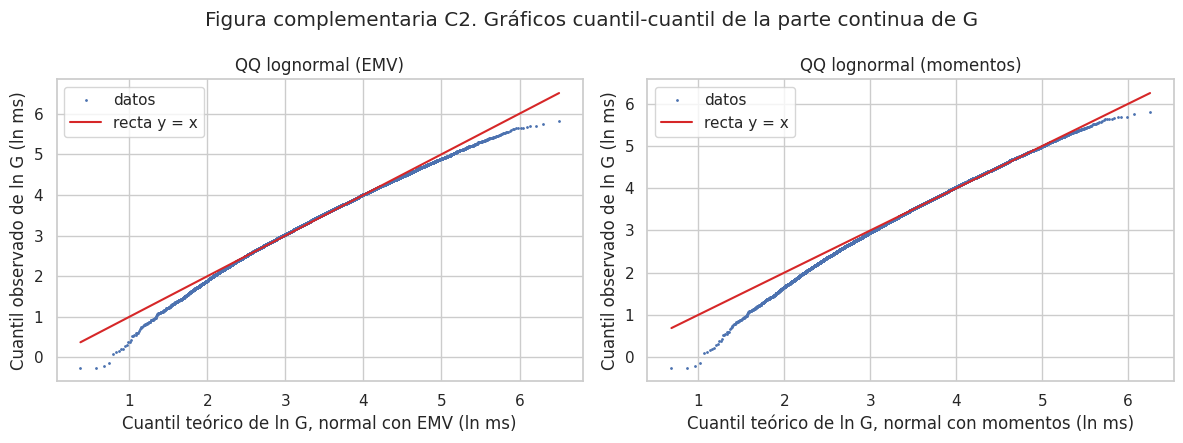

In [136]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))  # dos paneles
probs = (np.arange(1, n_cont + 1) - 0.5) / n_cont  # probabilidades de los cuantiles
cuantiles_datos = np.sort(log_x)  # cuantiles observados de ln G
for eje, (m_q, s_q, nombre) in zip(ejes, [(m_emv, s_emv, "EMV"), (m_mom, s_mom, "momentos")]):  # un panel por metodo (EMV y momentos)
    cuantiles_teoricos = m_q + s_q * stats.norm.ppf(probs)  # cuantiles teoricos normales
    eje.plot(cuantiles_teoricos, cuantiles_datos, ".", markersize=2, label="datos")  # puntos observados
    eje.plot(cuantiles_teoricos, cuantiles_teoricos, color="tab:red", label="recta y = x")  # recta de referencia
    eje.set_xlabel(f"Cuantil teórico de ln G, normal con {nombre} (ln ms)")  # etiqueta x
    eje.set_ylabel("Cuantil observado de ln G (ln ms)")  # etiqueta y
    eje.set_title(f"QQ lognormal ({nombre})")  # titulo
    eje.legend()  # leyenda
fig.suptitle("Figura complementaria C2. Gráficos cuantil-cuantil de la parte continua de G")  # titulo general
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de figura complementaria C2.* En el centro los puntos siguen la recta, pero en los extremos quedan por debajo de ella. A la izquierda eso significa que hay tiempos muy pequeños más pequeños de lo que predice la lognormal; a la derecha, que los tiempos más grandes son menores de lo que predice, es decir, la cola derecha real es más corta. El lector debe concluir que la lognormal describe bien el cuerpo de la distribución, pero exagera la cola derecha (por eso sobreestima Var(G) en C1). Con los parámetros de momentos el centro se desvía más.

**¿Es adecuado un modelo marginal?** En el sistema, G depende del tamaño de la imagen y de la versión del modelo. Si G es aproximadamente proporcional al tamaño con un error multiplicativo, la distribución marginal es una **mezcla** de lognormales con medianas distintas, que no tiene por qué ser lognormal. Lo revisamos ajustando la lognormal por versión y por clase de tamaño.

In [137]:
no_cache_est = estable[(estable["cache_hit"] == 0) & estable["gpu_ms"].notna()].copy()  # solicitudes sin cache y con gpu
no_cache_est["clase"] = np.where(no_cache_est["tam_kb"] < t1, "pequena", np.where(no_cache_est["tam_kb"] < t2, "mediana", "grande"))  # clasifica por tamano
por_grupo = no_cache_est.groupby(["version", "clase"])["gpu_ms"].agg(  # resumen por version y clase
    n="size", media="mean", m_log=lambda v: np.log(v).mean(), s_log=lambda v: np.log(v).std())  # media y parametros log por grupo
print(por_grupo.round(3))  # imprime la tabla
print()  # linea en blanco
print("correlacion entre tam_kb y gpu_ms (sin cache):", round(np.corrcoef(no_cache_est["tam_kb"], no_cache_est["gpu_ms"])[0, 1], 3))  # correlacion tamano - gpu

                    n   media  m_log  s_log
version clase                              
A       grande   1364  80.009  4.189  0.652
        mediana  6671  39.982  3.480  0.678
        pequena  1429  22.218  2.912  0.651
B       grande   1274  72.275  4.102  0.629
        mediana  6547  35.958  3.373  0.681
        pequena  1417  19.385  2.775  0.652

correlacion entre tam_kb y gpu_ms (sin cache): 0.576


**Conclusión C2.** Nuestra EMV numérica coincide con la forma cerrada y con `.fit()`. Por AIC la lognormal es mucho mejor que la gamma. El método de momentos da una s distinta y una log-verosimilitud menor: al usar la media y la varianza, que dependen mucho de la cola derecha, se ajusta peor al cuerpo de la distribución. Las pruebas numéricas, en cambio, **rechazan** la lognormal: con casi 19 000 datos, hasta desviaciones pequeñas son significativas, y el QQ muestra que el problema está en las colas. La razón física es que G no es una población homogénea: su mediana crece con el tamaño de la imagen y es menor en la versión B. Dentro de cada grupo, s (la dispersión en escala log) es parecida, entre 0,63 y 0,68, y menor que la s marginal de 0,76. La marginal es entonces una mezcla de lognormales. Como resumen de G sirve, y la usamos en los cálculos de C y en el simulador. Para preguntas que dependen del tamaño o de la versión, el modelo adecuado es el condicional (partes D y F).

## C3. ¿El tiempo de red es normal?

Usamos tres criterios:
1. **D'Agostino-Pearson**: combina asimetría y curtosis muestrales.
2. **Anderson-Darling** con parámetros estimados, más sensible a las colas.
3. **Gráfico cuantil-cuantil** contra la normal (Figura 3).

Después calculamos P(red > x) para x = 22, 25 y 28 ms, y el percentil 99,9 %, con el modelo normal y de forma empírica, cada uno con su intervalo.

In [138]:
red = estable["red_ms"].dropna().values  # tiempos de red estables

media_red = red.mean()
de_red = red.std(ddof=1)

print(
    "n =", len(red),
    " media =", round(media_red, 3),
    " DE =", round(de_red, 3),
    " asimetria =", round(stats.skew(red), 4),
    " curtosis exceso =", round(stats.kurtosis(red), 4)
)

# Prueba D'Agostino-Pearson
prueba_dagostino = stats.normaltest(red)

print(
    "D'Agostino-Pearson: estadistico =",
    round(prueba_dagostino.statistic, 3),
    " p-valor =",
    round(prueba_dagostino.pvalue, 3)
)

# Prueba Anderson-Darling
prueba_ad = stats.anderson(red, dist="norm")

print(
    "Anderson-Darling: estadistico =",
    round(prueba_ad.statistic, 3)
)

print("Valores críticos de Anderson-Darling:")

for nivel, valor in zip(
    prueba_ad.significance_level,
    prueba_ad.critical_values
):
    print(f"{nivel}%: {valor:.4f}")

# Mínimo y máximo
print(
    "minimo =", red.min(),
    " maximo =", red.max(),
    " (a cuantas DE de la media:",
    round((red.min() - media_red) / de_red, 2),
    ",",
    round((red.max() - media_red) / de_red, 2),
    ")"
)

n = 29355  media = 19.039  DE = 2.761  asimetria = 0.0127  curtosis exceso = -0.0231
D'Agostino-Pearson: estadistico = 1.427  p-valor = 0.49
Anderson-Darling: estadistico = 0.292
Valores críticos de Anderson-Darling:
15.0%: 0.5760
10.0%: 0.6560
5.0%: 0.7870
2.5%: 0.9180
1.0%: 1.0920
minimo = 6.62  maximo = 29.66  (a cuantas DE de la media: -4.5 , 3.85 )


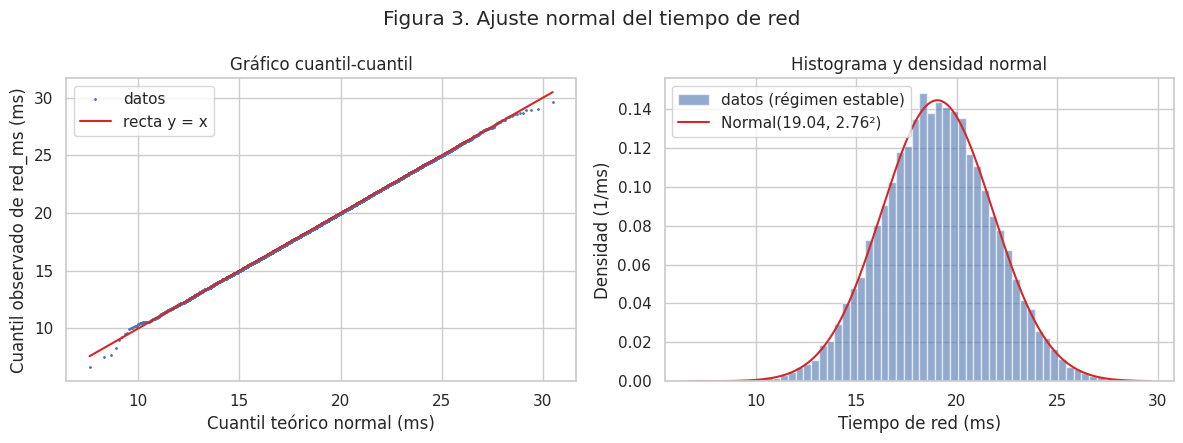

In [139]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))  # dos paneles
probs_red = (np.arange(1, len(red) + 1) - 0.5) / len(red)  # probabilidades de los cuantiles
teoricos_red = media_red + de_red * stats.norm.ppf(probs_red)  # cuantiles normales teoricos
ejes[0].plot(teoricos_red, np.sort(red), ".", markersize=2, label="datos")  # puntos observados
ejes[0].plot(teoricos_red, teoricos_red, color="tab:red", label="recta y = x")  # recta de referencia
ejes[0].set_xlabel("Cuantil teórico normal (ms)")  # etiqueta x
ejes[0].set_ylabel("Cuantil observado de red_ms (ms)")  # etiqueta y
ejes[0].set_title("Gráfico cuantil-cuantil")  # titulo
ejes[0].legend()  # leyenda

x_red = np.linspace(red.min(), red.max(), 300)  # rejilla para la densidad
ejes[1].hist(red, bins=60, density=True, alpha=0.6, label="datos (régimen estable)")  # histograma de red
ejes[1].plot(x_red, stats.norm.pdf(x_red, media_red, de_red), color="tab:red", label=f"Normal({media_red:.2f}, {de_red:.2f}²)")  # densidad normal ajustada
ejes[1].set_xlabel("Tiempo de red (ms)")  # etiqueta x
ejes[1].set_ylabel("Densidad (1/ms)")  # etiqueta y
ejes[1].set_title("Histograma y densidad normal")  # titulo
ejes[1].legend()  # leyenda
fig.suptitle("Figura 3. Ajuste normal del tiempo de red")  # titulo general
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de Figura 3.* Los puntos del gráfico cuantil-cuantil caen sobre la recta incluso en los extremos, y el histograma coincide con la campana normal. El lector debe concluir que el tiempo de red se puede modelar como normal.

**Probabilidades de cola y percentil 99,9 %.** Con el modelo normal: P(red > x) = 1 − Φ((x − μ)/σ) y q_0,999 = μ + z_0,999·σ. Sus intervalos salen de un **bootstrap paramétrico**: simulamos muestras normales del mismo tamaño, re-estimamos μ y σ y recalculamos cada cantidad. Como comparación sin supuestos: la proporción empírica con intervalo de Wilson, y el percentil empírico con su intervalo por estadísticos de orden (basado en la binomial).

In [140]:
valores_x = [22, 25, 28]  # umbrales de red a evaluar
replicas_c3 = 2000  # replicas bootstrap
prob_boot = np.zeros((replicas_c3, len(valores_x)))  # probabilidades simuladas
p999_boot = np.zeros(replicas_c3)  # percentiles 99.9 simulados
for i in range(replicas_c3):  # repite el bootstrap
    muestra = rng.normal(media_red, de_red, size=len(red))  # muestra normal simulada
    mu_b = muestra.mean()  # media simulada
    de_b = muestra.std(ddof=1)  # desviacion simulada
    prob_boot[i] = stats.norm.sf(valores_x, mu_b, de_b)  # P(red > x) en la replica
    p999_boot[i] = mu_b + stats.norm.ppf(0.999) * de_b  # percentil 99.9 de la replica

filas_c3 = []  # filas de la tabla
for j, x_val in enumerate(valores_x):  # recorre cada umbral
    prob_normal = stats.norm.sf(x_val, media_red, de_red)  # probabilidad normal
    inf_n, sup_n = np.quantile(prob_boot[:, j], [alpha / 2, 1 - alpha / 2])  # IC por percentiles del bootstrap
    conteo = (red > x_val).sum()  # conteo empirico
    wilson = stats.binomtest(conteo, len(red)).proportion_ci(confidence_level=confianza, method="wilson")  # IC de Wilson
    filas_c3.append([x_val, f"{prob_normal:.5f} [{inf_n:.5f}, {sup_n:.5f}]", f"{conteo / len(red):.5f} [{wilson.low:.5f}, {wilson.high:.5f}]"])  # guarda la fila
print(pd.DataFrame(filas_c3, columns=["x (ms)", "P(red > x) normal [bootstrap param.]", "P(red > x) empirica [Wilson]"]).to_string(index=False))  # imprime la tabla
print(f"nivel {confianza}")  # imprime el nivel

p999_normal = media_red + stats.norm.ppf(0.999) * de_red  # percentil 99.9 normal
inf_p, sup_p = np.quantile(p999_boot, [alpha / 2, 1 - alpha / 2])  # IC del percentil 99.9
red_ordenada = np.sort(red)  # red ordenada
p999_empirico = np.quantile(red, 0.999)  # percentil 99.9 empirico
indice_inf = int(stats.binom.ppf(alpha / 2, len(red), 0.999))  # estadisticos de orden
indice_sup = min(int(stats.binom.ppf(1 - alpha / 2, len(red), 0.999)) + 1, len(red) - 1)  # indice superior del IC
print()  # linea en blanco
print(f"percentil 99.9 normal   = {p999_normal:.3f} [{inf_p:.3f}, {sup_p:.3f}] ms, nivel {confianza}, bootstrap parametrico (percentiles)")  # imprime el normal
print(f"percentil 99.9 empirico = {p999_empirico:.3f} [{red_ordenada[indice_inf]:.3f}, {red_ordenada[indice_sup]:.3f}] ms, nivel {confianza}, estadisticos de orden")  # imprime el empirico

 x (ms) P(red > x) normal [bootstrap param.] P(red > x) empirica [Wilson]
     22           0.14182 [0.13906, 0.14451]   0.14291 [0.13958, 0.14630]
     25           0.01544 [0.01477, 0.01613]   0.01516 [0.01403, 0.01638]
     28           0.00059 [0.00054, 0.00064]   0.00061 [0.00042, 0.00090]
nivel 0.9

percentil 99.9 normal   = 27.572 [27.509, 27.635] ms, nivel 0.9, bootstrap parametrico (percentiles)
percentil 99.9 empirico = 27.469 [27.370, 27.920] ms, nivel 0.9, estadisticos de orden


**Conclusión C3.** El tiempo de red admite un modelo normal: asimetría y curtosis prácticamente 0, ni D'Agostino ni Anderson-Darling rechazan al nivel del grupo, y el gráfico cuantil-cuantil es una recta. Las probabilidades de cola del modelo normal coinciden con las empíricas, pero sus intervalos son mucho más angostos, porque el modelo usa todos los datos y no solo los pocos que caen en la cola. Lo mismo pasa con el percentil 99,9 %: el modelo normal lo da con un intervalo de unas décimas de ms, mientras que el empírico depende de unas 30 observaciones y es más ancho.

## C4. Tiempo total de GPU de N solicitudes consecutivas

Sea T_N la suma de los tiempos de GPU de N = 11 solicitudes no cacheadas consecutivas, y m̂ la media muestral de `gpu_ms` sin caché. Queremos P(T_N > N(m̂ + 15)), es decir, la probabilidad de que el promedio de 11 solicitudes supere la media en más de 15 ms. Suponemos los tiempos independientes (lo comprobamos con la autocorrelación) y usamos tres aproximaciones analíticas:

1. **Normal (TLC):** T_N ≈ Normal(N·m, N·σ²). Ignora la asimetría.
2. **Gamma por momentos:** aproximamos T_N por una gamma con la misma media y varianza (k = N·m²/σ², θ = σ²/m). Tiene asimetría positiva, como T_N.
3. **Lognormal de Fenton-Wilkinson:** aproximamos la suma de lognormales por una lognormal con la misma media y varianza.

La "verdad" la da una simulación que remuestrea los tiempos reales sin caché (sin suponer ninguna familia), complementada con las sumas reales de 11 solicitudes consecutivas.

In [141]:
m_gpu = gpu_continua.mean()  # m sombrero
de_gpu = gpu_continua.std(ddof=1)  # desviacion de la gpu continua
umbral_c4 = N * (m_gpu + 15)  # umbral N(m + 15)
media_t = N * m_gpu  # media de la suma de N
var_t = N * de_gpu ** 2  # varianza de la suma de N
print("N =", N, " m =", round(m_gpu, 3), " DE =", round(de_gpu, 3), " umbral N(m + 15) =", round(umbral_c4, 2), "ms")  # imprime parametros y umbral

secuencia_gpu = no_cache_est.sort_values("t_llegada_s")["gpu_ms"].values  # gpu sin cache en orden temporal
print("autocorrelacion rezago 1 de gpu sin cache:", round(np.corrcoef(secuencia_gpu[:-1], secuencia_gpu[1:])[0, 1], 4),  # autocorrelacion rezago 1
      " banda +/-", round(z / np.sqrt(len(secuencia_gpu)), 4))  # banda de independencia

p_normal_c4 = stats.norm.sf(umbral_c4, media_t, np.sqrt(var_t))  # normal por TLC

k_gamma = media_t ** 2 / var_t  # forma gamma por momentos
theta_gamma = var_t / media_t  # escala gamma por momentos
p_gamma_c4 = stats.gamma.sf(umbral_c4, k_gamma, scale=theta_gamma)  # cola superior gamma

s2_fw = np.log(1 + var_t / media_t ** 2)  # Fenton-Wilkinson
m_fw = np.log(media_t) - s2_fw / 2  # m de Fenton-Wilkinson
p_fw_c4 = stats.lognorm.sf(umbral_c4, np.sqrt(s2_fw), scale=np.exp(m_fw))  # cola superior lognormal

N = 11  m = 40.774  DE = 31.791  umbral N(m + 15) = 613.52 ms
autocorrelacion rezago 1 de gpu sin cache: 0.0012  banda +/- 0.012


In [142]:
replicas_c4 = 1_000_000  # replicas de la simulacion
lote_c4 = 200_000  # tamano de cada lote
exceden = 0  # contador de excedencias
for i in range(replicas_c4 // lote_c4):  # simula por lotes
    sumas = rng.choice(gpu_continua, size=(lote_c4, N), replace=True).sum(axis=1)  # remuestreo de datos reales
    exceden += (sumas > umbral_c4).sum()  # cuenta sumas sobre el umbral
p_sim_c4 = exceden / replicas_c4  # probabilidad simulada
error_sim_c4 = np.sqrt(p_sim_c4 * (1 - p_sim_c4) / replicas_c4)  # error estandar

num_grupos = len(secuencia_gpu) // N  # grupos reales consecutivos
sumas_reales = secuencia_gpu[:num_grupos * N].reshape(num_grupos, N).sum(axis=1)  # suma de cada grupo real
p_real_c4 = (sumas_reales > umbral_c4).mean()  # proporcion real sobre el umbral
wilson_c4 = stats.binomtest((sumas_reales > umbral_c4).sum(), num_grupos).proportion_ci(confidence_level=confianza, method="wilson")  # IC de Wilson de la proporcion real

tabla_c4 = pd.DataFrame({  # tabla comparativa
    "metodo": ["normal (TLC)", "gamma por momentos", "lognormal Fenton-Wilkinson", "simulacion (remuestreo)", "grupos reales consecutivos"],  # nombre de cada metodo
    "P(T_N > umbral)": [p_normal_c4, p_gamma_c4, p_fw_c4, p_sim_c4, p_real_c4],  # probabilidad de cada metodo
})
tabla_c4["error relativo vs simulacion"] = (tabla_c4["P(T_N > umbral)"] - p_sim_c4) / p_sim_c4  # error relativo contra simulacion
print(tabla_c4.round(5).to_string(index=False))  # imprime la tabla
print(f"simulacion: {p_sim_c4:.5f} [{p_sim_c4 - z * error_sim_c4:.5f}, {p_sim_c4 + z * error_sim_c4:.5f}], nivel {confianza}, Wald, {replicas_c4} replicas")  # imprime la simulacion con IC
print(f"grupos reales: {p_real_c4:.4f} [{wilson_c4.low:.4f}, {wilson_c4.high:.4f}], nivel {confianza}, Wilson, {num_grupos} grupos")  # imprime los grupos reales con IC
print("asimetria de G:", round(stats.skew(gpu_continua), 3), " asimetria de T_N = asimetria(G)/sqrt(N):", round(stats.skew(gpu_continua) / np.sqrt(N), 3))  # imprime asimetrias

                    metodo  P(T_N > umbral)  error relativo vs simulacion
              normal (TLC)          0.05881                      -0.17496
        gamma por momentos          0.06914                      -0.02996
lognormal Fenton-Wilkinson          0.07124                      -0.00054
   simulacion (remuestreo)          0.07128                       0.00000
grupos reales consecutivos          0.07471                       0.04812
simulacion: 0.07128 [0.07085, 0.07170], nivel 0.9, Wald, 1000000 replicas
grupos reales: 0.0747 [0.0649, 0.0859], nivel 0.9, Wilson, 1700 grupos
asimetria de G: 2.155  asimetria de T_N = asimetria(G)/sqrt(N): 0.65


**Conclusión C4.** La aproximación normal **subestima** la probabilidad: con N = 11 la suma todavía conserva bastante asimetría (la asimetría de T_N es la de G dividida por √N), y la normal, que es simétrica, adelgaza la cola derecha. La gamma por momentos y la lognormal de Fenton-Wilkinson capturan esa asimetría y quedan mucho más cerca de la simulación. Las sumas reales de 11 solicitudes consecutivas dan un valor compatible con la simulación (está dentro de su intervalo de Wilson). Preferimos la **lognormal de Fenton-Wilkinson**: tiene el menor error frente a la simulación y es igual de fácil de calcular que la normal, porque solo necesita la media y la varianza. La gamma es una segunda opción razonable. Que Fenton-Wilkinson acierte tanto aquí es en parte suerte (la cola de una lognormal con la misma media y varianza resulta parecida a la de la suma real); en general, ambas aproximaciones asimétricas son mucho mejores que la normal para N pequeño. Para N grande las tres coincidirían.

# Parte D — Dependencias y esperanza condicional

## D1. Distribución conjunta de (clase de tamaño, cache_hit)

Clasificamos cada solicitud del régimen estable por tamaño: pequeña (< t1 = 100 KB), mediana (100 a 450 KB) y grande (≥ t2 = 450 KB). Construimos la tabla conjunta de proporciones, las marginales y las condicionales P(caché | clase). Para decidir si son independientes usamos tres evidencias: la prueba chi-cuadrado de independencia, intervalos de Wilson para P(caché | clase) (si fueran independientes, los tres intervalos deberían solaparse alrededor de la proporción global) y el intervalo de la diferencia entre la clase pequeña y la grande.

In [143]:
orden_clases = ["pequena", "mediana", "grande"]  # orden de las clases
estable["clase"] = np.where(estable["tam_kb"] < t1, "pequena", np.where(estable["tam_kb"] < t2, "mediana", "grande"))  # clase segun tamano
tabla_conteos = pd.crosstab(estable["clase"], estable["cache_hit"]).loc[orden_clases]  # tabla de conteos clase x cache
conjunta = tabla_conteos / tabla_conteos.values.sum()  # P(clase, cache)
marginal_clase = conjunta.sum(axis=1)  # marginal de clase
marginal_cache = conjunta.sum(axis=0)  # marginal de cache
print("conteos:")  # titulo
print(tabla_conteos)  # imprime conteos
print("\nconjunta P(clase, cache_hit):")  # imprime la conjunta
print(conjunta.round(4))  # imprime la conjunta
print("\nmarginal de clase:", marginal_clase.round(4).to_dict())  # imprime marginal de clase
print("marginal de cache_hit:", marginal_cache.round(4).to_dict())  # imprime marginal de cache
print("\nP(cache_hit | clase):")  # titulo
print((tabla_conteos.div(tabla_conteos.sum(axis=1), axis=0)).round(4))  # imprime P(cache | clase)
print("\nP(clase | cache_hit):")  # titulo
print((tabla_conteos / tabla_conteos.sum(axis=0)).round(4))  # imprime P(clase | cache)

conteos:
cache_hit      0     1
clase                 
pequena     2848  2976
mediana    13233  7020
grande      2639   671

conjunta P(clase, cache_hit):
cache_hit       0       1
clase                    
pequena    0.0969  0.1013
mediana    0.4503  0.2389
grande     0.0898  0.0228

marginal de clase: {'pequena': 0.1982, 'mediana': 0.6892, 'grande': 0.1126}
marginal de cache_hit: {0: 0.637, 1: 0.363}

P(cache_hit | clase):
cache_hit       0       1
clase                    
pequena    0.4890  0.5110
mediana    0.6534  0.3466
grande     0.7973  0.2027

P(clase | cache_hit):
cache_hit       0       1
clase                    
pequena    0.1521  0.2790
mediana    0.7069  0.6581
grande     0.1410  0.0629


In [144]:
chi2_ind, p_ind, gl_ind, esperados_ind = stats.chi2_contingency(tabla_conteos.values)  # prueba chi-cuadrado de independencia
v_cramer = np.sqrt(chi2_ind / (tabla_conteos.values.sum() * (min(tabla_conteos.shape) - 1)))  # V de Cramer
print("chi-cuadrado de independencia =", round(chi2_ind, 1), " gl =", gl_ind, " p-valor =", p_ind)  # imprime chi-cuadrado y p-valor
print("V de Cramer =", round(v_cramer, 3))  # imprime V de Cramer
print("\nproducto de marginales (lo que se esperaria con independencia):")  # titulo
print(pd.DataFrame(np.outer(marginal_clase, marginal_cache), index=orden_clases, columns=[0, 1]).round(4))  # producto de marginales

print()  # linea en blanco
for clase in orden_clases:  # recorre cada clase
    exitos_c = tabla_conteos.loc[clase, 1]  # casos con cache en la clase
    total_c = tabla_conteos.loc[clase].sum()  # total de la clase
    ic = stats.binomtest(exitos_c, total_c).proportion_ci(confidence_level=confianza, method="wilson")  # IC de Wilson
    print(f"P(cache | {clase:8s}) = {exitos_c / total_c:.4f} [{ic.low:.4f}, {ic.high:.4f}], nivel {confianza}, Wilson")  # imprime P(cache | clase)
print(f"P(cache) global        = {marginal_cache[1]:.4f}")  # imprime P(cache) global

p_peq = tabla_conteos.loc["pequena", 1] / tabla_conteos.loc["pequena"].sum()  # P(cache) en clase pequena
p_gra = tabla_conteos.loc["grande", 1] / tabla_conteos.loc["grande"].sum()  # P(cache) en clase grande
error_dif_d1 = np.sqrt(p_peq * (1 - p_peq) / tabla_conteos.loc["pequena"].sum() + p_gra * (1 - p_gra) / tabla_conteos.loc["grande"].sum())  # error de la diferencia
print(f"diferencia pequena - grande = {p_peq - p_gra:.4f} [{p_peq - p_gra - z * error_dif_d1:.4f}, {p_peq - p_gra + z * error_dif_d1:.4f}], nivel {confianza}, Wald")  # imprime la diferencia con IC

chi-cuadrado de independencia = 942.9  gl = 2  p-valor = 1.7959989802355558e-205
V de Cramer = 0.179

producto de marginales (lo que se esperaria con independencia):
              0       1
pequena  0.1262  0.0719
mediana  0.4390  0.2502
grande   0.0718  0.0409

P(cache | pequena ) = 0.5110 [0.5002, 0.5218], nivel 0.9, Wilson
P(cache | mediana ) = 0.3466 [0.3411, 0.3521], nivel 0.9, Wilson
P(cache | grande  ) = 0.2027 [0.1915, 0.2145], nivel 0.9, Wilson
P(cache) global        = 0.3630
diferencia pequena - grande = 0.3083 [0.2925, 0.3240], nivel 0.9, Wald


**Figura 4.** Mapa de calor de la distribución conjunta empírica P(clase, cache_hit) en el régimen estable. Cada celda muestra la probabilidad conjunta y, entre paréntesis, la que se esperaría si las variables fueran independientes.

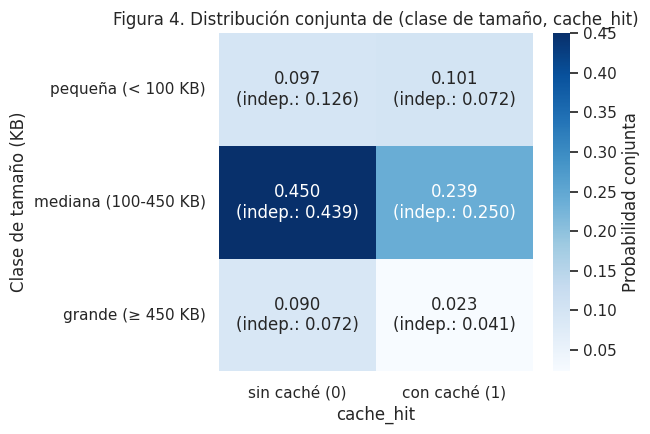

In [145]:
etiquetas = conjunta.copy().astype(str)  # etiquetas de las celdas
producto = np.outer(marginal_clase, marginal_cache)  # producto de marginales
for i in range(3):  # recorre filas
    for j in range(2):  # recorre columnas
        etiquetas.iloc[i, j] = f"{conjunta.iloc[i, j]:.3f}\n(indep.: {producto[i, j]:.3f})"  # texto con conjunta e independiente
fig, eje = plt.subplots(figsize=(6.5, 4.5))  # figura
sns.heatmap(conjunta, annot=etiquetas.values, fmt="", cmap="Blues", cbar_kws={"label": "Probabilidad conjunta"}, ax=eje)  # mapa de calor
eje.set_xticklabels(["sin caché (0)", "con caché (1)"])  # etiquetas del eje x
eje.set_yticklabels([f"pequeña (< {t1} KB)", f"mediana ({t1}-{t2} KB)", f"grande (≥ {t2} KB)"], rotation=0)  # etiquetas del eje y
eje.set_xlabel("cache_hit")  # etiqueta x
eje.set_ylabel("Clase de tamaño (KB)")  # etiqueta y
eje.set_title("Figura 4. Distribución conjunta de (clase de tamaño, cache_hit)")  # titulo
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de Figura 4.* Las imágenes pequeñas tienen más probabilidad conjunta con caché de la que habría con independencia, y las grandes, menos. El lector debe concluir que la clase de tamaño y la caché **no** son independientes: las imágenes pequeñas se repiten más y se responden desde caché con mayor frecuencia.

**Conclusión D1.** La clase de tamaño y `cache_hit` son dependientes. La chi-cuadrado rechaza la independencia con un p-valor prácticamente nulo, los intervalos de P(caché | clase) no se solapan entre sí (cerca de 0,51 para pequeñas, 0,35 para medianas y 0,20 para grandes) y la diferencia entre pequeñas y grandes tiene un intervalo lejos de 0. La V de Cramér indica una asociación moderada. Esto importa para G: como las grandes casi no se cachean, son justo las que más GPU consumen.

## D2. Esperanzas condicionales no paramétricas y leyes de la esperanza y la varianza total

- E[G | clase, no caché]: media muestral de cada grupo, con intervalo t.
- E[G | tam_kb]: regresión de núcleo de **Nadaraya-Watson** escrita por nosotros (promedio ponderado de G con pesos gaussianos según la distancia en tamaño), con ancho de banda por la regla de Silverman. La calculamos para las solicitudes sin caché y también para todas (incluyendo los ceros de caché).
- Luego verificamos numéricamente E[G] = Σ E[G | grupo]·P(grupo) y Var(G) = E[Var(G | grupo)] + Var(E[G | grupo]), con los grupos definidos por la clase (y por clase × caché).

In [146]:
gpu_conocida = estable[estable["gpu_ms"].notna()].copy()  # G de todas las solicitudes con gpu conocida
sin_cache_d = gpu_conocida[gpu_conocida["cache_hit"] == 0]  # solo las solicitudes sin cache
filas_d2 = []  # filas de resultados
for clase in orden_clases:  # recorre cada clase
    valores = sin_cache_d.loc[sin_cache_d["clase"] == clase, "gpu_ms"]  # gpu de esa clase
    t_crit = stats.t.ppf(1 - alpha / 2, len(valores) - 1)  # cuantil t
    error = valores.std(ddof=1) / np.sqrt(len(valores))  # error estandar de la media
    filas_d2.append([clase, len(valores), f"{valores.mean():.2f} [{valores.mean() - t_crit * error:.2f}, {valores.mean() + t_crit * error:.2f}]"])  # guarda media con IC t
print(pd.DataFrame(filas_d2, columns=["clase", "n", "E[G | clase, no cache] [IC t]"]).to_string(index=False))  # imprime la tabla
print(f"nivel {confianza}")  # imprime el nivel

  clase     n E[G | clase, no cache] [IC t]
pequena  2846          20.81 [20.42, 21.20]
mediana 13218          37.99 [37.63, 38.34]
 grande  2638          76.27 [74.77, 77.77]
nivel 0.9


In [147]:
def nadaraya_watson(x_datos, y_datos, x_grilla, ancho_banda):  # estimador de Nadaraya-Watson
    estimado = np.zeros(len(x_grilla))  # vector de estimaciones
    for i, x0 in enumerate(x_grilla):  # recorre cada punto de la grilla
        pesos = np.exp(-0.5 * ((x_datos - x0) / ancho_banda) ** 2)  # nucleo gaussiano
        estimado[i] = np.sum(pesos * y_datos) / np.sum(pesos)  # promedio ponderado
    return estimado  # devuelve la curva


tam_nc = sin_cache_d["tam_kb"].values  # tamanos sin cache
gpu_nc = sin_cache_d["gpu_ms"].values  # gpu sin cache
ancho_nc = 1.06 * tam_nc.std() * len(tam_nc) ** (-1 / 5)  # regla de Silverman
grilla_tam = np.linspace(np.quantile(tam_nc, 0.005), np.quantile(tam_nc, 0.995), 80)  # grilla de tamanos
curva_nc = nadaraya_watson(tam_nc, gpu_nc, grilla_tam, ancho_nc)  # curva sin cache

tam_todas = gpu_conocida["tam_kb"].values  # tamanos de todas
gpu_todas_d = gpu_conocida["gpu_ms"].values  # gpu de todas
ancho_todas = 1.06 * tam_todas.std() * len(tam_todas) ** (-1 / 5)  # ancho de banda de Silverman
curva_todas = nadaraya_watson(tam_todas, gpu_todas_d, grilla_tam, ancho_todas)  # curva con todas
print("ancho de banda (sin cache):", round(ancho_nc, 2), "KB")  # imprime el ancho de banda
for tam_mostrar in [50, 150, 300, 600]:  # tamanos a mostrar
    i = np.argmin(abs(grilla_tam - tam_mostrar))  # punto de grilla mas cercano
    print(f"tam ~ {grilla_tam[i]:.0f} KB:  E[G | tam, no cache] = {curva_nc[i]:.2f} ms   E[G | tam] (todas) = {curva_todas[i]:.2f} ms")  # imprime ambas curvas

ancho de banda (sin cache): 26.18 KB
tam ~ 50 KB:  E[G | tam, no cache] = 20.35 ms   E[G | tam] (todas) = 9.54 ms
tam ~ 154 KB:  E[G | tam, no cache] = 29.50 ms   E[G | tam] (todas) = 19.20 ms
tam ~ 305 KB:  E[G | tam, no cache] = 45.46 ms   E[G | tam] (todas) = 29.70 ms
tam ~ 596 KB:  E[G | tam, no cache] = 77.28 ms   E[G | tam] (todas) = 62.65 ms


In [148]:
def descomposicion(tabla, columna_grupo):  # descomposicion por grupos
    total = tabla["gpu_ms"]  # gpu de todas
    grupos = tabla.groupby(columna_grupo)["gpu_ms"]  # agrupa
    prob = grupos.size() / len(tabla)  # probabilidad de cada grupo
    medias = grupos.mean()  # media de cada grupo
    varianzas = grupos.var(ddof=0)  # divisor n para que la identidad sea exacta
    media_total = (prob * medias).sum()  # esperanza total
    dentro = (prob * varianzas).sum()  # E[Var(G|g)]
    entre = (prob * (medias - media_total) ** 2).sum()  # Var(E[G|g])
    return total.mean(), media_total, total.var(ddof=0), dentro, entre  # devuelve los valores


gpu_conocida["clase_cache"] = gpu_conocida["clase"] + "_" + gpu_conocida["cache_hit"].astype(str)  # combina clase y cache
filas_tot = []  # filas de resultados
for nombre, tabla, grupo in [("G (todas), grupos = clase", gpu_conocida, "clase"),  # tres casos
                             ("G (todas), grupos = clase x cache", gpu_conocida, "clase_cache"),
                             ("G sin cache, grupos = clase", sin_cache_d, "clase")]:
    media_directa, media_ley, var_directa, dentro, entre = descomposicion(tabla, grupo)  # calcula la descomposicion
    filas_tot.append([nombre, media_directa, media_ley, var_directa, dentro + entre, dentro, entre, entre / var_directa])  # guarda la fila
tabla_tot = pd.DataFrame(filas_tot, columns=["caso", "E[G] directa", "sum E[G|g]P(g)", "Var(G) directa",  # arma la tabla
                                             "E[Var] + Var(E)", "E[Var(G|g)]", "Var(E[G|g])", "fraccion explicada"])
print(tabla_tot.round(4).to_string(index=False))  # imprime la tabla

                             caso  E[G] directa  sum E[G|g]P(g)  Var(G) directa  E[Var] + Var(E)  E[Var(G|g)]  Var(E[G|g])  fraccion explicada
        G (todas), grupos = clase       25.9648         25.9648       1028.0834        1028.0834     840.9422     187.1412              0.1820
G (todas), grupos = clase x cache       25.9648         25.9648       1028.0834        1028.0834     488.2363     539.8471              0.5251
      G sin cache, grupos = clase       40.7743         40.7743       1010.6219        1010.6219     766.7100     243.9118              0.2413


**Conclusión D2.** La media de G sin caché crece claramente con la clase (las grandes cuestan unas 3,6 veces lo que cuestan las pequeñas), y la curva de núcleo muestra que E[G | tam] crece casi en línea recta con el tamaño. Si se incluyen las solicitudes con caché, E[G | tam] crece todavía más rápido, porque las imágenes pequeñas tienen más caché (D1). Las leyes de la esperanza total y de la varianza total se cumplen exactamente: las columnas directas y las descompuestas coinciden. La clase de tamaño explica menos de una cuarta parte de Var(G) (alrededor del 18 % con todas las solicitudes y del 24 % sin caché); la mayor parte de la variabilidad está **dentro** de cada clase. Si además se agrupa por caché, la fracción explicada sube mucho, porque separa los ceros.

## D3. Modelo lineal para E[G | tam_kb, no caché] por mínimos cuadrados

**Planteamiento.** G_i = β0 + β1·tam_i + e_i. En forma matricial y = Xβ + e, donde X tiene una columna de unos y una de tamaños. Minimizar la suma de cuadrados S(β) = (y − Xβ)ᵀ(y − Xβ) y derivar da las **ecuaciones normales** (XᵀX)β = Xᵀy, que resolvemos con `np.linalg.solve`. Con e_i independientes de varianza constante σ², Cov(β̂) = σ²(XᵀX)⁻¹, con σ̂² = SSR/(n − 2), y los intervalos usan la t con n − 2 grados de libertad.

In [149]:
y_d3 = gpu_nc  # variable respuesta (gpu)
X_d3 = np.column_stack([np.ones(len(tam_nc)), tam_nc])  # matriz de diseno [1, tamano]
XtX = X_d3.T @ X_d3  # X'X
Xty = X_d3.T @ y_d3  # X'y
beta_mco = np.linalg.solve(XtX, Xty)  # ecuaciones normales
ajustados_mco = X_d3 @ beta_mco  # valores ajustados
residuos_mco = y_d3 - ajustados_mco  # residuos
n_d3 = len(y_d3)  # tamano de la muestra
sigma2_mco = np.sum(residuos_mco ** 2) / (n_d3 - 2)  # varianza del error
cov_mco = sigma2_mco * np.linalg.inv(XtX)  # covarianza de los coeficientes
t_d3 = stats.t.ppf(1 - alpha / 2, n_d3 - 2)  # cuantil t
r2_mco = 1 - np.sum(residuos_mco ** 2) / np.sum((y_d3 - y_d3.mean()) ** 2)  # R cuadrado

print("XtX =\n", XtX.round(1))  # imprime X'X
print("Xty =", Xty.round(1))  # imprime X'y
for j, nombre in enumerate(["beta0 (ms)", "beta1 (ms/KB)"]):  # recorre los coeficientes
    error = np.sqrt(cov_mco[j, j])  # error estandar
    print(f"{nombre} = {beta_mco[j]:.5f} [{beta_mco[j] - t_d3 * error:.5f}, {beta_mco[j] + t_d3 * error:.5f}], nivel {confianza}, t clasico (MCO)")  # imprime coeficiente con IC
print("R^2 =", round(r2_mco, 4), "  sigma =", round(np.sqrt(sigma2_mco), 3), "ms")  # imprime R2 y sigma

XtX =
 [[1.87020000e+04 4.85934630e+06]
 [4.85934630e+06 1.84604714e+09]]
Xty = [7.62561100e+05 2.58580091e+08]
beta0 (ms) = 13.85632 [13.30008, 14.41255], nivel 0.9, t clasico (MCO)
beta1 (ms/KB) = 0.10360 [0.10183, 0.10537], nivel 0.9, t clasico (MCO)
R^2 = 0.3313   sigma = 25.998 ms


**Análisis de residuos.** Los supuestos del intervalo clásico son media cero, varianza constante e independencia (y normalidad para muestras pequeñas). Revisamos la varianza por deciles de valores ajustados y aplicamos la prueba de **Breusch-Pagan** escrita a mano: regresamos e² sobre tam; bajo homocedasticidad, n·R² ~ chi-cuadrado con 1 gl.

In [150]:
def breusch_pagan(residuos, x):  # prueba de Breusch-Pagan
    X_bp = np.column_stack([np.ones(len(x)), x])  # matriz de diseno
    y_bp = residuos ** 2  # residuos al cuadrado
    coef = np.linalg.solve(X_bp.T @ X_bp, X_bp.T @ y_bp)  # regresion auxiliar
    r2_bp = 1 - np.sum((y_bp - X_bp @ coef) ** 2) / np.sum((y_bp - y_bp.mean()) ** 2)  # R cuadrado auxiliar
    estad = len(x) * r2_bp  # estadistico n R2
    return estad, stats.chi2.sf(estad, 1)  # devuelve estadistico y p-valor


deciles_aj = pd.qcut(ajustados_mco, 10, labels=False)  # deciles del valor ajustado
resumen_res = pd.DataFrame({"ajustado": ajustados_mco, "residuo": residuos_mco, "decil": deciles_aj}).groupby("decil").agg(  # resumen de residuos por decil
    ajustado_medio=("ajustado", "mean"), media_residuo=("residuo", "mean"), de_residuo=("residuo", "std"))
resumen_res["de / ajustado"] = resumen_res["de_residuo"] / resumen_res["ajustado_medio"]  # dispersion relativa al ajuste
print(resumen_res.round(3))  # imprime el resumen
bp_mco, p_bp_mco = breusch_pagan(residuos_mco, tam_nc)  # prueba BP sobre residuos MCO
print("\nBreusch-Pagan (MCO): estadistico =", round(bp_mco, 1), " p-valor =", p_bp_mco)  # imprime la prueba
print("asimetria de residuos:", round(stats.skew(residuos_mco), 3), " curtosis exceso:", round(stats.kurtosis(residuos_mco), 3))  # imprime asimetria y curtosis

       ajustado_medio  media_residuo  de_residuo  de / ajustado
decil                                                          
0              18.964          0.160      11.103          0.585
1              24.040          0.276      14.151          0.589
2              27.405         -0.755      15.916          0.581
3              30.761         -0.057      17.861          0.581
4              34.351         -0.634      19.248          0.560
5              38.503          0.316      22.889          0.594
6              43.475          0.657      25.901          0.596
7              49.914         -0.180      28.547          0.572
8              59.647         -0.175      34.409          0.577
9              80.677          0.390      47.951          0.594

Breusch-Pagan (MCO): estadistico = 2148.8  p-valor = 0.0
asimetria de residuos: 1.478  curtosis exceso: 6.038


La desviación estándar de los residuos crece en proporción al valor ajustado (la razón DE / ajustado es casi constante), y Breusch-Pagan rechaza la varianza constante. Esto coincide con lo que vimos en C2: el error es **multiplicativo**, G ≈ E[G | tam]·(1 + error con CV constante). Entonces Var(G | tam) ∝ (β0 + β1·tam)².

**Corrección: mínimos cuadrados ponderados (MCP) factibles.** Con varianza proporcional al cuadrado de la media, el estimador eficiente pondera cada observación con w_i = 1 / μ_i². Como μ_i es desconocida, usamos los ajustados de MCO (en dos pasos). Resolvemos a mano (XᵀWX)β = XᵀWy, con Cov(β̂) = σ̂²_w (XᵀWX)⁻¹ y σ̂²_w = Σ w_i e_i² / (n − 2). Como comparación, calculamos también los errores robustos de White (HC0) para MCO, que no cambian la estimación, solo el intervalo.

In [151]:
pesos = 1 / ajustados_mco ** 2  # varianza proporcional a la media al cuadrado
XtWX = X_d3.T @ (X_d3 * pesos[:, None])  # X'WX
XtWy = X_d3.T @ (pesos * y_d3)  # X'Wy
beta_mcp = np.linalg.solve(XtWX, XtWy)  # coeficientes MCP
residuos_mcp = y_d3 - X_d3 @ beta_mcp  # residuos MCP
sigma2_mcp = np.sum(pesos * residuos_mcp ** 2) / (n_d3 - 2)  # varianza del error ponderada
cov_mcp = sigma2_mcp * np.linalg.inv(XtWX)  # covarianza MCP

XtX_inv = np.linalg.inv(XtX)  # inversa de X'X
cov_white = XtX_inv @ (X_d3.T @ (X_d3 * (residuos_mco ** 2)[:, None])) @ XtX_inv  # sandwich HC0

filas_d3 = []  # filas de resultados
for j, nombre in enumerate(["beta0 (ms)", "beta1 (ms/KB)"]):  # recorre cada coeficiente
    for metodo, coef, cov in [("MCO clasico", beta_mco, cov_mco), ("MCO + errores de White", beta_mco, cov_white), ("MCP (w = 1/ajustado^2)", beta_mcp, cov_mcp)]:  # tres metodos de estimacion
        error = np.sqrt(cov[j, j])  # error estandar
        filas_d3.append([nombre, metodo, f"{coef[j]:.5f} [{coef[j] - t_d3 * error:.5f}, {coef[j] + t_d3 * error:.5f}]", 2 * t_d3 * error])  # guarda estimacion con IC
print(pd.DataFrame(filas_d3, columns=["coeficiente", "metodo", "estimacion [IC]", "ancho IC"]).to_string(index=False))  # imprime la tabla
print(f"nivel {confianza}")  # imprime el nivel

residuos_estandar_mcp = residuos_mcp * np.sqrt(pesos)  # residuos ponderados: deberian tener varianza constante
bp_mcp, p_bp_mcp = breusch_pagan(residuos_estandar_mcp, tam_nc)  # BP sobre residuos ponderados
print("\nBreusch-Pagan sobre residuos ponderados (MCP): estadistico =", round(bp_mcp, 1), " p-valor =", round(p_bp_mcp, 4))  # imprime la prueba
print("DE de residuos ponderados por decil:", np.round(pd.Series(residuos_estandar_mcp).groupby(deciles_aj).std().values, 3))  # DE de residuos ponderados por decil

  coeficiente                 metodo               estimacion [IC]  ancho IC
   beta0 (ms)            MCO clasico 13.85632 [13.30008, 14.41255]  1.112473
   beta0 (ms) MCO + errores de White 13.85632 [13.23867, 14.47396]  1.235286
   beta0 (ms) MCP (w = 1/ajustado^2) 13.82640 [13.46173, 14.19107]  0.729336
beta1 (ms/KB)            MCO clasico    0.10360 [0.10183, 0.10537]  0.003541
beta1 (ms/KB) MCO + errores de White    0.10360 [0.10072, 0.10648]  0.005761
beta1 (ms/KB) MCP (w = 1/ajustado^2)    0.10367 [0.10174, 0.10560]  0.003854
nivel 0.9

Breusch-Pagan sobre residuos ponderados (MCP): estadistico = 0.1  p-valor = 0.7709
DE de residuos ponderados por decil: [0.585 0.59  0.581 0.582 0.561 0.593 0.596 0.572 0.575 0.588]


**Figura 5.** Izquierda: G contra el tamaño (solicitudes sin caché, muestra de 3000 puntos para que se vea), con las rectas de MCO y MCP y la curva no paramétrica de D2. Centro: residuos de MCO contra valores ajustados (forma de embudo). Derecha: residuos ponderados de MCP contra valores ajustados.

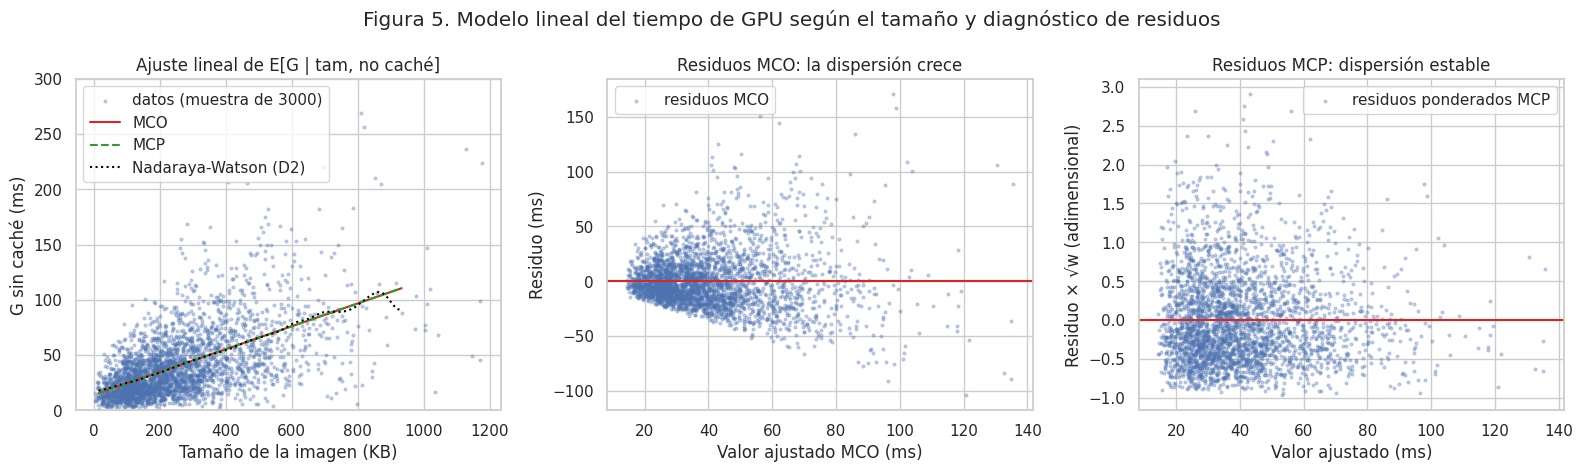

In [152]:
muestra_fig = rng.choice(n_d3, size=3000, replace=False)  # muestra de 3000 puntos para graficar
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8))  # tres paneles
ejes[0].scatter(tam_nc[muestra_fig], y_d3[muestra_fig], s=4, alpha=0.3, label="datos (muestra de 3000)")  # dispersion tamano - gpu
ejes[0].plot(grilla_tam, beta_mco[0] + beta_mco[1] * grilla_tam, color="tab:red", label="MCO")  # recta MCO
ejes[0].plot(grilla_tam, beta_mcp[0] + beta_mcp[1] * grilla_tam, color="tab:green", linestyle="--", label="MCP")  # recta MCP
ejes[0].plot(grilla_tam, curva_nc, color="black", linestyle=":", label="Nadaraya-Watson (D2)")  # curva Nadaraya-Watson
ejes[0].set_ylim(0, 300)  # limite del eje y
ejes[0].set_xlabel("Tamaño de la imagen (KB)")  # etiqueta x
ejes[0].set_ylabel("G sin caché (ms)")  # etiqueta y
ejes[0].set_title("Ajuste lineal de E[G | tam, no caché]")  # titulo
ejes[0].legend()  # leyenda

ejes[1].scatter(ajustados_mco[muestra_fig], residuos_mco[muestra_fig], s=4, alpha=0.3, label="residuos MCO")  # residuos MCO contra ajustados
ejes[1].axhline(0, color="tab:red")  # linea en cero
ejes[1].set_xlabel("Valor ajustado MCO (ms)")  # etiqueta x
ejes[1].set_ylabel("Residuo (ms)")  # etiqueta y
ejes[1].set_title("Residuos MCO: la dispersión crece")  # titulo
ejes[1].legend()  # leyenda

ejes[2].scatter(ajustados_mco[muestra_fig], residuos_estandar_mcp[muestra_fig], s=4, alpha=0.3, label="residuos ponderados MCP")  # residuos ponderados contra ajustados
ejes[2].axhline(0, color="tab:red")  # linea en cero
ejes[2].set_xlabel("Valor ajustado (ms)")  # etiqueta x
ejes[2].set_ylabel("Residuo × √w (adimensional)")  # etiqueta y
ejes[2].set_title("Residuos MCP: dispersión estable")  # titulo
ejes[2].legend()  # leyenda
fig.suptitle("Figura 5. Modelo lineal del tiempo de GPU según el tamaño y diagnóstico de residuos")  # titulo general
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de Figura 5.* La recta sigue bien a la curva no paramétrica, así que la forma lineal de la media es razonable. Los residuos de MCO se abren en forma de embudo, mientras que los residuos ponderados tienen una dispersión parecida en todo el rango. El lector debe concluir que la varianza crece con el tamaño y que MCP corrige ese problema.

**Conclusión D3.** Cada KB adicional agrega en promedio unos 0,1 ms de GPU, sobre un costo fijo de unos 14 ms. Los residuos violan el supuesto de varianza constante (su desviación estándar crece en proporción a la media), así que el intervalo clásico de MCO no es confiable. MCP con pesos 1/μ², justificado porque el error es multiplicativo (CV constante), da coeficientes parecidos pero más eficientes: los intervalos de MCP son más angostos que los de MCO con errores de White, que son la referencia válida sin ponderar. Sobre los residuos ponderados, Breusch-Pagan ya no rechaza, y su desviación estándar es casi la misma en todos los deciles: la corrección funciona. Los residuos siguen siendo asimétricos; con casi 19 000 datos eso no afecta los intervalos de los coeficientes.

## D4. Covarianza y correlación entre tam_kb y gpu_ms (sin caché)

Calculamos la covarianza y la correlación de Pearson con su intervalo por la transformación z de Fisher. Las relacionamos con D3 (en regresión simple, β̂1 = Cov / Var(tam) y R² = r²) y con D2 (fracción explicada por la clase).

In [153]:
covarianza = np.cov(tam_nc, gpu_nc, ddof=1)[0, 1]  # covarianza muestral
correlacion = np.corrcoef(tam_nc, gpu_nc)[0, 1]  # correlacion de Pearson
z_fisher = np.arctanh(correlacion)  # transformacion de Fisher
error_fisher = 1 / np.sqrt(n_d3 - 3)  # error estandar de z
corr_inf, corr_sup = np.tanh(z_fisher - z * error_fisher), np.tanh(z_fisher + z * error_fisher)  # IC de la correlacion
print("Cov(tam, G) =", round(covarianza, 2), "KB*ms")  # imprime la covarianza
print(f"r = {correlacion:.4f} [{corr_inf:.4f}, {corr_sup:.4f}], nivel {confianza}, z de Fisher")  # imprime r con IC
print("Cov / Var(tam) =", round(covarianza / tam_nc.var(ddof=1), 5), " vs beta1 MCO =", round(beta_mco[1], 5))  # compara con beta1
print("r^2 =", round(correlacion ** 2, 4), " vs R^2 MCO =", round(r2_mco, 4))  # compara r2 con R2
print("fraccion de Var(G sin cache) explicada por la clase (D2):", round(tabla_tot.iloc[2]["fraccion explicada"], 4))  # fraccion explicada por la clase
print("correlacion de Spearman (rangos):", round(stats.spearmanr(tam_nc, gpu_nc).statistic, 4))  # correlacion de Spearman

Cov(tam, G) = 3232.11 KB*ms
r = 0.5756 [0.5675, 0.5836], nivel 0.9, z de Fisher
Cov / Var(tam) = 0.1036  vs beta1 MCO = 0.1036
r^2 = 0.3313  vs R^2 MCO = 0.3313
fraccion de Var(G sin cache) explicada por la clase (D2): 0.2413
correlacion de Spearman (rangos): 0.5552


**Conclusión D4.** La covarianza es positiva y la correlación es moderada, alrededor de 0,58, con un intervalo muy angosto. La pendiente de D3 es exactamente Cov/Var(tam) y el R² es r², así que el tamaño explica cerca de un tercio de la variabilidad de G sin caché. La clase de tamaño (D2) explica menos que el tamaño continuo, porque al agrupar se pierde información dentro de cada clase. El resto de la variabilidad no depende del tamaño: viene del error multiplicativo y de la versión. Por eso los modelos marginales de C no capturan toda la estructura.

# Parte E — Monitoreo y decisión de alertas

## E1. Sensibilidad y tasa de falsos positivos de las cuatro reglas

`monitoreo.csv` tiene 6000 minutos de pruebas con incidentes inyectados. Para cada regla de alerta (D1, D2, "D1 y D2", "D1 o D2"):
- **Sensibilidad** = P(alerta | incidente): proporción de minutos con incidente en que la regla alertó.
- **Tasa de falsos positivos (TFP)** = P(alerta | sin incidente).

Ambas son proporciones binomiales; usamos intervalos de **Wilson**, porque varias TFP son muy pequeñas y ahí el intervalo de Wald funciona mal (se compara en F4).

In [154]:
monitoreo = pd.read_csv("monitoreo.csv")  # lee el monitoreo
print("minutos:", len(monitoreo), " con incidente:", monitoreo["incidente"].sum(),  # imprime minutos e incidentes
      " prevalencia en pruebas:", round(monitoreo["incidente"].mean(), 4))
print("nulos:", monitoreo.isna().sum().sum(), " minutos consecutivos sin huecos:", (monitoreo["minuto"].diff().dropna() == 1).all())  # revisa nulos y continuidad

reglas = {  # reglas de alerta
    "D1": monitoreo["D1"] == 1,  # solo D1
    "D2": monitoreo["D2"] == 1,  # solo D2
    "D1 y D2": (monitoreo["D1"] == 1) & (monitoreo["D2"] == 1),  # ambas
    "D1 o D2": (monitoreo["D1"] == 1) | (monitoreo["D2"] == 1),  # alguna
}
con_incidente = monitoreo["incidente"] == 1  # minutos con incidente
n_inc = con_incidente.sum()  # cuantos con incidente
n_sin = (~con_incidente).sum()  # cuantos sin incidente

filas_e1 = []  # filas de resultados
resultados_reglas = {}  # metricas por regla
for nombre, alerta in reglas.items():  # recorre cada regla
    verdaderos = (alerta & con_incidente).sum()  # alertas verdaderas
    falsos = (alerta & ~con_incidente).sum()  # alertas falsas
    ic_sens = stats.binomtest(verdaderos, n_inc).proportion_ci(confidence_level=confianza, method="wilson")  # IC Wilson de la sensibilidad
    ic_tfp = stats.binomtest(falsos, n_sin).proportion_ci(confidence_level=confianza, method="wilson")  # IC Wilson de la TFP
    resultados_reglas[nombre] = {"vp": verdaderos, "fp": falsos, "sens": verdaderos / n_inc, "tfp": falsos / n_sin}  # guarda las metricas
    filas_e1.append([nombre, f"{verdaderos / n_inc:.4f} [{ic_sens.low:.4f}, {ic_sens.high:.4f}]",  # guarda la fila
                     f"{falsos / n_sin:.5f} [{ic_tfp.low:.5f}, {ic_tfp.high:.5f}]", verdaderos, falsos])
print(pd.DataFrame(filas_e1, columns=["regla", "sensibilidad [Wilson]", "TFP [Wilson]", "VP", "FP"]).to_string(index=False))  # imprime la tabla
print(f"nivel {confianza}; n con incidente = {n_inc}, n sin incidente = {n_sin}")  # imprime nivel y tamanos

minutos: 6000  con incidente: 582  prevalencia en pruebas: 0.097
nulos: 0  minutos consecutivos sin huecos: True
  regla   sensibilidad [Wilson]               TFP [Wilson]  VP  FP
     D1 0.8969 [0.8743, 0.9158] 0.01347 [0.01113, 0.01630] 522  73
     D2 0.7766 [0.7470, 0.8037] 0.00831 [0.00651, 0.01059] 452  45
D1 y D2 0.6959 [0.6637, 0.7263] 0.00221 [0.00138, 0.00354] 405  12
D1 o D2 0.9777 [0.9652, 0.9857] 0.01956 [0.01670, 0.02291] 569 106
nivel 0.9; n con incidente = 582, n sin incidente = 5418


**Conclusión E1.** D1 es más sensible que D2 y también tiene más falsos positivos. "D1 o D2" detecta casi todos los incidentes, pero suma las falsas alarmas de ambos detectores; "D1 y D2" es la más conservadora: pierde cerca de un tercio de los incidentes, pero su TFP es varias veces menor. Las TFP son del orden de 10⁻³ a 10⁻², así que sus intervalos relativos son anchos, aunque haya 5418 minutos sin incidente.

## E2. Probabilidad de incidente real dada una alerta, en producción

Por el teorema de Bayes, con prevalencia π de producción:

P(incidente | alerta) = sens·π / (sens·π + TFP·(1 − π)).

Usamos π = 0,004, la de nuestro grupo, **no** la de `monitoreo.csv` (0,097), porque allí los incidentes se inyectaron a propósito. El intervalo se obtiene propagando la incertidumbre de sens y TFP con un bootstrap paramétrico (re-simulando los conteos binomiales). Verificamos el resultado por Montecarlo, simulando minutos de producción: primero se decide si hay incidente con probabilidad π y luego se toma la pareja (D1, D2) de un minuto real de `monitoreo.csv` del mismo estado. Así se conserva la dependencia entre los detectores.

In [155]:
replicas_e2 = 20000  # replicas bootstrap
filas_e2 = []  # filas de resultados
vpp_boot = {}  # VPP simulados por regla
for nombre, res in resultados_reglas.items():  # recorre cada regla
    vpp = res["sens"] * pi_prod / (res["sens"] * pi_prod + res["tfp"] * (1 - pi_prod))  # valor predictivo positivo por Bayes
    vpp_pruebas = res["vp"] / (res["vp"] + res["fp"])  # lo que daria monitoreo.csv directamente
    sens_b = rng.binomial(n_inc, res["sens"], size=replicas_e2) / n_inc  # sensibilidad simulada
    tfp_b = rng.binomial(n_sin, res["tfp"], size=replicas_e2) / n_sin  # TFP simulada
    vpp_b = sens_b * pi_prod / (sens_b * pi_prod + tfp_b * (1 - pi_prod))  # VPP simulado
    vpp_boot[nombre] = vpp_b  # guarda las simulaciones
    inf_v, sup_v = np.quantile(vpp_b, [alpha / 2, 1 - alpha / 2])  # IC por percentiles
    filas_e2.append([nombre, f"{vpp:.4f} [{inf_v:.4f}, {sup_v:.4f}]", round(vpp_pruebas, 4)])  # guarda la fila
print(pd.DataFrame(filas_e2, columns=["regla", "P(incidente | alerta) produccion [bootstrap]", "P(incidente | alerta) en monitoreo.csv"]).to_string(index=False))  # imprime la tabla
print(f"pi = {pi_prod}, nivel {confianza}, bootstrap parametrico con {replicas_e2} replicas")  # imprime parametros

  regla P(incidente | alerta) produccion [bootstrap]  P(incidente | alerta) en monitoreo.csv
     D1                      0.2109 [0.1826, 0.2471]                                  0.8773
     D2                      0.2730 [0.2302, 0.3300]                                  0.9095
D1 y D2                      0.5579 [0.4556, 0.6891]                                  0.9712
D1 o D2                      0.1671 [0.1477, 0.1917]                                  0.8430
pi = 0.004, nivel 0.9, bootstrap parametrico con 20000 replicas


In [156]:
minutos_mc = 5_000_000  # minutos simulados
incidente_mc = rng.random(minutos_mc) < pi_prod  # minutos con incidente simulados
filas_inc = monitoreo[con_incidente][["D1", "D2"]].values  # filas de monitoreo con incidente
filas_sin = monitoreo[~con_incidente][["D1", "D2"]].values  # filas de monitoreo sin incidente
d1d2_mc = np.where(incidente_mc[:, None],  # elige fila segun haya o no incidente
                   filas_inc[rng.integers(0, len(filas_inc), size=minutos_mc)],
                   filas_sin[rng.integers(0, len(filas_sin), size=minutos_mc)])
alertas_mc = {"D1": d1d2_mc[:, 0] == 1, "D2": d1d2_mc[:, 1] == 1,  # alertas por regla
              "D1 y D2": (d1d2_mc[:, 0] == 1) & (d1d2_mc[:, 1] == 1),
              "D1 o D2": (d1d2_mc[:, 0] == 1) | (d1d2_mc[:, 1] == 1)}
print("regla      Bayes      Montecarlo")  # encabezado
for nombre, res in resultados_reglas.items():  # recorre cada regla
    vpp = res["sens"] * pi_prod / (res["sens"] * pi_prod + res["tfp"] * (1 - pi_prod))  # VPP por Bayes
    print(f"{nombre:8s}  {vpp:.4f}     {incidente_mc[alertas_mc[nombre]].mean():.4f}")  # VPP por Montecarlo

regla      Bayes      Montecarlo
D1        0.2109     0.2133
D2        0.2730     0.2764
D1 y D2   0.5579     0.5629
D1 o D2   0.1671     0.1693


**Conclusión E2.** En producción, una alerta de D1, de D2 o de "D1 o D2" corresponde a un incidente real solo entre el 17 % y el 27 % de las veces: la mayoría son falsas alarmas. Solo "D1 y D2" sube a cerca de 0,56, aunque con un intervalo ancho. Las cifras que salen directamente de `monitoreo.csv` son mucho más altas porque allí hay incidentes en casi el 10 % de los minutos, unas 24 veces más que en producción. El valor predictivo depende de la prevalencia: con incidentes raros, incluso una TFP pequeña genera más falsas alarmas que alertas verdaderas. Montecarlo reproduce los valores de Bayes.

## E3. ¿Son D1 y D2 condicionalmente independientes dado el estado?

Si fueran condicionalmente independientes, dentro de cada estado (con o sin incidente) se cumpliría P(D1 = 1, D2 = 1 | estado) = P(D1 = 1 | estado)·P(D2 = 1 | estado). Lo probamos con la prueba exacta de Fisher en la tabla 2×2 de cada estado y estimamos la razón de odds con un intervalo (Woolf, sobre el logaritmo, con +0,5 en cada celda por si hay ceros).

In [157]:
for estado, nombre_estado in [(1, "con incidente"), (0, "sin incidente")]:  # recorre con y sin incidente
    sub = monitoreo[monitoreo["incidente"] == estado]  # filas del estado
    tabla_e3 = pd.crosstab(sub["D1"], sub["D2"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)  # tabla 2x2 D1 contra D2
    a, b_, c, d = tabla_e3.loc[1, 1], tabla_e3.loc[1, 0], tabla_e3.loc[0, 1], tabla_e3.loc[0, 0]  # celdas a, b, c, d
    odds = ((a + 0.5) * (d + 0.5)) / ((b_ + 0.5) * (c + 0.5))  # razon de odds con correccion 0.5
    error_log = np.sqrt(1 / (a + 0.5) + 1 / (b_ + 0.5) + 1 / (c + 0.5) + 1 / (d + 0.5))  # error del log odds (Woolf)
    fisher = stats.fisher_exact(tabla_e3.values)  # prueba exacta de Fisher
    p_conj = a / len(sub)  # P(D1=1, D2=1) observada
    p_prod = sub["D1"].mean() * sub["D2"].mean()  # producto de marginales
    print(f"--- {nombre_estado} (n = {len(sub)}) ---")  # imprime el estado
    print(tabla_e3)  # imprime la tabla
    print(f"P(D1=1, D2=1) observada = {p_conj:.5f}   producto de marginales = {p_prod:.5f}   razon = {p_conj / p_prod:.2f}")  # imprime la comparacion
    print(f"razon de odds = {odds:.2f} [{np.exp(np.log(odds) - z * error_log):.2f}, {np.exp(np.log(odds) + z * error_log):.2f}], nivel {confianza}, Woolf")  # imprime la razon de odds
    print(f"Fisher exacta: p-valor = {fisher.pvalue:.3g}")  # imprime el p-valor de Fisher
    print()  # linea en blanco

--- con incidente (n = 582) ---
D2    0    1
D1          
0    13   47
1   117  405
P(D1=1, D2=1) observada = 0.69588   producto de marginales = 0.69657   razon = 1.00
razon de odds = 0.98 [0.57, 1.68], nivel 0.9, Woolf
Fisher exacta: p-valor = 1

--- sin incidente (n = 5418) ---
D2     0   1
D1          
0   5312  33
1     61  12
P(D1=1, D2=1) observada = 0.00221   producto de marginales = 0.00011   razon = 19.79
razon de odds = 32.23 [17.96, 57.83], nivel 0.9, Woolf
Fisher exacta: p-valor = 2.83e-13



Ahora cuantificamos qué pasaría en E2 si supusiéramos independencia condicional sin verificarla. Con independencia, sens(D1 y D2) = s1·s2, TFP(D1 y D2) = f1·f2 y, para "o", 1 − (1 − s1)(1 − s2) y 1 − (1 − f1)(1 − f2).

In [158]:
s1, f1 = resultados_reglas["D1"]["sens"], resultados_reglas["D1"]["tfp"]  # sensibilidad y TFP de D1
s2, f2 = resultados_reglas["D2"]["sens"], resultados_reglas["D2"]["tfp"]  # sensibilidad y TFP de D2
supuesto = {"D1 y D2": (s1 * s2, f1 * f2), "D1 o D2": (1 - (1 - s1) * (1 - s2), 1 - (1 - f1) * (1 - f2))}  # valores si D1 y D2 fueran independientes
filas_e3 = []  # filas de resultados
for nombre, (sens_ind, tfp_ind) in supuesto.items():  # recorre cada regla combinada
    res = resultados_reglas[nombre]  # valores reales de la regla
    vpp_real = res["sens"] * pi_prod / (res["sens"] * pi_prod + res["tfp"] * (1 - pi_prod))  # VPP real
    vpp_ind = sens_ind * pi_prod / (sens_ind * pi_prod + tfp_ind * (1 - pi_prod))  # VPP bajo independencia
    filas_e3.append([nombre, res["sens"], sens_ind, res["tfp"], tfp_ind, vpp_real, vpp_ind])  # guarda la fila
print(pd.DataFrame(filas_e3, columns=["regla", "sens real", "sens si indep.", "TFP real", "TFP si indep.",  # imprime la tabla
                                      "P(inc|alerta) real", "P(inc|alerta) si indep."]).round(5).to_string(index=False))

  regla  sens real  sens si indep.  TFP real  TFP si indep.  P(inc|alerta) real  P(inc|alerta) si indep.
D1 y D2    0.69588         0.69657   0.00221        0.00011             0.55787                  0.96154
D1 o D2    0.97766         0.97697   0.01956        0.02167             0.16714                  0.15332


**Conclusión E3.** Con incidente, D1 y D2 se comportan como independientes (la probabilidad conjunta es casi igual al producto y Fisher no rechaza). Sin incidente, en cambio, hay una dependencia fuerte: las falsas alarmas de ambos detectores ocurren juntas unas 20 veces más de lo que predice la independencia (Fisher con p-valor muy pequeño, razón de odds muy por encima de 1). Una explicación plausible es que ciertos eventos que no son incidentes (picos de carga, mantenimientos) disparan a la vez el detector de latencia y el de errores. Si se supusiera independencia, la TFP de "D1 y D2" quedaría unas 20 veces por debajo de la real y su P(incidente | alerta) parecería cercana a 0,95, cuando en realidad es de alrededor de 0,5. Suponer independencia sin verificarla llevaría a una regla mucho peor de lo que se cree.

## E4. Falsas alarmas por día y elección de la regla

En un día hay 1440 minutos. En cada uno hay falsa alarma si no hay incidente y la regla alerta, con probabilidad (1 − π)·TFP. Si los minutos son independientes (lo comprobamos con la autocorrelación de las falsas alarmas en `monitoreo.csv`), el número de falsas alarmas en un día es FA ~ Binomial(1440, (1 − π)·TFP). La exigencia es P(FA ≤ k_max) ≥ 0,90, con k_max = 6.

**Propagación de la incertidumbre.** La TFP es una estimación, así que P(FA ≤ k_max) también lo es. Re-muestreamos la TFP con su distribución a posteriori Beta(FP + ½, n − FP + ½) (previa de Jeffreys, que se comporta bien con proporciones pequeñas), calculamos P(FA ≤ k_max) para cada valor simulado y reportamos su intervalo y la probabilidad de que la regla cumpla.

In [159]:
for nombre in reglas:  # recorre cada regla
    falsas = (reglas[nombre] & ~con_incidente).astype(float).values  # falsas alarmas minuto a minuto
    autocorr_fa = [np.corrcoef(falsas[:-k], falsas[k:])[0, 1] for k in [1, 2, 5]]  # autocorrelacion en varios rezagos
    print(f"autocorrelacion de falsas alarmas {nombre:8s} (rezagos 1, 2, 5):", np.round(autocorr_fa, 4))  # imprime las autocorrelaciones
print("banda de independencia: +/-", round(z / np.sqrt(len(monitoreo)), 4))  # imprime la banda

autocorrelacion de falsas alarmas D1       (rezagos 1, 2, 5): [ 0.0015  0.0015 -0.0123]
autocorrelacion de falsas alarmas D2       (rezagos 1, 2, 5): [-0.0076  0.0148 -0.0076]
autocorrelacion de falsas alarmas D1 y D2  (rezagos 1, 2, 5): [-0.002 -0.002 -0.002]
autocorrelacion de falsas alarmas D1 o D2  (rezagos 1, 2, 5): [0.0204 0.0204 0.0012]
banda de independencia: +/- 0.0212


In [160]:
minutos_dia = 1440  # minutos de un dia
replicas_e4 = 20000  # replicas de la posterior
filas_e4 = []  # filas de resultados
prob_cumplir_boot = {}  # P(cumplir) simulado por regla
for nombre, res in resultados_reglas.items():  # recorre cada regla
    prob_fa = (1 - pi_prod) * res["tfp"]  # prob. de falsa alarma por minuto
    prob_ok = stats.binom.cdf(k_max, minutos_dia, prob_fa)  # P(FA <= k_max) binomial
    tfp_post = rng.beta(res["fp"] + 0.5, n_sin - res["fp"] + 0.5, size=replicas_e4)  # TFP posterior Beta (Jeffreys)
    prob_ok_post = stats.binom.cdf(k_max, minutos_dia, (1 - pi_prod) * tfp_post)  # P(cumplir) con incertidumbre
    prob_cumplir_boot[nombre] = prob_ok_post  # guarda las simulaciones
    inf_ok, sup_ok = np.quantile(prob_ok_post, [alpha / 2, 1 - alpha / 2])  # IC por percentiles
    filas_e4.append([nombre, res["tfp"], minutos_dia * prob_fa, f"{prob_ok:.4f} [{inf_ok:.4f}, {sup_ok:.4f}]",  # guarda la fila
                     prob_ok >= 0.90, (prob_ok_post >= 0.90).mean(), res["sens"]])
tabla_e4 = pd.DataFrame(filas_e4, columns=["regla", "TFP", "FA esperadas/dia", "P(FA <= k_max) [IC]", "cumple (puntual)",  # arma la tabla
                                           "P(cumple) con incertidumbre", "sensibilidad"])
print(tabla_e4.round(4).to_string(index=False))  # imprime la tabla
print(f"k_max = {k_max}, nivel {confianza}, intervalo por la a posteriori de Jeffreys")  # imprime parametros
tfp_limite = optimize.brentq(lambda t: stats.binom.cdf(k_max, minutos_dia, (1 - pi_prod) * t) - 0.90, 1e-6, 0.05)  # TFP maxima por busqueda de raiz
print("TFP maxima que cumple la exigencia:", round(tfp_limite, 5))  # imprime la TFP maxima

  regla    TFP  FA esperadas/dia     P(FA <= k_max) [IC]  cumple (puntual)  P(cumple) con incertidumbre  sensibilidad
     D1 0.0135           19.3244 0.0004 [0.0000, 0.0041]             False                       0.0000        0.8969
     D2 0.0083           11.9123 0.0475 [0.0070, 0.1843]             False                       0.0000        0.7766
D1 y D2 0.0022            3.1766 0.9570 [0.7614, 0.9964]              True                       0.7512        0.6959
D1 o D2 0.0196           28.0601 0.0000 [0.0000, 0.0000]             False                       0.0000        0.9777
k_max = 6, nivel 0.9, intervalo por la a posteriori de Jeffreys
TFP maxima que cumple la exigencia: 0.00272


Verificamos por Montecarlo la probabilidad de cumplir de la regla "D1 y D2": simulamos 100 000 días de producción, minuto a minuto (incidente con probabilidad π y, si no hay incidente, falsa alarma con la TFP estimada).

In [161]:
dias_mc = 100000  # dias simulados
tfp_y = resultados_reglas["D1 y D2"]["tfp"]  # TFP de la regla D1 y D2
falsas_por_dia = np.zeros(dias_mc, dtype=int)  # falsas alarmas por dia
for inicio in range(0, dias_mc, 10000):  # simula por lotes de 10000 dias
    sin_incidente = rng.random((10000, minutos_dia)) >= pi_prod  # minutos sin incidente
    alerta_falsa = rng.random((10000, minutos_dia)) < tfp_y  # alerta falsa en el minuto
    falsas_por_dia[inicio:inicio + 10000] = (sin_incidente & alerta_falsa).sum(axis=1)  # cuenta falsas alarmas por dia
print("P(FA <= k_max) para 'D1 y D2': binomial =", round(stats.binom.cdf(k_max, minutos_dia, (1 - pi_prod) * tfp_y), 4),  # compara binomial y Montecarlo
      "  Montecarlo =", round((falsas_por_dia <= k_max).mean(), 4))

P(FA <= k_max) para 'D1 y D2': binomial = 0.957   Montecarlo = 0.9576


**Figura 6.** P(FA ≤ k_max) en un día en función de la TFP de la regla, con la exigencia de 0,90. Los puntos son las estimaciones de cada regla y las barras sus intervalos (a posteriori de Jeffreys).

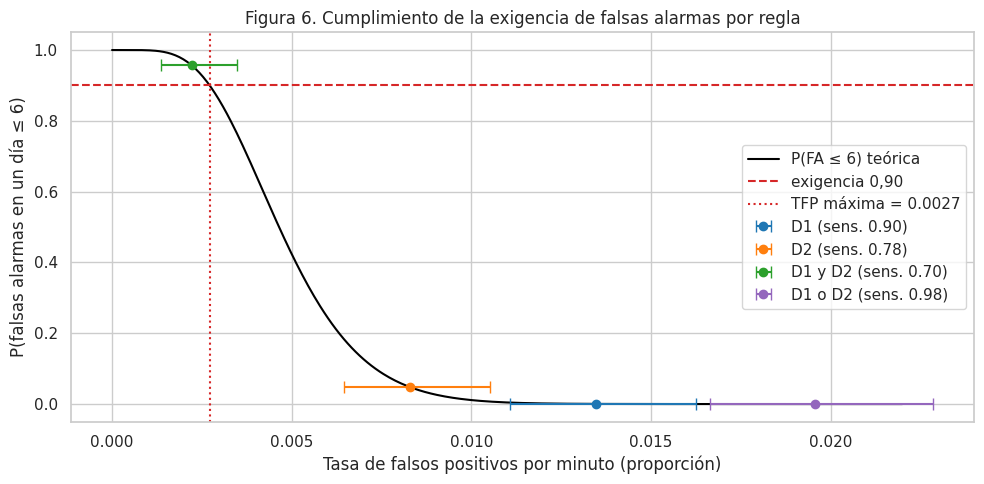

In [162]:
tfp_grilla = np.linspace(0, 0.022, 400)  # rejilla de TFP
fig, eje = plt.subplots(figsize=(10, 5))  # figura
eje.plot(tfp_grilla, stats.binom.cdf(k_max, minutos_dia, (1 - pi_prod) * tfp_grilla), color="black", label=f"P(FA ≤ {k_max}) teórica")  # curva teorica P(FA <= k_max)
eje.axhline(0.90, color="tab:red", linestyle="--", label="exigencia 0,90")  # exigencia 0.90
eje.axvline(tfp_limite, color="tab:red", linestyle=":", label=f"TFP máxima = {tfp_limite:.4f}")  # TFP maxima
colores = {"D1": "tab:blue", "D2": "tab:orange", "D1 y D2": "tab:green", "D1 o D2": "tab:purple"}  # colores por regla
for nombre, res in resultados_reglas.items():  # recorre cada regla
    inf_t, sup_t = stats.beta.ppf([alpha / 2, 1 - alpha / 2], res["fp"] + 0.5, n_sin - res["fp"] + 0.5)  # IC beta de la TFP
    y_punto = stats.binom.cdf(k_max, minutos_dia, (1 - pi_prod) * res["tfp"])  # P(cumplir) en el punto
    eje.errorbar(res["tfp"], y_punto, xerr=[[res["tfp"] - inf_t], [sup_t - res["tfp"]]], fmt="o", color=colores[nombre],  # punto con barra de error
                 capsize=4, label=f"{nombre} (sens. {res['sens']:.2f})")
eje.set_xlabel("Tasa de falsos positivos por minuto (proporción)")  # etiqueta x
eje.set_ylabel(f"P(falsas alarmas en un día ≤ {k_max})")  # etiqueta y
eje.set_title("Figura 6. Cumplimiento de la exigencia de falsas alarmas por regla")  # titulo
eje.legend(loc="center right")  # leyenda
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de Figura 6.* Solo la regla "D1 y D2" queda por encima de 0,90; D1, D2 y "D1 o D2" tienen una probabilidad de cumplir prácticamente nula. El lector debe concluir que, de las cuatro, "D1 y D2" es la única regla aceptable para el equipo de guardia, aunque su intervalo de TFP se acerca al límite.

**Conclusión E4.** Para cumplir la exigencia, una regla debe tener una TFP por minuto menor que el límite calculado arriba (unas 4 falsas alarmas esperadas por día como máximo). Solo "D1 y D2" lo logra, pero al propagar la incertidumbre de su TFP cumple en cerca de 3 de cada 4 escenarios: su intervalo para P(FA ≤ k_max) llega a bajar a unos 0,76 en el extremo pesimista, porque su TFP se estimó con solo 12 falsas alarmas. Las otras tres reglas producirían de 12 a 28 falsas alarmas por día y prácticamente no cumplen en ningún escenario. **Recomendación:** adoptar "D1 y D2". El costo es que pierde cerca del 30 % de los incidentes (sensibilidad cercana a 0,70), así que conviene complementarla con una revisión periódica de D1 sola, sin despertar a la guardia, y volver a estimar su TFP con datos de producción, porque su incertidumbre todavía es grande.

# Parte F — Inferencia, distribuciones muestrales y comparación de versiones

## F1. Distribución muestral de la media de la latencia

**Población.** Tomamos como población las latencias válidas del régimen estable (después de la limpieza de A1). Es la mejor representación disponible de la latencia del sistema en operación normal; el régimen anómalo es otra población. Para cada n ∈ {5, 30, 200, 2000} extraemos 10 000 muestras con reemplazo (muestreo aleatorio simple de esa población), calculamos la media de cada una y describimos su distribución. Luego medimos la cobertura efectiva del intervalo normal x̄ ± z·s/√n frente a la media poblacional, y buscamos el menor n en que la cobertura llega a (1 − α) − 0,01.

In [163]:
poblacion = estable["latencia_ms"].dropna().values  # latencias estables como poblacion
media_pob = poblacion.mean()  # media poblacional
print("tamano de la poblacion:", len(poblacion), " media:", round(media_pob, 3), " DE:", round(poblacion.std(), 3),  # imprime resumen de la poblacion
      " asimetria:", round(stats.skew(poblacion), 3), " curtosis exceso:", round(stats.kurtosis(poblacion), 3))

replicas_f1 = 10000  # replicas por tamano
medias_por_n = {}  # medias simuladas por n
filas_f1 = []  # filas de resultados
for n_muestra in [5, 30, 200, 2000]:  # tamanos de muestra
    muestras = rng.choice(poblacion, size=(replicas_f1, n_muestra), replace=True)  # remuestreo con reemplazo
    medias = muestras.mean(axis=1)  # media de cada muestra
    medias_por_n[n_muestra] = medias  # guarda las medias
    filas_f1.append([n_muestra, medias.mean(), medias.std(), poblacion.std() / np.sqrt(n_muestra),  # guarda estadisticos de las medias
                     stats.skew(medias), stats.kurtosis(medias), stats.skew(poblacion) / np.sqrt(n_muestra)])
print(pd.DataFrame(filas_f1, columns=["n", "media de medias", "DE de medias", "sigma/sqrt(n)", "asimetria", "curtosis exceso",  # imprime la tabla
                                      "asimetria teorica"]).round(4).to_string(index=False))

tamano de la poblacion: 29243  media: 48.413  DE: 36.108  asimetria: 1.891  curtosis exceso: 5.451
   n  media de medias  DE de medias  sigma/sqrt(n)  asimetria  curtosis exceso  asimetria teorica
   5          48.5847       16.1638        16.1482     0.8644           1.0943             0.8457
  30          48.5526        6.5712         6.5925     0.3064           0.0584             0.3452
 200          48.4206        2.5447         2.5533     0.1528          -0.0230             0.1337
2000          48.4240        0.7997         0.8074    -0.0227          -0.0719             0.0423


In [164]:
objetivo_cobertura = confianza - 0.01  # cobertura objetivo
valores_n = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 500, 1000, 2000]  # tamanos de muestra a probar
coberturas_f1 = []  # coberturas observadas
for n_muestra in valores_n:  # recorre cada tamano
    muestras = rng.choice(poblacion, size=(replicas_f1, n_muestra), replace=True)  # remuestreo con reemplazo
    medias = muestras.mean(axis=1)  # media de cada muestra
    errores = muestras.std(axis=1, ddof=1) / np.sqrt(n_muestra)  # error estandar de cada muestra
    coberturas_f1.append((np.abs(medias - media_pob) <= z * errores).mean())  # cobertura del IC normal
error_mc_f1 = np.sqrt(confianza * (1 - confianza) / replicas_f1)  # error Montecarlo de la cobertura
print(pd.DataFrame({"n": valores_n, "cobertura efectiva": coberturas_f1}).round(4).to_string(index=False))  # imprime la tabla
n_minimo_f1 = next(n_m for n_m, cob in zip(valores_n, coberturas_f1) if cob >= objetivo_cobertura)  # menor n que alcanza el objetivo
print(f"objetivo: {objetivo_cobertura:.2f}  (error Montecarlo de cada cobertura ~ {error_mc_f1:.4f})")  # imprime objetivo y error
print("menor n de la grilla que alcanza el objetivo:", n_minimo_f1)  # imprime el n minimo

   n  cobertura efectiva
   5              0.7822
  10              0.8300
  20              0.8539
  30              0.8713
  50              0.8835
  75              0.8904
 100              0.8938
 150              0.8962
 200              0.9021
 300              0.8942
 500              0.8989
1000              0.9028
2000              0.8978
objetivo: 0.89  (error Montecarlo de cada cobertura ~ 0.0030)
menor n de la grilla que alcanza el objetivo: 75


**Figura 7.** Distribución muestral de la media de la latencia (10 000 réplicas) para cada n, con la densidad normal que predice el teorema del límite central, N(μ, σ²/n).

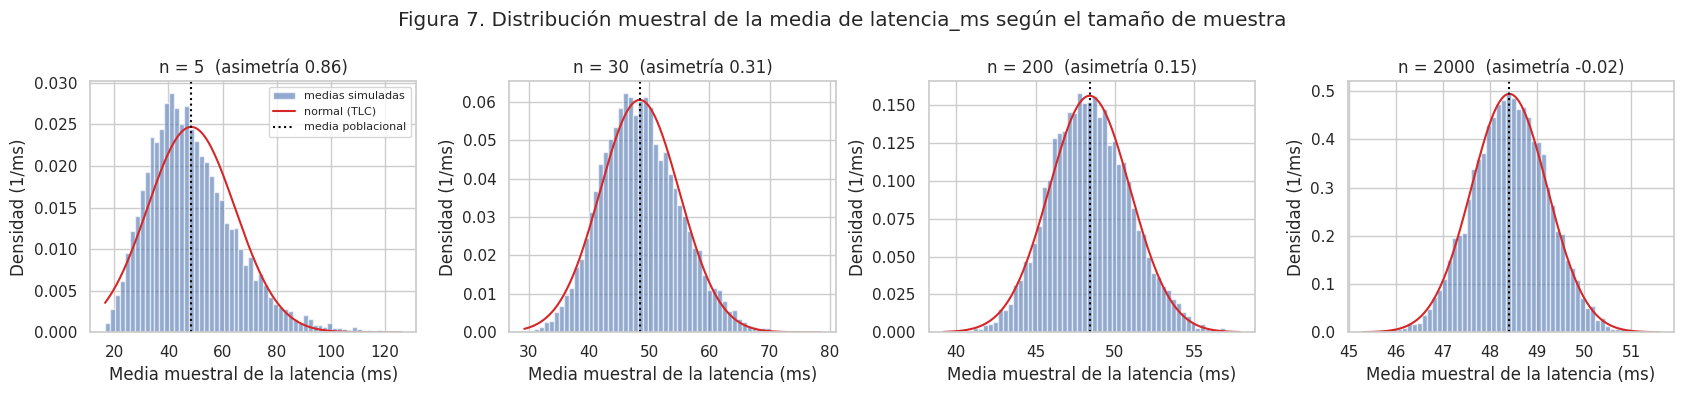

In [165]:
fig, ejes = plt.subplots(1, 4, figsize=(17, 4))  # cuatro paneles
for eje, n_muestra in zip(ejes, [5, 30, 200, 2000]):  # un panel por tamano
    medias = medias_por_n[n_muestra]  # medias simuladas
    eje.hist(medias, bins=60, density=True, alpha=0.6, label="medias simuladas")  # histograma de las medias
    x_f1 = np.linspace(medias.min(), medias.max(), 300)  # rejilla para la normal
    eje.plot(x_f1, stats.norm.pdf(x_f1, media_pob, poblacion.std() / np.sqrt(n_muestra)), color="tab:red", label="normal (TLC)")  # normal teorica del TLC
    eje.axvline(media_pob, color="black", linestyle=":", label="media poblacional")  # media poblacional
    eje.set_title(f"n = {n_muestra}  (asimetría {stats.skew(medias):.2f})")  # titulo
    eje.set_xlabel("Media muestral de la latencia (ms)")  # etiqueta x
    eje.set_ylabel("Densidad (1/ms)")  # etiqueta y
ejes[0].legend(fontsize=8)  # leyenda
fig.suptitle("Figura 7. Distribución muestral de la media de latencia_ms según el tamaño de muestra")  # titulo general
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de Figura 7.* Con n = 5 la distribución de la media todavía es claramente asimétrica a la derecha. A partir de n = 200 ya es prácticamente normal y cada vez más angosta (su dispersión baja como 1/√n). El lector debe concluir que, para latencias tan asimétricas, el teorema del límite central necesita muestras de cientos de datos.

**Conclusión F1.** La media de las medias coincide con la media poblacional para todo n (la media muestral es insesgada) y su desviación estándar sigue σ/√n. La asimetría baja como asimetría/√n y la curtosis baja todavía más rápido. Con n pequeño el intervalo normal cubre menos de lo nominal, porque la media y la desviación estándar muestral están correlacionadas en poblaciones asimétricas. La tabla de coberturas da el menor n de la grilla que alcanza (1 − α) − 0,01.

## F2. Intervalo para la latencia media y revisión de supuestos

El intervalo clásico x̄ ± t·s/√n supone observaciones **independientes** e idénticamente distribuidas; la normalidad solo importa con n pequeño. Las latencias de solicitudes cercanas en el tiempo comparten la cola, así que pueden estar correlacionadas. Lo revisamos con la autocorrelación en orden de llegada.

**Corrección: medias por lotes (batch means).** Partimos la serie, en orden de llegada, en lotes consecutivos de B solicitudes. Si B es mucho mayor que el alcance de la autocorrelación, las medias de los lotes son casi independientes, y el intervalo t sobre esas medias tiene en cuenta la correlación. Probamos varios B para ver si el error estándar se estabiliza.

In [166]:
latencia_ordenada = estable.sort_values("t_llegada_s")["latencia_ms"].dropna().values  # latencias en orden temporal
n_lat = len(latencia_ordenada)  # tamano de la muestra
media_lat = latencia_ordenada.mean()  # media de latencia
error_clasico = latencia_ordenada.std(ddof=1) / np.sqrt(n_lat)  # error estandar clasico
t_f2 = stats.t.ppf(1 - alpha / 2, n_lat - 1)  # cuantil t
print(f"latencia media = {media_lat:.3f} [{media_lat - t_f2 * error_clasico:.3f}, {media_lat + t_f2 * error_clasico:.3f}] ms, nivel {confianza}, t clasico (iid)")  # IC t clasico

rezagos = [1, 2, 3, 5, 10, 20, 50]  # rezagos a revisar
autocorrs_lat = [np.corrcoef(latencia_ordenada[:-k], latencia_ordenada[k:])[0, 1] for k in rezagos]  # autocorrelaciones
print("autocorrelacion por rezago:", dict(zip(rezagos, np.round(autocorrs_lat, 4))))  # imprime autocorrelaciones
print("banda de independencia: +/-", round(z / np.sqrt(n_lat), 4))  # imprime la banda

latencia media = 48.413 [48.065, 48.760] ms, nivel 0.9, t clasico (iid)
autocorrelacion por rezago: {1: np.float64(0.1153), 2: np.float64(0.1211), 3: np.float64(0.0847), 5: np.float64(0.0454), 10: np.float64(0.0196), 20: np.float64(0.0062), 50: np.float64(0.0065)}
banda de independencia: +/- 0.0096


In [167]:
filas_f2 = []  # filas de resultados
for tam_lote in [25, 50, 100, 200, 400]:  # prueba varios tamanos de lote
    num_lotes = n_lat // tam_lote  # numero de lotes
    medias_lote = latencia_ordenada[:num_lotes * tam_lote].reshape(num_lotes, tam_lote).mean(axis=1)  # media de cada lote
    error_lotes = medias_lote.std(ddof=1) / np.sqrt(num_lotes)  # error estandar por lotes
    t_lotes = stats.t.ppf(1 - alpha / 2, num_lotes - 1)  # cuantil t con lotes
    filas_f2.append([tam_lote, num_lotes, error_lotes, error_lotes / error_clasico,  # guarda la fila
                     f"[{media_lat - t_lotes * error_lotes:.3f}, {media_lat + t_lotes * error_lotes:.3f}]"])
tabla_f2 = pd.DataFrame(filas_f2, columns=["B", "lotes", "error estandar", "razon vs clasico", "IC"])  # arma la tabla
print(tabla_f2.round(4).to_string(index=False))  # imprime la tabla

lote_elegido = 100  # lote elegido
fila_elegida = tabla_f2[tabla_f2["B"] == lote_elegido].iloc[0]  # fila del lote elegido
print(f"\nlatencia media = {media_lat:.3f} {fila_elegida['IC']} ms, nivel {confianza}, medias por lotes (B = {lote_elegido})")  # imprime el IC por lotes
print(f"ancho clasico = {2 * t_f2 * error_clasico:.3f} ms  ancho corregido = {2 * stats.t.ppf(1 - alpha / 2, fila_elegida['lotes'] - 1) * fila_elegida['error estandar']:.3f} ms")  # compara anchos
tam_efectivo = n_lat * (error_clasico / fila_elegida["error estandar"]) ** 2  # tamano de muestra efectivo
print("tamano de muestra efectivo aproximado:", round(tam_efectivo))  # imprime el tamano efectivo

  B  lotes  error estandar  razon vs clasico               IC
 25   1169          0.3069            1.4534 [47.907, 48.918]
 50    584          0.3202            1.5165 [47.885, 48.940]
100    292          0.3365            1.5934 [47.857, 48.968]
200    146          0.3516            1.6650 [47.831, 48.995]
400     73          0.3384            1.6025 [47.849, 48.976]

latencia media = 48.413 [47.857, 48.968] ms, nivel 0.9, medias por lotes (B = 100)
ancho clasico = 0.695 ms  ancho corregido = 1.110 ms
tamano de muestra efectivo aproximado: 11517


**Conclusión F2.** Las latencias consecutivas tienen una autocorrelación positiva clara en los primeros rezagos, que desaparece después de unas decenas de solicitudes. El intervalo clásico es entonces demasiado angosto. Con medias por lotes, el error estándar se estabiliza desde B ≈ 50 a 100 y resulta cerca de 1,5 veces el clásico, así que el intervalo correcto es cerca de un 50 % más ancho. Equivale a tener menos de la mitad de observaciones independientes. La asimetría no es problema aquí (n es enorme, F1). La media puntual no cambia; lo que cambia es cuánto podemos confiar en ella.

## F3. Comparación de la versión B con la A

Comparamos B − A en tres métricas del régimen estable:
1. tiempo medio de GPU de las solicitudes sin caché (diferencia de medias, Welch);
2. probabilidad de necesitar más de un intento (diferencia de proporciones, Wald);
3. probabilidad de latencia mayor que τ (diferencia de proporciones, Wald).

Como las tres conclusiones se reportan **juntas**, ajustamos por comparaciones múltiples con **Bonferroni**: cada intervalo se construye al nivel 1 − α/3, así la probabilidad de que los tres cubran a la vez es al menos 1 − α.

Antes revisamos que la asignación aleatoria dejó grupos comparables en lo que no depende de la versión: cantidad, tamaño, caché, red y momento de llegada.

In [168]:
version_a = estable[estable["version"] == "A"]  # solicitudes de la version A
version_b = estable[estable["version"] == "B"]  # solicitudes de la version B
print("solicitudes A:", len(version_a), " B:", len(version_b),  # imprime tamanos
      " p-valor (binomial 50/50):", round(stats.binomtest(len(version_b), len(estable), 0.5).pvalue, 3))  # prueba binomial 50/50


def diferencia_estandarizada(x_a, x_b):  # diferencia estandarizada
    return (x_b.mean() - x_a.mean()) / np.sqrt((x_a.var(ddof=1) + x_b.var(ddof=1)) / 2)  # devuelve la diferencia


filas_balance = []  # filas de balance
for variable in ["tam_kb", "red_ms", "t_llegada_s", "cache_hit"]:  # variables a comparar
    x_a = version_a[variable].dropna()  # valores de A
    x_b = version_b[variable].dropna()  # valores de B
    if variable == "cache_hit":  # cache_hit es categorica
        _, p_bal, _, _ = stats.chi2_contingency(pd.crosstab(estable["version"], estable["cache_hit"]))  # chi-cuadrado
    else:  # las demas son continuas
        p_bal = stats.ks_2samp(x_a, x_b).pvalue  # KS de dos muestras
    filas_balance.append([variable, x_a.mean(), x_b.mean(), diferencia_estandarizada(x_a, x_b), p_bal])  # guarda la fila
_, p_clase, _, _ = stats.chi2_contingency(pd.crosstab(estable["version"], estable["clase"]))  # chi-cuadrado de clase
filas_balance.append(["clase (composicion)", np.nan, np.nan, np.nan, p_clase])  # guarda la fila
print(pd.DataFrame(filas_balance, columns=["variable", "media A", "media B", "dif. estandarizada", "p-valor (KS o chi2)"]).round(4).to_string(index=False))  # imprime la tabla

solicitudes A: 14701  B: 14686  p-valor (binomial 50/50): 0.935
           variable  media A  media B  dif. estandarizada  p-valor (KS o chi2)
             tam_kb 242.2550 238.3618             -0.0230               0.1726
             red_ms  19.0701  19.0087             -0.0222               0.1389
        t_llegada_s 570.7460 571.4543              0.0019               0.9993
          cache_hit   0.3556   0.3704              0.0306               0.0090
clase (composicion)      NaN      NaN                 NaN               0.2722


In [169]:
nivel_bonf = 1 - alpha / 3  # nivel individual Bonferroni
z_bonf = stats.norm.ppf(1 - alpha / 6)  # z de Bonferroni
print(f"nivel individual Bonferroni = {nivel_bonf:.4f}, z = {z_bonf:.4f} (nivel conjunto >= {confianza})")  # imprime el nivel

gpu_a = version_a.loc[version_a["cache_hit"] == 0, "gpu_ms"].dropna()  # gpu sin cache de A
gpu_b = version_b.loc[version_b["cache_hit"] == 0, "gpu_ms"].dropna()  # gpu sin cache de B
dif_gpu = gpu_b.mean() - gpu_a.mean()  # diferencia de medias
error_gpu = np.sqrt(gpu_a.var(ddof=1) / len(gpu_a) + gpu_b.var(ddof=1) / len(gpu_b))  # error de la diferencia

reint_a = (version_a["intentos"] > 1).mean()  # reintentos de A
reint_b = (version_b["intentos"] > 1).mean()  # reintentos de B
dif_reint = reint_b - reint_a  # diferencia de reintentos
error_reint = np.sqrt(reint_a * (1 - reint_a) / len(version_a) + reint_b * (1 - reint_b) / len(version_b))  # error de la diferencia

lat_a = version_a["latencia_ms"].dropna()  # latencias de A
lat_b = version_b["latencia_ms"].dropna()  # latencias de B
viol_a = (lat_a > tau).mean()  # violaciones de A
viol_b = (lat_b > tau).mean()  # violaciones de B
dif_viol = viol_b - viol_a  # diferencia de violaciones
error_viol = np.sqrt(viol_a * (1 - viol_a) / len(lat_a) + viol_b * (1 - viol_b) / len(lat_b))  # error de la diferencia

filas_f3 = []  # filas de resultados
for nombre, valor_a, valor_b, dif, error in [("(i) GPU media sin cache (ms)", gpu_a.mean(), gpu_b.mean(), dif_gpu, error_gpu),  # tres metricas
                                             ("(ii) P(mas de un intento)", reint_a, reint_b, dif_reint, error_reint),  # reintentos
                                             (f"(iii) P(L > {tau} ms)", viol_a, viol_b, dif_viol, error_viol)]:  # violaciones del umbral
    inf_d, sup_d = dif - z_bonf * error, dif + z_bonf * error  # IC con Bonferroni
    p_valor = 2 * stats.norm.sf(abs(dif / error))  # p-valor bilateral
    filas_f3.append([nombre, round(valor_a, 5), round(valor_b, 5), f"{dif:.5f} [{inf_d:.5f}, {sup_d:.5f}]",  # guarda la fila
                     round(p_valor, 5), min(1, 3 * p_valor), "si" if (inf_d > 0 or sup_d < 0) else "no"])
tabla_f3 = pd.DataFrame(filas_f3, columns=["metrica", "A", "B", "B - A [IC Bonferroni]", "p-valor", "p-valor Bonferroni", "diferencia significativa"])  # arma la tabla
print(tabla_f3.to_string(index=False))  # imprime la tabla
print(f"intervalos al nivel individual {nivel_bonf:.4f}; nivel conjunto >= {confianza}")  # imprime el nivel

nivel individual Bonferroni = 0.9667, z = 2.1280 (nivel conjunto >= 0.9)
                     metrica        A        B         B - A [IC Bonferroni]  p-valor  p-valor Bonferroni diferencia significativa
(i) GPU media sin cache (ms) 43.06831 38.42418 -4.64413 [-5.62953, -3.65873]  0.00000        3.396801e-23                       si
   (ii) P(mas de un intento)  0.12809  0.12944   0.00136 [-0.00696, 0.00967]  0.72849        1.000000e+00                       no
         (iii) P(L > 180 ms)  0.01155  0.00767 -0.00388 [-0.00631, -0.00146]  0.00066        1.986710e-03                       si
intervalos al nivel individual 0.9667; nivel conjunto >= 0.9


El balance muestra una diferencia pequeña pero significativa en la proporción de caché (B tiene algo más). Esto no afecta a (i), que usa solo solicitudes sin caché, pero sí podría favorecer a B en (iii), porque las respuestas desde caché casi nunca superan τ. Para descartarlo, repetimos (iii) solo con las solicitudes sin caché.

In [170]:
lat_a_nc = version_a.loc[version_a["cache_hit"] == 0, "latencia_ms"].dropna()  # latencias de A sin cache
lat_b_nc = version_b.loc[version_b["cache_hit"] == 0, "latencia_ms"].dropna()  # latencias de B sin cache
viol_a_nc = (lat_a_nc > tau).mean()  # violaciones de A
viol_b_nc = (lat_b_nc > tau).mean()  # violaciones de B
error_nc = np.sqrt(viol_a_nc * (1 - viol_a_nc) / len(lat_a_nc) + viol_b_nc * (1 - viol_b_nc) / len(lat_b_nc))  # error de la diferencia
dif_nc = viol_b_nc - viol_a_nc  # diferencia de violaciones
print(f"(iii) solo sin cache: A = {viol_a_nc:.5f}  B = {viol_b_nc:.5f}  B - A = {dif_nc:.5f} [{dif_nc - z_bonf * error_nc:.5f}, {dif_nc + z_bonf * error_nc:.5f}], nivel {nivel_bonf:.4f} (Bonferroni)")  # imprime la diferencia con IC

(iii) solo sin cache: A = 0.01794  B = 0.01218  B - A = -0.00576 [-0.00955, -0.00197], nivel 0.9667 (Bonferroni)


**Conclusión F3.** La asignación aleatoria dejó grupos comparables: tamaños compatibles con 50/50 y sin diferencias en tamaño de imagen, red, momento de llegada ni composición por clase. La única diferencia detectable es la proporción de caché, de 1,5 puntos, con una diferencia estandarizada de 0,03, que es muy pequeña. Con el ajuste de Bonferroni:
- (i) B reduce el tiempo medio de GPU en unos 4,6 ms (cerca de 11 %), con un intervalo lejos de 0.
- (ii) La probabilidad de reintento es prácticamente igual en A y en B: el intervalo incluye el 0.
- (iii) B tiene menos latencias mayores que τ (cerca de 0,8 % frente a 1,2 %), y el intervalo de la diferencia excluye el 0. La mejora se mantiene al usar solo las solicitudes sin caché, así que no se debe al pequeño desbalance de caché.

**Decisión:** adoptar B. Es más rápida en GPU y viola menos el umbral, sin empeorar la confiabilidad (reintentos). Una advertencia: en el experimento A y B compartían la misma cola, así que la latencia de A también se benefició de que la mitad del tráfico fuera B. Con el 100 % del tráfico en B, la carga en GPU bajaría cerca de un 11 % y la mejora en P(L > τ) para el sistema completo podría ser algo mayor que la medida en (iii).

## F4. Cobertura de intervalos para una proporción

Comparamos tres procedimientos al nivel 1 − α:
- **Wald:** p̂ ± z√(p̂(1 − p̂)/n).
- **Wilson:** invierte la prueba z usando la varianza bajo la hipótesis, p(1 − p)/n en vez de p̂(1 − p̂)/n.
- **Clopper-Pearson** (exacto): usa los cuantiles de la distribución beta.

Para cada combinación de n ∈ {10, 30, 100, 500} y p ∈ {0,01, 0,02, 0,05, 0,1, 0,2, 0,3, 0,5}, simulamos 10⁴ conteos binomiales y medimos la proporción de intervalos que contienen el p verdadero. Elegimos p pequeños porque ahí aparecen las diferencias (y son el caso de las TFP de E1 y de P(L > τ)).

In [171]:
def intervalo_wald(exitos, n, z_val):  # intervalo de Wald
    p_gorro = exitos / n  # proporcion muestral
    margen = z_val * np.sqrt(p_gorro * (1 - p_gorro) / n)  # margen de error
    return p_gorro - margen, p_gorro + margen  # devuelve limites


def intervalo_wilson(exitos, n, z_val):  # intervalo de Wilson
    p_gorro = exitos / n  # proporcion muestral
    centro = (p_gorro + z_val ** 2 / (2 * n)) / (1 + z_val ** 2 / n)  # centro del intervalo
    margen = z_val / (1 + z_val ** 2 / n) * np.sqrt(p_gorro * (1 - p_gorro) / n + z_val ** 2 / (4 * n ** 2))  # margen de error
    return centro - margen, centro + margen  # devuelve limites


def intervalo_clopper(exitos, n, alpha_val):  # intervalo de Clopper-Pearson
    inferior = np.where(exitos == 0, 0.0, stats.beta.ppf(alpha_val / 2, exitos, n - exitos + 1))  # limite inferior
    superior = np.where(exitos == n, 1.0, stats.beta.ppf(1 - alpha_val / 2, exitos + 1, n - exitos))  # limite superior
    return inferior, superior  # devuelve limites


replicas_f4 = 10000  # replicas por escenario
valores_n_f4 = [10, 30, 100, 500]  # tamanos de muestra
valores_p_f4 = [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]  # proporciones verdaderas
filas_f4 = []  # filas de resultados
for n_f4 in valores_n_f4:  # recorre cada n
    for p_f4 in valores_p_f4:  # recorre cada p
        exitos = rng.binomial(n_f4, p_f4, size=replicas_f4)  # exitos simulados
        for nombre, (inf_i, sup_i) in [("Wald", intervalo_wald(exitos, n_f4, z)), ("Wilson", intervalo_wilson(exitos, n_f4, z)),  # tres metodos
                                       ("Clopper-Pearson", intervalo_clopper(exitos, n_f4, alpha))]:
            filas_f4.append([n_f4, p_f4, nombre, ((inf_i <= p_f4) & (p_f4 <= sup_i)).mean(), np.mean(sup_i - inf_i)])  # guarda cobertura y ancho
tabla_f4 = pd.DataFrame(filas_f4, columns=["n", "p", "metodo", "cobertura", "ancho medio"])  # arma la tabla
print(tabla_f4.pivot_table(index=["n", "p"], columns="metodo", values="cobertura").round(3).to_string())  # imprime coberturas
print(f"\nnominal = {confianza}; error Montecarlo ~ {np.sqrt(confianza * (1 - confianza) / replicas_f4):.4f}")  # imprime nominal y error
print("\ncobertura promedio por metodo y n:")  # titulo
print(tabla_f4.pivot_table(index="n", columns="metodo", values="cobertura").round(3))  # cobertura promedio por metodo

metodo    Clopper-Pearson   Wald  Wilson
n   p                                   
10  0.01            0.997  0.096   0.904
    0.02            0.983  0.179   0.820
    0.05            0.988  0.402   0.912
    0.10            0.987  0.635   0.932
    0.20            0.967  0.860   0.967
    0.30            0.926  0.808   0.926
    0.50            0.979  0.894   0.894
30  0.01            0.965  0.257   0.965
    0.02            0.979  0.452   0.882
    0.05            0.984  0.767   0.939
    0.10            0.935  0.794   0.888
    0.20            0.930  0.852   0.896
    0.30            0.933  0.885   0.933
    0.50            0.904  0.904   0.904
100 0.01            0.982  0.621   0.919
    0.02            0.984  0.849   0.949
    0.05            0.936  0.855   0.899
    0.10            0.936  0.862   0.869
    0.20            0.924  0.891   0.901
    0.30            0.914  0.868   0.894
    0.50            0.911  0.911   0.911
500 0.01            0.927  0.862   0.893
    0.02        

**Figura 8.** Cobertura efectiva de los tres intervalos para una proporción según la proporción verdadera p, para cada tamaño de muestra n (10⁴ réplicas por punto). La línea punteada es el nivel nominal.

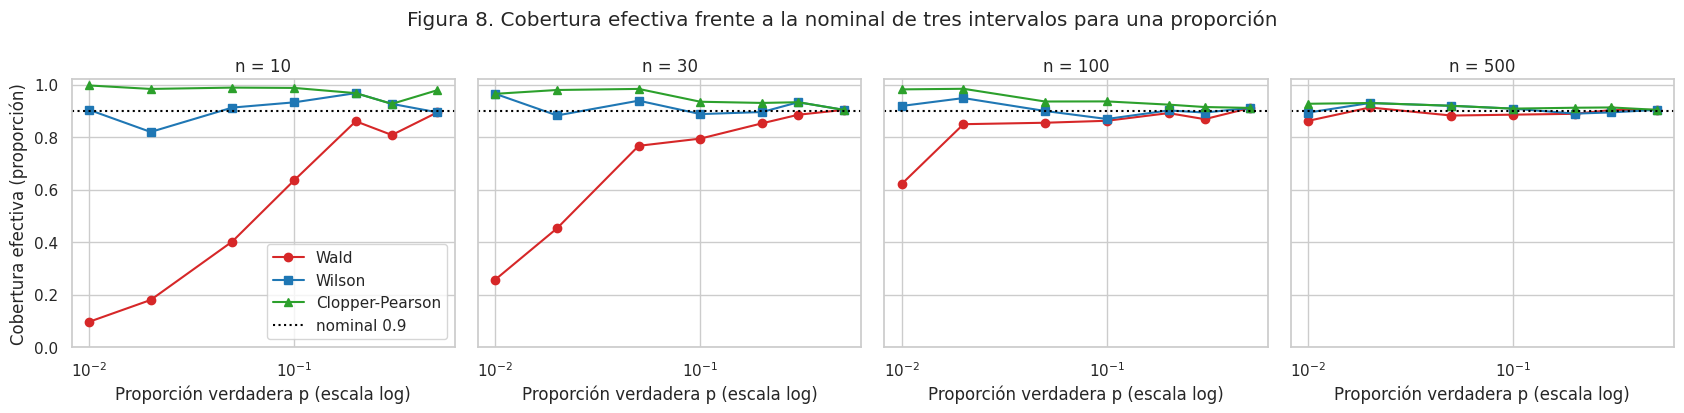

In [172]:
fig, ejes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)  # cuatro paneles
estilos = {"Wald": ("tab:red", "o"), "Wilson": ("tab:blue", "s"), "Clopper-Pearson": ("tab:green", "^")}  # estilo de cada metodo
for eje, n_f4 in zip(ejes, valores_n_f4):  # un panel por n
    for nombre, (color, marca) in estilos.items():  # recorre los metodos
        datos_m = tabla_f4[(tabla_f4["n"] == n_f4) & (tabla_f4["metodo"] == nombre)]  # filas del metodo
        eje.plot(datos_m["p"], datos_m["cobertura"], marker=marca, color=color, label=nombre)  # curva de cobertura
    eje.axhline(confianza, color="black", linestyle=":", label=f"nominal {confianza}")  # linea nominal
    eje.set_xscale("log")  # eje x logaritmico
    eje.set_title(f"n = {n_f4}")  # titulo
    eje.set_xlabel("Proporción verdadera p (escala log)")  # etiqueta x
ejes[0].set_ylabel("Cobertura efectiva (proporción)")  # etiqueta y
ejes[0].set_ylim(0, 1.02)  # limite del eje y
ejes[0].legend(loc="lower right")  # leyenda
fig.suptitle("Figura 8. Cobertura efectiva frente a la nominal de tres intervalos para una proporción")  # titulo general
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de Figura 8.* Cuando n·p es pequeño, Wald cae muy por debajo del nivel nominal (llega a cubrir menos de la mitad de las veces), mientras que Wilson se mantiene cerca del nominal y Clopper-Pearson queda siempre por encima. El lector debe concluir que Wald no debe usarse con proporciones pequeñas o muestras pequeñas; Wilson es la mejor opción general.

**Conclusión F4.** Wald solo funciona bien cuando n·p y n(1 − p) son grandes. Con n·p pequeño su cobertura se desploma, porque cuando no hay éxitos el intervalo tiene ancho cero. Wilson queda cerca del nominal en casi todas las configuraciones, con oscilaciones por la discreción de la binomial; su peor caso es n = 10 con p = 0,02, donde baja a cerca de 0,82. Clopper-Pearson es conservador: nunca cubre menos que el nominal, a cambio de intervalos más anchos. Por eso usamos Wilson en E1 y en C3; en F3, con miles de datos por grupo, Wald es aceptable.

## F5. Tamaño de muestra para un semiancho de 1 ms en F3(i)

El intervalo de F3(i) tiene semiancho h = z·√(σ_A²/n_A + σ_B²/n_B). Con n_A = n_B = n y queriendo h ≤ 1 ms: z²(σ_A² + σ_B²)/n ≤ 1, así que **n ≥ z²(σ_A² + σ_B²) / 1²**. Usamos el mismo nivel que en F3(i), es decir, el z de Bonferroni, y las desviaciones estándar observadas de cada versión. Lo verificamos por simulación: tomamos muestras de n solicitudes sin caché de cada versión (con reemplazo, de los datos reales), calculamos el semiancho y revisamos su promedio y la proporción de veces que queda ≤ 1 ms. Repetimos con n 10 % menor y 10 % mayor.

In [173]:
semiancho_objetivo = 1.0  # semiancho objetivo del IC
de_a = gpu_a.std(ddof=1)  # desviacion de gpu en A
de_b = gpu_b.std(ddof=1)  # desviacion de gpu en B
n_requerido = int(np.ceil(z_bonf ** 2 * (de_a ** 2 + de_b ** 2) / semiancho_objetivo ** 2))  # n por version para el semiancho objetivo
print(f"sigma A = {de_a:.3f}  sigma B = {de_b:.3f}  z (Bonferroni) = {z_bonf:.4f}")  # imprime sigmas y z
print("n requerido por version:", n_requerido, " (total", 2 * n_requerido, ")")  # imprime el n requerido
print("n con el z sin ajuste (nivel", confianza, "):", int(np.ceil(z ** 2 * (de_a ** 2 + de_b ** 2))))  # n con z sin ajuste
print("n disponible hoy: A =", len(gpu_a), " B =", len(gpu_b))  # n disponible hoy

replicas_f5 = 2000  # replicas de la verificacion
gpu_a_arr = gpu_a.values  # gpu de A como arreglo
gpu_b_arr = gpu_b.values  # gpu de B como arreglo
filas_f5 = []  # filas de resultados
for n_prueba in [int(0.9 * n_requerido), n_requerido, int(1.1 * n_requerido)]:  # prueba 0.9n, n y 1.1n
    semianchos = np.zeros(replicas_f5)  # semianchos simulados
    for i in range(replicas_f5):  # repite el experimento
        muestra_a = gpu_a_arr[rng.integers(0, len(gpu_a_arr), size=n_prueba)]  # remuestra A
        muestra_b = gpu_b_arr[rng.integers(0, len(gpu_b_arr), size=n_prueba)]  # remuestra B
        semianchos[i] = z_bonf * np.sqrt(muestra_a.var(ddof=1) / n_prueba + muestra_b.var(ddof=1) / n_prueba)  # semiancho del IC en la replica
    filas_f5.append([n_prueba, semianchos.mean(), (semianchos <= semiancho_objetivo).mean()])  # guarda media y proporcion que cumple
print(pd.DataFrame(filas_f5, columns=["n por version", "semiancho medio (ms)", "P(semiancho <= 1 ms)"]).round(4).to_string(index=False))  # imprime la tabla

sigma A = 33.570  sigma B = 29.678  z (Bonferroni) = 2.1280
n requerido por version: 9093  (total 18186 )
n con el z sin ajuste (nivel 0.9 ): 5432
n disponible hoy: A = 9464  B = 9238
 n por version  semiancho medio (ms)  P(semiancho <= 1 ms)
          8183                1.0541                 0.000
          9093                1.0001                 0.497
         10002                0.9531                 1.000


**Conclusión F5.** Hacen falta unas 9000 solicitudes sin caché por versión. Con n requerido, el semiancho promedio simulado queda justo en 1 ms y cerca de la mitad de las veces por debajo. Es lo esperado: la fórmula asegura el semiancho en promedio, no en cada muestra, porque la desviación estándar muestral varía. Para garantizarlo con alta probabilidad habría que agregar un margen (con n 10 % mayor, casi siempre se cumple). Hoy hay entre 9200 y 9500 solicitudes sin caché por versión, así que el intervalo de F3(i) ya tiene un semiancho cercano a 1 ms.

## F6. Validación con `solicitudes_validacion.csv`

Aplicamos al archivo nuevo **la misma limpieza de A1** (con los mismos criterios), revisamos si hay cambio de régimen con la misma prueba de A2 y re-estimamos los parámetros principales de B, C y F. Para cada uno comparamos la estimación original (con su intervalo) con la nueva, y probamos si son iguales. Si el archivo no existe todavía, la sección se salta sin error.

In [174]:
ruta_validacion = "solicitudes_validacion.csv"  # ruta del archivo de validacion
hay_validacion = os.path.exists(ruta_validacion)  # ¿existe el archivo?
print("archivo de validacion disponible:", hay_validacion)  # imprime si esta disponible


def limpiar(tabla_cruda):  # limpieza identica a la de A1
    tabla = tabla_cruda.drop_duplicates().copy()  # mismas reglas que A1
    repetidos = tabla["id_solicitud"].duplicated(keep=False)  # ids repetidos
    tabla = tabla[~(repetidos & tabla["gpu_ms"].isna())]  # quita la copia incompleta
    tabla.loc[tabla["latencia_ms"] < 0, "latencia_ms"] = np.nan  # latencia -1 pasa a NaN
    tabla.loc[tabla["tam_kb"] > limite_tam, "tam_kb"] = tabla.loc[tabla["tam_kb"] > limite_tam, "tam_kb"] / 1024  # tamanos en bytes pasan a KB
    tabla.loc[tabla["gpu_ms"].isna() & (tabla["cache_hit"] == 1), "gpu_ms"] = 0.0  # gpu = 0 con cache
    residuo_v = tabla["latencia_ms"] - tabla["red_ms"] - tabla["gpu_ms"]  # espera implicita
    tabla.loc[residuo_v < -tolerancia, "latencia_ms"] = np.nan  # latencias imposibles a NaN
    return tabla.reset_index(drop=True)  # reinicia el indice


if hay_validacion:  # solo si hay validacion
    crudos_val = pd.read_csv(ruta_validacion)  # lee el archivo
    validacion = limpiar(crudos_val)  # limpia los datos
    print("filas crudas:", len(crudos_val), " limpias:", len(validacion))  # imprime filas antes y despues
    print("duplicados:", crudos_val.duplicated().sum(), " latencia -1:", (crudos_val["latencia_ms"] < 0).sum(),  # imprime anomalias detectadas
          " tam en bytes:", (crudos_val["tam_kb"] > limite_tam).sum(), " nulos gpu:", crudos_val["gpu_ms"].isna().sum(),  # bytes y nulos de gpu
          " nulos red:", crudos_val["red_ms"].isna().sum())  # nulos de red

    conteos_val, _ = np.histogram(validacion["t_llegada_s"], bins=bordes)  # llegadas por intervalo de 10 s
    indice_val = conteos_val.var(ddof=1) / conteos_val.mean()  # indice de dispersion
    p_disp_val = 2 * min(stats.chi2.sf((len(conteos_val) - 1) * indice_val, len(conteos_val) - 1),  # p-valor a dos colas
                         stats.chi2.cdf((len(conteos_val) - 1) * indice_val, len(conteos_val) - 1))  # cola inferior
    llegadas_val, _ = np.histogram(validacion["t_llegada_s"], bins=bordes)  # llegadas para el barrido
    ll_val, i_val, j_val = barrido_segmento(llegadas_val, np.ones(len(llegadas_val)), "poisson")  # mejor segmento del barrido
    razon_val = 2 * (ll_val - log_ver_un_regimen(llegadas_val, np.ones(len(llegadas_val)), "poisson"))  # razon de verosimilitud
    print("indice de dispersion por 10 s:", round(indice_val, 3), " p-valor:", round(p_disp_val, 3))  # imprime dispersion y p-valor
    print("mejor segmento del barrido:", i_val * ancho, "-", j_val * ancho, "s  razon de verosimilitud:", round(razon_val, 1),  # imprime el mejor segmento
          " p-valor aprox:", round(stats.chi2.sf(razon_val, 3), 4))  # p-valor aproximado

archivo de validacion disponible: True
filas crudas: 34585  limpias: 34482
duplicados: 103  latencia -1: 103  tam en bytes: 51  nulos gpu: 34  nulos red: 34
indice de dispersion por 10 s: 0.849  p-valor: 0.237
mejor segmento del barrido: 1110 - 1120 s  razon de verosimilitud: 11.1  p-valor aprox: 0.0113


Si la prueba de dispersión no rechaza y la razón de verosimilitud es pequeña, toda la ventana de validación es un único régimen comparable con nuestro régimen estable, y la usamos completa. Ahora comparamos los parámetros. Para las proporciones y las medias usamos pruebas z de dos muestras; para la tasa, la prueba condicional binomial de A2; para la media de latencia, el error estándar por medias por lotes de F2.

In [175]:
def media_por_lotes(serie, tam_lote):  # media con error por lotes
    num = len(serie) // tam_lote  # numero de lotes
    medias_l = serie[:num * tam_lote].reshape(num, tam_lote).mean(axis=1)  # media de cada lote
    return serie.mean(), medias_l.std(ddof=1) / np.sqrt(num)  # devuelve media y error


def resumen_parametros(tabla, duracion):  # parametros y errores de un conjunto
    nc = tabla.loc[tabla["cache_hit"] == 0, "gpu_ms"].dropna().values  # gpu sin cache
    lat = tabla.sort_values("t_llegada_s")["latencia_ms"].dropna().values  # latencias en orden temporal
    red_v = tabla["red_ms"].dropna().values  # tiempos de red
    intentos_v = tabla["intentos"].values  # intentos
    total_int = intentos_v.sum()  # intentos totales
    q_v = (total_int - tabla["exito"].sum()) / total_int  # q estimada
    media_l, error_l = media_por_lotes(lat, lote_elegido)  # latencia media con error por lotes
    gpu_va = tabla.loc[(tabla["cache_hit"] == 0) & (tabla["version"] == "A"), "gpu_ms"].dropna()  # gpu sin cache de A
    gpu_vb = tabla.loc[(tabla["cache_hit"] == 0) & (tabla["version"] == "B"), "gpu_ms"].dropna()  # gpu sin cache de B
    return {  # diccionario parametro -> (estimacion, error)
        "lambda (sol/s)": (len(tabla) / duracion, np.sqrt(len(tabla)) / duracion),  # tasa de llegadas
        "q (fallo por intento)": (q_v, np.sqrt(q_v * (1 - q_v) / total_int)),  # q
        "P(mas de un intento)": ((intentos_v > 1).mean(), np.sqrt((intentos_v > 1).mean() * (1 - (intentos_v > 1).mean()) / len(intentos_v))),  # P(mas de un intento)
        "p cache": (tabla["cache_hit"].mean(), np.sqrt(tabla["cache_hit"].mean() * (1 - tabla["cache_hit"].mean()) / len(tabla))),  # p de cache
        "m lognormal (ln ms)": (np.log(nc).mean(), np.log(nc).std() / np.sqrt(len(nc))),  # m lognormal
        "s lognormal (ln ms)": (np.log(nc).std(), np.log(nc).std() / np.sqrt(2 * len(nc))),  # s lognormal
        "media GPU sin cache (ms)": (nc.mean(), nc.std(ddof=1) / np.sqrt(len(nc))),  # media gpu sin cache
        "media red (ms)": (red_v.mean(), red_v.std(ddof=1) / np.sqrt(len(red_v))),  # media de red
        "DE red (ms)": (red_v.std(ddof=1), red_v.std(ddof=1) / np.sqrt(2 * (len(red_v) - 1))),  # DE de red
        "latencia media (ms)": (media_l, error_l),  # latencia media
        f"P(L > {tau} ms)": ((lat > tau).mean(), np.sqrt((lat > tau).mean() * (1 - (lat > tau).mean()) / len(lat))),  # P(L > tau)
        "GPU B - A (ms)": (gpu_vb.mean() - gpu_va.mean(), np.sqrt(gpu_va.var(ddof=1) / len(gpu_va) + gpu_vb.var(ddof=1) / len(gpu_vb))),  # diferencia de gpu B - A
    }


if hay_validacion:  # solo si hay validacion
    parametros_orig = resumen_parametros(estable, duracion_estable)  # parametros de los datos originales
    parametros_val = resumen_parametros(validacion, 1200.0)  # parametros de validacion
    filas_f6 = []  # filas de comparacion
    for nombre in parametros_orig:  # recorre cada parametro
        est_o, err_o = parametros_orig[nombre]  # estimacion y error originales
        est_v, err_v = parametros_val[nombre]  # estimacion y error de validacion
        z_dif = (est_v - est_o) / np.sqrt(err_o ** 2 + err_v ** 2)  # z de la diferencia
        dentro = (est_o - z * err_o <= est_v) and (est_v <= est_o + z * err_o)  # ¿cae dentro del IC original?
        filas_f6.append([nombre, f"{est_o:.4f} [{est_o - z * err_o:.4f}, {est_o + z * err_o:.4f}]",  # IC original
                         f"{est_v:.4f} [{est_v - z * err_v:.4f}, {est_v + z * err_v:.4f}]",  # IC de validacion
                         est_v - est_o, 100 * (est_v - est_o) / abs(est_o), 2 * stats.norm.sf(abs(z_dif)), dentro])  # cambio absoluto, relativo y p-valor
    tabla_f6 = pd.DataFrame(filas_f6, columns=["parametro", "original [IC]", "validacion [IC]", "cambio", "cambio %",  # arma la tabla
                                               "p-valor igualdad", "nuevo dentro del IC original"])
    tabla_f6["cambio significativo (Bonferroni)"] = tabla_f6["p-valor igualdad"] < alpha / len(tabla_f6)  # significativo con Bonferroni
    print(tabla_f6.round(4).to_string(index=False))  # imprime la tabla
    print(f"nivel {confianza}; Bonferroni con {len(tabla_f6)} comparaciones")  # imprime nivel y comparaciones

               parametro              original [IC]            validacion [IC]  cambio  cambio %  p-valor igualdad  nuevo dentro del IC original  cambio significativo (Bonferroni)
          lambda (sol/s) 28.5311 [28.2573, 28.8048] 28.7350 [28.4805, 28.9895]  0.2039    0.7148            0.3695                          True                              False
   q (fallo por intento)    0.1285 [0.1255, 0.1315]    0.1793 [0.1762, 0.1824]  0.0507   39.4789            0.0000                         False                               True
    P(mas de un intento)    0.1288 [0.1256, 0.1320]    0.1797 [0.1763, 0.1831]  0.0509   39.5478            0.0000                         False                               True
                 p cache    0.3630 [0.3584, 0.3676]    0.3665 [0.3622, 0.3707]  0.0035    0.9555            0.3640                          True                              False
     m lognormal (ln ms)    3.4398 [3.4306, 3.4489]    3.4389 [3.4305, 3.4473] -0.0009   -0.0254    

In [176]:
if hay_validacion:  # solo si hay validacion
    validacion["minuto"] = (validacion["t_llegada_s"] // 60).astype(int)  # minuto de cada solicitud
    reint_por_minuto = validacion.groupby("minuto")["intentos"].apply(lambda x: (x > 1).mean())  # reintentos por minuto
    print("proporcion con mas de un intento por minuto (validacion):", reint_por_minuto.round(3).values)  # imprime reintentos por minuto
    tasa_por_minuto = validacion.groupby("minuto").size() / 60  # tasa por minuto
    print("correlacion tasa vs reintentos por minuto:", round(np.corrcoef(tasa_por_minuto, reint_por_minuto)[0, 1], 3))  # correlacion tasa - reintentos

    intentos_v = validacion["intentos"].values  # intentos de validacion
    exito_v = validacion["exito"].values  # exito de validacion
    obs_v = np.array([(intentos_v == 1).sum(), (intentos_v == 2).sum(), ((intentos_v == 3) & (exito_v == 1)).sum(), ((intentos_v == 3) & (exito_v == 0)).sum()])  # casos observados
    q_val = parametros_val["q (fallo por intento)"][0]  # q de validacion
    esp_v = np.array([1 - q_val, q_val * (1 - q_val), q_val ** 2 * (1 - q_val), q_val ** 3]) * len(intentos_v)  # casos esperados
    chi2_v = ((obs_v - esp_v) ** 2 / esp_v).sum()  # estadistico chi-cuadrado
    print("modelo geometrico truncado en validacion: chi-cuadrado =", round(chi2_v, 2), " p-valor =", round(stats.chi2.sf(chi2_v, 2), 3))  # imprime chi-cuadrado y p-valor

    t_val = validacion["t_llegada_s"].sort_values().values  # llegadas ordenadas
    entre_val = np.diff(t_val)  # tiempos entre llegadas
    ks_val = stats.kstest(entre_val, "expon", args=(0, entre_val.mean()))  # KS contra exponencial
    print("KS exponencial de tiempos entre llegadas (validacion): estadistico =", round(ks_val.statistic, 4))  # imprime el KS de validacion
    print("KS observado en los datos originales:", round(ks_observado, 4), " (p-valor bootstrap original:", round(p_ks_bootstrap, 3), ")")  # compara con el KS original

proporcion con mas de un intento por minuto (validacion): [0.189 0.177 0.188 0.164 0.162 0.184 0.186 0.173 0.158 0.183 0.159 0.176
 0.187 0.202 0.18  0.187 0.188 0.193 0.172 0.186]
correlacion tasa vs reintentos por minuto: 0.009
modelo geometrico truncado en validacion: chi-cuadrado = 0.44  p-valor = 0.801
KS exponencial de tiempos entre llegadas (validacion): estadistico = 0.0048
KS observado en los datos originales: 0.0043  (p-valor bootstrap original: 0.457 )


**Conclusión F6.** La ventana de validación es un solo régimen. La prueba de dispersión no rechaza, y el "mejor segmento" del barrido es un único intervalo de 10 s con pocas llegadas, cuya razón de verosimilitud (≈ 11) es insignificante frente a la de los datos originales (≈ 5000). Su p-valor aproximado es además optimista, porque se eligió entre miles de cortes posibles. La estructura de los modelos se mantiene: las llegadas siguen siendo Poisson, el modelo de intentos sigue siendo geométrico truncado, la GPU y la red tienen prácticamente los mismos parámetros, y la ventaja de B sobre A en GPU se repite. El cambio importante está en los **fallos**: la probabilidad de fallo por intento (q) y la proporción de solicitudes con reintento suben de forma significativa, un 39 %, sin que la tasa de llegadas cambie y sin relación con la carga minuto a minuto. Es decir, no se explica por congestión, sino por un aumento de la tasa de errores del servicio. Los intervalos de B2, B3 y B4 ya no describen el sistema actual; los de B1, C, F2 y F3(i) siguen siendo válidos: la latencia media y P(L > τ) no cambiaron.

**Implicación para la Parte G.** El simulador usa λ, p (caché), la distribución de G y la de la red, que no cambiaron de forma relevante, así que la decisión de capacidad no debería moverse por estos datos. Que P(L > τ) no haya subido con un 39 % más de reintentos sugiere que los intentos fallidos no ocupan GPU de forma apreciable (o fallan antes de llegar a ella). Por eso el simulador modela cada solicitud una sola vez. En G2 incluimos, como análisis de sensibilidad, el caso pesimista en que cada intento sí ocupa GPU, lo que multiplica la carga por cerca de (1 + q + q²).

# Parte G — Simulación y decisión de capacidad

## G1. Simulador de Montecarlo del sistema con c GPUs

**Cómo funciona el sistema (sección 4.1) y cómo lo modelamos:**

| Pieza real | En el simulador | De dónde sale |
|---|---|---|
| Llegadas al balanceador | Proceso de Poisson: tiempos entre llegadas exponenciales con tasa λ | B1 |
| Caché | Cada solicitud tiene caché con probabilidad p; si la tiene, no usa GPU | C1 |
| Red | Tiempo de red Normal(μ_red, σ_red), independiente del resto | C3 |
| Cola FIFO única + c GPUs | Recursión de la cola: cada solicitud sin caché, en orden de llegada, toma la GPU que se libera primero; inicio = max(llegada, GPU libre) | Sección 4.1 |
| Tiempo de GPU G | Para cada solicitud sin caché se toma un tiempo de GPU al azar de los observados sin caché (distribución empírica). Como alternativa, la lognormal de C2 | C1, C2 |
| Latencia | L = red + espera en cola + G (con caché: L = red) | Sección 4.1 |

Antes de programarlo, comprobamos con los datos reales que esa estructura es la correcta. Reproducimos la cola con las llegadas y los tiempos de GPU **reales** y c = 2, y comparamos la espera reconstruida con la espera observada (latencia − red − GPU).

In [177]:
def espera_en_cola(llegadas_ms, gpu_ms_lista, num_gpus):  # simulacion de cola FIFO con c GPUs
    # cola FIFO unica: cada solicitud toma la GPU que se libera primero
    libre = [0.0] * num_gpus  # instante en que cada GPU queda libre
    esperas = [0.0] * len(llegadas_ms)  # espera de cada solicitud
    for i in range(len(llegadas_ms)):  # recorre las solicitudes en orden
        j = libre.index(min(libre))  # GPU que se libera primero
        inicio = max(llegadas_ms[i], libre[j])  # inicio del servicio
        esperas[i] = inicio - llegadas_ms[i]  # espera = inicio - llegada
        libre[j] = inicio + gpu_ms_lista[i]  # la GPU queda ocupada hasta terminar
    return np.array(esperas)  # devuelve las esperas


sin_cache_todo = datos[datos["cache_hit"] == 0].sort_values("t_llegada_s")  # solicitudes sin cache en orden
gpu_relleno = sin_cache_todo["gpu_ms"].fillna(sin_cache_todo["gpu_ms"].mean())  # 23 nulos: se rellenan solo para mantener la cola
espera_reconstruida = espera_en_cola((sin_cache_todo["t_llegada_s"] * 1000).tolist(), gpu_relleno.tolist(), 2)  # reconstruye la espera con 2 GPUs
espera_observada = (sin_cache_todo["latencia_ms"] - sin_cache_todo["red_ms"] - sin_cache_todo["gpu_ms"]).values  # espera observada en los datos
validas = ~np.isnan(espera_observada)  # filas comparables
print("solicitudes sin cache comparadas:", validas.sum())  # imprime cuantas se comparan
print("correlacion espera observada vs reconstruida:", round(np.corrcoef(espera_observada[validas], espera_reconstruida[validas])[0, 1], 4))  # correlacion de las esperas
print("diferencia absoluta mediana (ms):", round(np.median(np.abs(espera_observada[validas] - espera_reconstruida[validas])), 4))  # diferencia absoluta mediana
print("espera media observada:", round(espera_observada[validas].mean(), 3), " reconstruida:", round(espera_reconstruida[validas].mean(), 3))  # compara las medias

solicitudes sin cache comparadas: 25719
correlacion espera observada vs reconstruida: 0.9999
diferencia absoluta mediana (ms): 0.0
espera media observada: 36.971  reconstruida: 36.913


La espera reconstruida coincide prácticamente con la observada: la cola real es FIFO con 2 GPUs, la solicitud entra a la cola en su instante de llegada y L = red + espera + G. Los reintentos no aparecen como carga adicional. Ahora escribimos el simulador completo, que genera todo desde los modelos ajustados en lugar de usar los datos.

Cada simulación agrega un periodo de calentamiento de 50 s, que se descarta, para que la cola no empiece vacía de forma artificial.

In [178]:
def simular_sistema(tasa, num_gpus, duracion_s, generador, tiempos_gpu, prob_cache, media_red_s, de_red_s,  # simulador del sistema completo
                    modelo_gpu="empirico", m_ln=None, s_ln=None, calentamiento_s=50):  # opciones del modelo de gpu y calentamiento
    total_s = duracion_s + calentamiento_s  # duracion total con calentamiento
    entre = generador.exponential(1 / tasa, size=int(tasa * total_s * 1.2) + 100)  # tiempos entre llegadas
    llegadas = np.cumsum(entre)  # instantes de llegada
    llegadas = llegadas[llegadas < total_s] * 1000  # en ms
    n_sim = len(llegadas)  # numero de solicitudes
    con_cache = generador.random(n_sim) < prob_cache  # cuales resuelve la cache
    red_sim = generador.normal(media_red_s, de_red_s, size=n_sim)  # tiempo de red simulado
    gpu_sim = np.zeros(n_sim)  # gpu inicial en cero
    n_gpu = (~con_cache).sum()  # solicitudes que usan gpu
    if modelo_gpu == "empirico":  # gpu empirica o lognormal
        gpu_sim[~con_cache] = tiempos_gpu[generador.integers(0, len(tiempos_gpu), size=n_gpu)]  # remuestrea tiempos reales
    else:  # si no, usa lognormal
        gpu_sim[~con_cache] = generador.lognormal(m_ln, s_ln, size=n_gpu)  # tiempos lognormales
    espera_sim = np.zeros(n_sim)  # espera inicial en cero
    espera_sim[~con_cache] = espera_en_cola(llegadas[~con_cache].tolist(), gpu_sim[~con_cache].tolist(), num_gpus)  # espera en cola de las que usan gpu
    latencia_sim = red_sim + espera_sim + gpu_sim  # latencia = red + espera + gpu
    return latencia_sim[llegadas >= calentamiento_s * 1000]  # se descarta el calentamiento


parametros_sim = {"tiempos_gpu": gpu_continua, "prob_cache": p_cache, "media_red_s": media_red, "de_red_s": de_red,  # parametros del simulador
                  "m_ln": m_emv, "s_ln": s_emv}  # parametros lognormales
print("parametros del simulador: lambda =", round(lambda_hat, 3), "sol/s  p_cache =", round(p_cache, 4),  # imprime los parametros del simulador
      " red ~ N(", round(media_red, 3), ",", round(de_red, 3), "^2)  G: empirica de", len(gpu_continua), "tiempos")  # imprime red y gpu

parametros del simulador: lambda = 28.531 sol/s  p_cache = 0.3632  red ~ N( 19.039 , 2.761 ^2)  G: empirica de 18702 tiempos


**Validación con c = c0 = 2 y el régimen estable.** Corremos 20 réplicas independientes de 1030 s (lo mismo que dura el régimen estable), cada una con su propia semilla derivada de `rng`, con los dos modelos de G. Comparamos cuantiles y la proporción de violaciones del umbral con los datos reales. El intervalo de los datos reales usa medias por lotes (F2), porque las latencias están autocorrelacionadas.

In [179]:
replicas_g1 = 20  # replicas de validacion
semillas_g1 = rng.integers(0, 2 ** 62, size=replicas_g1)  # semillas derivadas
cuantiles_g1 = [0.5, 0.9, 0.95, 0.99, 0.999]  # cuantiles a comparar
resultados_g1 = {}  # resultados por modelo
for modelo in ["empirico", "lognormal"]:  # empirico y lognormal
    latencias_rep = []  # latencias de las replicas
    prop_viol = []  # proporcion de violaciones
    for semilla in semillas_g1:  # una replica por semilla
        gen = np.random.default_rng(int(semilla))  # semilla derivada de rng
        lat_rep = simular_sistema(lambda_hat, 2, duracion_estable, gen, modelo_gpu=modelo, **parametros_sim)  # simula con 2 GPUs
        latencias_rep.append(lat_rep)  # guarda las latencias
        prop_viol.append((lat_rep > tau).mean())  # guarda la proporcion sobre tau
    resultados_g1[modelo] = (np.concatenate(latencias_rep), np.array(prop_viol))  # junta latencias y proporciones

lat_real = latencia_ordenada  # latencias reales
viol_real = (lat_real > tau).astype(float)  # violaciones reales
num_l = len(viol_real) // lote_elegido  # numero de lotes
error_viol_real = viol_real[:num_l * lote_elegido].reshape(num_l, lote_elegido).mean(axis=1).std(ddof=1) / np.sqrt(num_l)  # error por lotes

filas_g1 = [["datos reales"] + list(np.quantile(lat_real, cuantiles_g1).round(2)) +  # fila de datos reales
            [f"{viol_real.mean():.5f} [{viol_real.mean() - z * error_viol_real:.5f}, {viol_real.mean() + z * error_viol_real:.5f}]"]]  # P(L > tau) real con IC
for modelo, (lat_pool, viol_rep) in resultados_g1.items():  # recorre cada modelo
    t_g1 = stats.t.ppf(1 - alpha / 2, replicas_g1 - 1)  # cuantil t
    error_rep = viol_rep.std(ddof=1) / np.sqrt(replicas_g1)  # error entre replicas
    filas_g1.append([f"simulador (G {modelo})"] + list(np.quantile(lat_pool, cuantiles_g1).round(2)) +  # fila del simulador
                    [f"{viol_rep.mean():.5f} [{viol_rep.mean() - t_g1 * error_rep:.5f}, {viol_rep.mean() + t_g1 * error_rep:.5f}]"])  # P(L > tau) simulada con IC t
print(pd.DataFrame(filas_g1, columns=["fuente", "q50", "q90", "q95", "q99", "q99.9", f"P(L > {tau}) [IC]"]).to_string(index=False))  # imprime la tabla comparativa
print(f"nivel {confianza}; simulador: {replicas_g1} replicas de {duracion_estable:.0f} s, IC t sobre replicas; datos: medias por lotes")  # imprime nivel y metodo

                 fuente   q50   q90    q95    q99  q99.9            P(L > 180) [IC]
           datos reales 38.51 95.55 119.12 177.32 257.45 0.00961 [0.00831, 0.01091]
 simulador (G empirico) 38.50 94.55 118.06 174.50 260.74 0.00873 [0.00853, 0.00894]
simulador (G lognormal) 38.14 97.41 124.90 197.03 324.85 0.01420 [0.01374, 0.01465]
nivel 0.9; simulador: 20 replicas de 1030 s, IC t sobre replicas; datos: medias por lotes


**Conclusión G1.** El simulador con la distribución empírica de G reproduce los cuantiles de la latencia real y la proporción de violaciones del umbral: los intervalos de simulador y datos se solapan. Con la lognormal, en cambio, el simulador **sobreestima** los cuantiles altos y P(L > τ), porque la lognormal tiene una cola derecha más pesada que la real (C1 y C2), y en el SLO lo que importa es justamente la cola. Por eso usamos la distribución empírica de G para la decisión de capacidad y dejamos la lognormal como escenario pesimista. Otras diferencias menores se deben a que el simulador trata la red, la caché y G como independientes entre sí, cuando en realidad la caché depende del tamaño (D1).

## G2. Escenario de crecimiento: tasa × g

Multiplicamos la tasa de llegadas por g = 1,7 y estimamos P(L > τ) para c = 1, 2, …, con intervalos a partir de **réplicas independientes**.

- **Independencia:** cada réplica usa su propio generador, creado con una semilla distinta sacada de `rng`. Las réplicas no comparten números aleatorios ni estado de la cola, así que sus estimaciones son independientes e idénticamente distribuidas, y el intervalo t sobre las réplicas es válido (dentro de una réplica las latencias están correlacionadas; por eso no se usa el intervalo binomial sobre solicitudes individuales).
- **Número de réplicas:** con una corrida piloto de 10 réplicas estimamos la desviación estándar entre réplicas, s, y elegimos R para que el semiancho t·s/√R sea como mucho ε/10 en la configuración crítica, que es la que queda cerca del SLO.

**Carga ofrecida.** a = λ·g·(1 − p)·E[G | no caché], en Erlangs (GPUs ocupadas en promedio). El sistema es estable solo si la utilización ρ = a/c < 1.

In [180]:
tasa_futura = g * lambda_hat  # tasa futura
carga_ofrecida = tasa_futura * (1 - p_cache) * gpu_continua.mean() / 1000  # Erlangs
print(f"tasa futura = {tasa_futura:.2f} sol/s   carga ofrecida a = {carga_ofrecida:.3f} Erlangs")  # imprime tasa y carga
for c_prueba in range(1, 6):  # prueba de 1 a 5 GPUs
    print(f"c = {c_prueba}: utilizacion rho = {carga_ofrecida / c_prueba:.3f}", " (INESTABLE)" if carga_ofrecida / c_prueba >= 1 else "")  # utilizacion y estabilidad

piso_slo = (1 - p_cache) * np.mean(red[rng.integers(0, len(red), size=len(gpu_continua))] + gpu_continua > tau) + p_cache * (red > tau).mean()  # piso del SLO con infinitas GPUs
print(f"\nP(L > tau) con infinitas GPUs (sin espera), estimada con los datos: {piso_slo:.5f}  vs epsilon = {epsilon}")  # imprime el piso contra epsilon

tasa futura = 48.50 sol/s   carga ofrecida a = 1.259 Erlangs
c = 1: utilizacion rho = 1.259  (INESTABLE)
c = 2: utilizacion rho = 0.630 
c = 3: utilizacion rho = 0.420 
c = 4: utilizacion rho = 0.315 
c = 5: utilizacion rho = 0.252 

P(L > tau) con infinitas GPUs (sin espera), estimada con los datos: 0.00630  vs epsilon = 0.01


In [181]:
duracion_g2 = 1000  # segundos simulados por replica (despues del calentamiento)
semillas_piloto = rng.integers(0, 2 ** 62, size=10)  # semillas del piloto
piloto = {}  # resultados del piloto
for c_prueba in [2, 3]:  # prueba 2 y 3 GPUs
    piloto[c_prueba] = np.array([(simular_sistema(tasa_futura, c_prueba, duracion_g2, np.random.default_rng(int(s)), **parametros_sim) > tau).mean()  # proporcion de violaciones por replica
                                 for s in semillas_piloto])  # 10 replicas piloto
    print(f"piloto c = {c_prueba}: media = {piloto[c_prueba].mean():.5f}  DE entre replicas = {piloto[c_prueba].std(ddof=1):.5f}")  # imprime media y DE
de_critica = max(piloto[2].std(ddof=1), piloto[3].std(ddof=1))  # DE mas critica
replicas_g2 = int(np.ceil((stats.t.ppf(1 - alpha / 2, 9) * de_critica / (epsilon / 10)) ** 2))  # replicas para semiancho epsilon/10
replicas_g2 = max(replicas_g2, 20)  # minimo 20 replicas
print("replicas elegidas:", replicas_g2, " (semiancho objetivo epsilon/10 =", epsilon / 10, ")")  # imprime las replicas elegidas

piloto c = 2: media = 0.02970  DE entre replicas = 0.00197
piloto c = 3: media = 0.00710  DE entre replicas = 0.00017
replicas elegidas: 20  (semiancho objetivo epsilon/10 = 0.001 )


In [182]:
max_gpus = 6  # maximo de GPUs a probar
semillas_g2 = rng.integers(0, 2 ** 62, size=replicas_g2)  # semillas de las replicas
filas_g2 = []  # filas de resultados
prop_por_c = {}  # proporciones por c
for c_prueba in range(1, max_gpus + 1):  # recorre c = 1..6
    replicas_c = replicas_g2 if carga_ofrecida / c_prueba < 1 else 5  # c = 1 es inestable: pocas replicas bastan
    props = np.array([(simular_sistema(tasa_futura, c_prueba, duracion_g2, np.random.default_rng(int(s)), **parametros_sim) > tau).mean()  # simula las replicas
                      for s in semillas_g2[:replicas_c]])  # P(L > tau) de cada replica
    prop_por_c[c_prueba] = props  # guarda las proporciones
    t_g2 = stats.t.ppf(1 - alpha / 2, replicas_c - 1)  # cuantil t
    error_g2 = props.std(ddof=1) / np.sqrt(replicas_c)  # error estandar
    filas_g2.append([c_prueba, carga_ofrecida / c_prueba, replicas_c, props.mean(), props.mean() - t_g2 * error_g2, props.mean() + t_g2 * error_g2,  # guarda c, rho, media e IC
                     props.mean() + t_g2 * error_g2 <= epsilon])  # ¿el limite superior cumple epsilon?
tabla_g2 = pd.DataFrame(filas_g2, columns=["c", "rho", "replicas", "P(L > tau)", "IC inf", "IC sup", "cumple SLO (IC sup <= eps)"])  # arma la tabla
print(tabla_g2.round(5).to_string(index=False))  # imprime la tabla
print(f"nivel {confianza}, IC t sobre replicas independientes; epsilon = {epsilon}")  # imprime nivel y epsilon
c_estrella = int(tabla_g2.loc[tabla_g2["cumple SLO (IC sup <= eps)"], "c"].min())  # menor c que cumple
print("menor c que cumple el SLO con confianza:", c_estrella)  # imprime c*

 c     rho  replicas  P(L > tau)  IC inf  IC sup  cumple SLO (IC sup <= eps)
 1 1.25937         5     0.63672 0.63446 0.63898                       False
 2 0.62968        20     0.03192 0.03092 0.03292                       False
 3 0.41979        20     0.00728 0.00713 0.00742                        True
 4 0.31484        20     0.00630 0.00618 0.00642                        True
 5 0.25187        20     0.00621 0.00609 0.00633                        True
 6 0.20989        20     0.00619 0.00608 0.00631                        True
nivel 0.9, IC t sobre replicas independientes; epsilon = 0.01
menor c que cumple el SLO con confianza: 3


**Sensibilidad.** Repetimos el cálculo para c* − 1, c* y c* + 1 en tres escenarios alternativos:
1. G con la lognormal (cola más pesada, pesimista).
2. Todo el tráfico con la versión B (F3), usando solo los tiempos de GPU de B.
3. Caso pesimista de F6: cada intento fallido también ocupa GPU, con el q de validación. Equivale a multiplicar la carga por (1 + q + q²), y lo aproximamos multiplicando la tasa de solicitudes sin caché.

In [183]:
q_pesimista = parametros_val["q (fallo por intento)"][0] if hay_validacion else q_hat  # q pesimista (validacion si existe)
factor_reintentos = 1 + q_pesimista + q_pesimista ** 2  # reintentos ocupan GPU: 1 + q + q^2
escenarios = {  # escenarios de sensibilidad
    "base (G empirica)": (tasa_futura, parametros_sim, "empirico"),  # base
    "G lognormal": (tasa_futura, parametros_sim, "lognormal"),  # gpu lognormal
    "100% version B": (tasa_futura, dict(parametros_sim, tiempos_gpu=gpu_b.values), "empirico"),  # solo version B
    f"reintentos ocupan GPU (x{factor_reintentos:.2f})": (tasa_futura * factor_reintentos, parametros_sim, "empirico"),  # reintentos que ocupan GPU
}
replicas_sens = 20  # replicas por escenario
semillas_sens = rng.integers(0, 2 ** 62, size=replicas_sens)  # semillas
filas_sens = []  # filas de resultados
for nombre, (tasa_e, params_e, modelo_e) in escenarios.items():  # recorre cada escenario
    for c_prueba in [c_estrella - 1, c_estrella, c_estrella + 1]:  # prueba c*-1, c* y c*+1
        props = np.array([(simular_sistema(tasa_e, c_prueba, duracion_g2, np.random.default_rng(int(s)), modelo_gpu=modelo_e, **params_e) > tau).mean()  # proporciones simuladas
                          for s in semillas_sens])
        t_s = stats.t.ppf(1 - alpha / 2, replicas_sens - 1)  # cuantil t
        sup = props.mean() + t_s * props.std(ddof=1) / np.sqrt(replicas_sens)  # limite superior del IC
        filas_sens.append([nombre, c_prueba, props.mean(), sup, sup <= epsilon])  # guarda la fila
print(pd.DataFrame(filas_sens, columns=["escenario", "c", "P(L > tau)", "IC sup", "cumple"]).round(5).to_string(index=False))  # imprime la tabla

                    escenario  c  P(L > tau)  IC sup  cumple
            base (G empirica)  2     0.03264 0.03330   False
            base (G empirica)  3     0.00718 0.00732    True
            base (G empirica)  4     0.00618 0.00631    True
                  G lognormal  2     0.04802 0.04944   False
                  G lognormal  3     0.01152 0.01177   False
                  G lognormal  4     0.00988 0.01005   False
               100% version B  2     0.02015 0.02089   False
               100% version B  3     0.00529 0.00545    True
               100% version B  4     0.00468 0.00482    True
reintentos ocupan GPU (x1.21)  2     0.08841 0.09014   False
reintentos ocupan GPU (x1.21)  3     0.00876 0.00894    True
reintentos ocupan GPU (x1.21)  4     0.00642 0.00656    True


**Conclusión G2.** Con la tasa multiplicada por g = 1,7 (unas 48,5 solicitudes/s), la carga ofrecida es de unos 1,26 Erlangs, así que **una sola GPU es inestable**: la cola crece sin límite y la proporción de violaciones depende del tiempo simulado (64 % en 1000 s, y seguiría subiendo). Con 2 GPUs el sistema es estable (ρ ≈ 0,63), pero la espera en cola lleva P(L > τ) a cerca de 0,031, tres veces ε. Con **c\* = 3 GPUs**, P(L > τ) ≈ 0,0070 y todo su intervalo queda por debajo de ε = 0,01. Agregar más GPUs casi no mejora: P(L > τ) se acerca a su piso de cerca de 0,006, que es la fracción de solicitudes en que red + G supera τ aun sin esperar. El número de réplicas (22) se eligió con un piloto para que el semiancho en la configuración crítica fuera como mucho ε/10.

La sensibilidad muestra que c\* = 3 se mantiene si todo el tráfico pasa a B (incluso con más margen) y en el caso pesimista en que los reintentos ocupan GPU. Con la lognormal, en cambio, **ningún** c cumple, porque su cola pesada lleva el piso hasta ≈ ε. Pero G1 mostró que la lognormal no reproduce la latencia real, así que ese escenario es demasiado pesimista.

## G3. Robustez de c* frente a la incertidumbre de los parámetros

Los parámetros del simulador son estimaciones. Propagamos su incertidumbre con Montecarlo. En cada una de M = 100 repeticiones:
- λ* se toma de su distribución de muestreo, Gamma(n, 1/T), la misma de Garwood;
- p* ~ Beta(número de cachés + ½, número sin caché + ½);
- μ*_red ~ Normal(μ̂, σ̂²/n) y σ*_red de su distribución chi-cuadrado;
- la distribución de G se re-muestrea con un **bootstrap** de los tiempos observados (incertidumbre no paramétrica de toda la forma).

Con esos parámetros buscamos c* (el menor c con P(L > τ) ≤ ε, estimada con una réplica de 1000 s por cada c) y registramos la distribución de c*.

In [184]:
repeticiones_g3 = 100  # repeticiones del experimento completo
semillas_g3 = rng.integers(0, 2 ** 62, size=repeticiones_g3)  # semillas
c_estrellas = []  # c* de cada repeticion
for semilla in semillas_g3:  # recorre las repeticiones
    gen = np.random.default_rng(int(semilla))  # generador propio
    lambda_s = gen.gamma(n_llegadas, 1 / duracion_estable)  # lambda desde su distribucion gamma
    p_s = gen.beta((gpu_todas == 0).sum() + 0.5, (gpu_todas > 0).sum() + 0.5)  # p de cache desde su beta
    media_red_s = gen.normal(media_red, de_red / np.sqrt(len(red)))  # media de red perturbada
    de_red_s = de_red * np.sqrt(gen.chisquare(len(red) - 1) / (len(red) - 1))  # DE de red perturbada
    gpu_s = gpu_continua[gen.integers(0, len(gpu_continua), size=len(gpu_continua))]  # bootstrap
    params_s = {"tiempos_gpu": gpu_s, "prob_cache": p_s, "media_red_s": media_red_s, "de_red_s": de_red_s, "m_ln": m_emv, "s_ln": s_emv}  # parametros de la repeticion
    c_s = 1  # empieza con 1 GPU
    while True:  # busca el menor c que cumple
        if g * lambda_s * (1 - p_s) * gpu_s.mean() / 1000 / c_s < 1:  # solo se simula si es estable
            prop_s = (simular_sistema(g * lambda_s, c_s, duracion_g2, gen, **params_s) > tau).mean()  # P(L > tau) simulada
            if prop_s <= epsilon:  # ¿cumple epsilon?
                break  # sale del ciclo
        c_s += 1  # prueba una GPU mas
    c_estrellas.append(c_s)  # guarda c*
c_estrellas = np.array(c_estrellas)  # a arreglo numpy
print("distribucion de c* (", repeticiones_g3, "repeticiones):")  # imprime el titulo
print(pd.Series(c_estrellas).value_counts().sort_index().rename("frecuencia").to_frame().assign(proporcion=lambda t: t["frecuencia"] / repeticiones_g3))  # distribucion de c*

distribucion de c* ( 100 repeticiones):
   frecuencia  proporcion
3         100         1.0


**Modelo analítico simplificado: M/M/c (fórmula de Erlang C).** Suponemos tiempos de GPU exponenciales con la misma media (tasa de servicio μ = 1/E[G | no caché]) y llegadas Poisson de solicitudes sin caché con tasa λ_g = λ·g·(1 − p). Con a = λ_g/μ y ρ = a/c:
- probabilidad de esperar: C(c, a) = [a^c / c! · 1/(1 − ρ)] / [Σ_{k<c} a^k/k! + a^c / c! · 1/(1 − ρ)];
- la espera W vale 0 con probabilidad 1 − C, y es Exponencial(cμ − λ_g) con probabilidad C;
- la latencia de una solicitud sin caché es R + W + S, con S ~ Exp(μ) y R la red normal. P(W + S > t) tiene forma cerrada (suma de exponenciales), y promediamos sobre R numéricamente.

In [185]:
def factorial(k):  # factorial como producto
    return float(np.prod(np.arange(1, k + 1)))  # k! (para k = 0 da 1)


def prob_espera_erlang(num_servidores, carga):  # formula de Erlang C
    rho_c = carga / num_servidores  # utilizacion por servidor
    termino_c = carga ** num_servidores / factorial(num_servidores) / (1 - rho_c)  # termino de espera
    suma = sum(carga ** k / factorial(k) for k in range(num_servidores))  # suma de terminos previos
    return termino_c / (suma + termino_c)  # probabilidad de esperar


def p_violacion_mmc(num_servidores, tasa_total, prob_cache, media_servicio_ms, media_red_s, de_red_s):  # P(L > tau) en un M/M/c
    mu = 1 / media_servicio_ms  # por ms
    tasa_gpu = tasa_total * (1 - prob_cache) / 1000  # por ms
    carga = tasa_gpu / mu  # carga en Erlangs
    if carga >= num_servidores:  # inestable
        return 1.0  # devuelve 1
    prob_c = prob_espera_erlang(num_servidores, carga)  # probabilidad de esperar
    theta = num_servidores * mu - tasa_gpu  # tasa de la espera exponencial
    red_grilla = np.linspace(media_red_s - 6 * de_red_s, media_red_s + 6 * de_red_s, 2001)  # rejilla para la red
    peso_red = stats.norm.pdf(red_grilla, media_red_s, de_red_s)  # pesos normales
    peso_red = peso_red / peso_red.sum()  # normaliza los pesos
    t_rest = np.maximum(tau - red_grilla, 0)  # tiempo restante tras la red
    cola_s = np.exp(-mu * t_rest)  # P(S > t)
    cola_ws = (theta * np.exp(-mu * t_rest) - mu * np.exp(-theta * t_rest)) / (theta - mu)  # P(W + S > t) si espera
    p_sin_cache = np.sum(peso_red * ((1 - prob_c) * cola_s + prob_c * cola_ws))  # mezcla sobre la red
    p_con_cache = stats.norm.sf(tau, media_red_s, de_red_s)  # violacion si hay cache
    return prob_cache * p_con_cache + (1 - prob_cache) * p_sin_cache  # combina cache y gpu


filas_mmc = []  # filas de comparacion
for c_prueba in range(1, max_gpus + 1):  # recorre c = 1..6
    p_mmc = p_violacion_mmc(c_prueba, tasa_futura, p_cache, gpu_continua.mean(), media_red, de_red)  # P teorica M/M/c
    p_sim = tabla_g2.loc[tabla_g2["c"] == c_prueba, "P(L > tau)"].iloc[0]  # P del simulador
    filas_mmc.append([c_prueba, p_mmc, p_sim, p_mmc <= epsilon])  # guarda la fila
tabla_mmc = pd.DataFrame(filas_mmc, columns=["c", "P(L > tau) M/M/c", "P(L > tau) simulador", "cumple (M/M/c)"])  # arma la tabla
print(tabla_mmc.round(5).to_string(index=False))  # imprime la tabla
c_mmc = int(tabla_mmc.loc[tabla_mmc["cumple (M/M/c)"], "c"].min()) if tabla_mmc["cumple (M/M/c)"].any() else None  # c* segun M/M/c
print("c* segun M/M/c:", c_mmc, "  c* segun simulador:", c_estrella)  # imprime ambos c*
print("P(G > 150 ms) empirica:", round((gpu_continua > 150).mean(), 4), "  exponencial con la misma media:", round(np.exp(-150 / gpu_continua.mean()), 4))  # compara la cola de G con exponencial

 c  P(L > tau) M/M/c  P(L > tau) simulador  cumple (M/M/c)
 1           1.00000               0.63672           False
 2           0.05348               0.03192           False
 3           0.01481               0.00728           False
 4           0.01262               0.00630           False
 5           0.01236               0.00621           False
 6           0.01233               0.00619           False
c* segun M/M/c: None   c* segun simulador: 3
P(G > 150 ms) empirica: 0.0122   exponencial con la misma media: 0.0253


**Figura 9.** P(L > τ) estimada por simulación para cada número de GPUs, con el escenario de crecimiento (tasa × g), sus intervalos y el objetivo ε. Se muestra también la curva del modelo analítico simplificado M/M/c (calculado arriba).

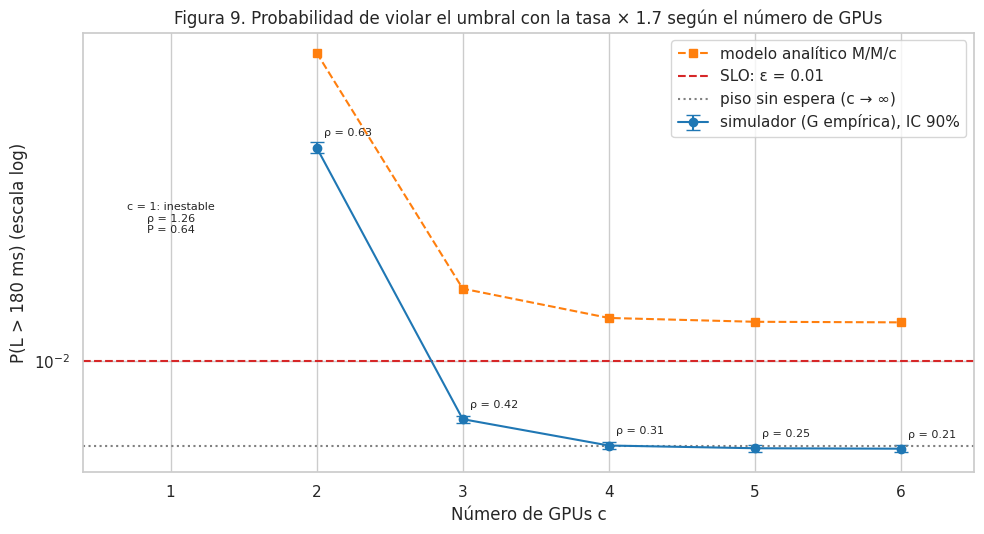

In [186]:
fig, eje = plt.subplots(figsize=(10, 5.5))  # figura
estables_c = tabla_g2[tabla_g2["rho"] < 1]  # c estables
eje.errorbar(estables_c["c"], estables_c["P(L > tau)"],  # puntos del simulador con IC
             yerr=[estables_c["P(L > tau)"] - estables_c["IC inf"], estables_c["IC sup"] - estables_c["P(L > tau)"]],
             fmt="o-", capsize=5, color="tab:blue", label=f"simulador (G empírica), IC {confianza:.0%}")
eje.plot(tabla_mmc["c"][tabla_mmc["c"] > carga_ofrecida], tabla_mmc["P(L > tau) M/M/c"][tabla_mmc["c"] > carga_ofrecida],  # curva M/M/c
         "s--", color="tab:orange", label="modelo analítico M/M/c")
eje.axhline(epsilon, color="tab:red", linestyle="--", label=f"SLO: ε = {epsilon}")  # linea del SLO
eje.axhline(piso_slo, color="gray", linestyle=":", label="piso sin espera (c → ∞)")  # piso sin espera
for _, fila in tabla_g2.iterrows():  # anota cada c
    if fila["rho"] < 1:  # estable
        eje.annotate(f"ρ = {fila['rho']:.2f}", (fila["c"], fila["P(L > tau)"]), textcoords="offset points", xytext=(5, 8), fontsize=8)  # muestra rho
    else:  # inestable
        eje.text(fila["c"], 0.02, f"c = {fila['c']:.0f}: inestable\nρ = {fila['rho']:.2f}\nP = {fila['P(L > tau)']:.2f}", fontsize=8, ha="center")  # texto de inestabilidad
eje.set_yscale("log")  # eje y logaritmico
eje.set_xlabel("Número de GPUs c")  # etiqueta x
eje.set_ylabel(f"P(L > {tau} ms) (escala log)")  # etiqueta y
eje.set_xticks(range(1, max_gpus + 1))  # marcas del eje x
eje.set_xlim(0.4, max_gpus + 0.5)  # limites del eje x
eje.set_title(f"Figura 9. Probabilidad de violar el umbral con la tasa × {g:.1f} según el número de GPUs")  # titulo
eje.legend()  # leyenda
plt.tight_layout()  # ajusta espacios
plt.show()  # muestra la figura

*Pie de Figura 9.* Con 1 GPU el sistema es inestable (ρ > 1). Con 2 GPUs P(L > τ) todavía está tres veces por encima de ε, y con 3 queda por debajo, cerca del piso que fija la cola de red + G. El modelo M/M/c da probabilidades más altas en todos los casos y nunca baja de ε. El lector debe concluir que se necesitan 3 GPUs y que comprar más casi no mejora el SLO.

**Conclusión G3.** Al propagar la incertidumbre de los parámetros, las 100 repeticiones dan c\* = 3. La decisión es robusta: con c = 2, P(L > τ) está tres veces por encima de ε, y con c = 3 queda cerca de 0,007, lejos del límite. La incertidumbre de λ (±1 %), de p, de la red y de la forma de G no alcanza a mover ninguna de las dos configuraciones al otro lado de ε.

El modelo analítico M/M/c **no encuentra ningún c que cumpla**: su piso (≈ 0,0123) ya está por encima de ε. La diferencia viene de que supone tiempos de GPU exponenciales: CV = 1 cuando el real es cercano a 0,78, y una cola P(G > t) = e^(−t/E[G]) que, por ejemplo en 150 ms, es el doble de la real (0,025 frente a 0,012). Por eso exagera tanto la espera (con c = 2: 0,053 frente a 0,031) como el piso. Coincide con el simulador en lo cualitativo (1 GPU inestable, 2 claramente insuficientes, muy poca ganancia después de 3). Es útil como cota rápida, pero para decidir hace falta un modelo de G realista, y el simulador validado en G1 lo tiene.

## G4. Memorando ejecutivo

El memorando está al final del notebook, en la sección "Memorando para el CTO", después de la celda de demostración en vivo. Todas sus cifras salen de las celdas anteriores.

## Demostración en vivo

Cambie `gpus_demo` o `factor_demo` y ejecute la celda. Predicción antes de correr: más GPUs bajan P(L > τ) hasta el piso; un factor mayor sube la carga y, si ρ = a/c pasa de 1, el sistema se vuelve inestable.

In [187]:
gpus_demo = 3  # numero de GPUs a probar
factor_demo = g  # factor de crecimiento de la tasa (g = 1.7 en el escenario del grupo)
replicas_demo = 10  # replicas de la demo

carga_demo = factor_demo * lambda_hat * (1 - p_cache) * gpu_continua.mean() / 1000  # carga ofrecida de la demo
print(f"tasa = {factor_demo * lambda_hat:.2f} sol/s  carga = {carga_demo:.3f} Erlangs  rho = {carga_demo / gpus_demo:.3f}")  # imprime tasa, carga y rho
semillas_demo = rng.integers(0, 2 ** 62, size=replicas_demo)  # semillas de la demo
props_demo = np.array([(simular_sistema(factor_demo * lambda_hat, gpus_demo, 600, np.random.default_rng(int(s)), **parametros_sim) > tau).mean()  # P(L > tau) de cada replica
                       for s in semillas_demo])
t_demo = stats.t.ppf(1 - alpha / 2, replicas_demo - 1)  # cuantil t
error_demo = props_demo.std(ddof=1) / np.sqrt(replicas_demo)  # error estandar
print(f"P(L > {tau}) = {props_demo.mean():.5f} [{props_demo.mean() - t_demo * error_demo:.5f}, {props_demo.mean() + t_demo * error_demo:.5f}], nivel {confianza}")  # imprime P(L > tau) con IC
print("cumple el SLO:", props_demo.mean() + t_demo * error_demo <= epsilon)  # ¿cumple el SLO?

tasa = 48.50 sol/s  carga = 1.259 Erlangs  rho = 0.420
P(L > 180) = 0.00686 [0.00651, 0.00721], nivel 0.9
cumple el SLO: True


# Parte final — Memorando para el CTO (ítem G4)

Antes del memorando calculamos dos cifras de riesgo que se citan en él: la carga que tendría una ráfaga como la del segmento anómalo de A2 en el escenario de crecimiento, y el resumen de las cifras principales en una sola tabla (para que cada número del memorando se pueda rastrear).

In [188]:
tasa_rafaga = len(anomalo) / duracion_anomalo  # tasa observada en el segmento anomalo
carga_rafaga = g * tasa_rafaga * (1 - p_cache) * gpu_continua.mean() / 1000  # carga de la rafaga con crecimiento g
print(f"rafaga observada: {tasa_rafaga:.1f} sol/s ({tasa_rafaga / lambda_hat:.2f} veces la tasa estable)")  # imprime la rafaga observada
print(f"misma rafaga con crecimiento g: {g * tasa_rafaga:.1f} sol/s -> carga {carga_rafaga:.2f} Erlangs -> rho con {c_estrella} GPUs = {carga_rafaga / c_estrella:.2f}")  # imprime la carga proyectada
print(f"GPUs necesarias solo para que la rafaga sea estable: {int(np.floor(carga_rafaga)) + 1}")  # GPUs minimas para estabilidad

fila_c2 = tabla_g2[tabla_g2["c"] == 2].iloc[0]  # fila de 2 GPUs
fila_c3 = tabla_g2[tabla_g2["c"] == c_estrella].iloc[0]  # fila de c* GPUs
resumen_memo = pd.DataFrame({  # tabla resumen de cifras
    "cifra": ["tasa estable (sol/s)", "q fallo por intento", "q en validacion", "latencia media (ms)", "P(L > tau) hoy",  # nombres de las cifras
              "GPU B - A (ms)", "P(L > tau) B - A", "P(L>tau) con 2 GPUs (x g)", "P(L>tau) con c* GPUs (x g)", "c* (proporcion de repeticiones G3)",
              "FA/dia regla D1 y D2", "P(FA <= k_max) D1 y D2", "sensibilidad D1 y D2", "P(incidente | alerta D1 y D2)"],
    "valor": [f"{lambda_hat:.2f} [{lambda_inf:.2f}, {lambda_sup:.2f}]", f"{q_hat:.4f} [{q_hat - z * error_q:.4f}, {q_hat + z * error_q:.4f}]",  # valores con sus IC
              f"{parametros_val['q (fallo por intento)'][0]:.4f}" if hay_validacion else "sin datos",  # q de validacion
              f"{media_lat:.2f} {fila_elegida['IC']}", f"{viol_real.mean():.4f} [{viol_real.mean() - z * error_viol_real:.4f}, {viol_real.mean() + z * error_viol_real:.4f}]",  # latencia media y P(L > tau) hoy
              f"{dif_gpu:.2f} [{dif_gpu - z_bonf * error_gpu:.2f}, {dif_gpu + z_bonf * error_gpu:.2f}]",  # diferencia de gpu
              f"{dif_viol:.4f} [{dif_viol - z_bonf * error_viol:.4f}, {dif_viol + z_bonf * error_viol:.4f}]",  # diferencia de violaciones
              f"{fila_c2['P(L > tau)']:.4f} [{fila_c2['IC inf']:.4f}, {fila_c2['IC sup']:.4f}]",  # P con 2 GPUs
              f"{fila_c3['P(L > tau)']:.4f} [{fila_c3['IC inf']:.4f}, {fila_c3['IC sup']:.4f}]",  # P con c* GPUs
              f"{c_estrella} ({(c_estrellas == c_estrella).mean():.2f})",  # c* y su proporcion
              f"{minutos_dia * (1 - pi_prod) * resultados_reglas['D1 y D2']['tfp']:.2f}",  # falsas alarmas por dia
              tabla_e4.loc[tabla_e4["regla"] == "D1 y D2", "P(FA <= k_max) [IC]"].iloc[0],  # P(FA <= k_max)
              f"{resultados_reglas['D1 y D2']['sens']:.3f}", filas_e2[2][1]],  # sensibilidad y VPP
})
print(resumen_memo.to_string(index=False))  # imprime la tabla resumen

rafaga observada: 67.3 sol/s (2.36 veces la tasa estable)
misma rafaga con crecimiento g: 114.4 sol/s -> carga 2.97 Erlangs -> rho con 3 GPUs = 0.99
GPUs necesarias solo para que la rafaga sea estable: 3
                             cifra                      valor
              tasa estable (sol/s)       28.53 [28.26, 28.81]
               q fallo por intento    0.1285 [0.1255, 0.1315]
                   q en validacion                     0.1793
               latencia media (ms)     48.41 [47.857, 48.968]
                    P(L > tau) hoy    0.0096 [0.0083, 0.0109]
                    GPU B - A (ms)       -4.64 [-5.63, -3.66]
                  P(L > tau) B - A -0.0039 [-0.0063, -0.0015]
         P(L>tau) con 2 GPUs (x g)    0.0319 [0.0309, 0.0329]
        P(L>tau) con c* GPUs (x g)    0.0073 [0.0071, 0.0074]
c* (proporcion de repeticiones G3)                   3 (1.00)
              FA/dia regla D1 y D2                       3.18
            P(FA <= k_max) D1 y D2    0.9570 [0.7614

---

**MEMORANDO**

**Para:** Dirección Técnica (CTO), AndesVision AI
**De:** Equipo SRE y de datos — D. Loaiza, M. Pinzón, D. Vargas
**Asunto:** Confiabilidad del servicio de inferencia, versión B y capacidad para el crecimiento proyectado
**Base:** 20 minutos de telemetría de producción, 6000 minutos de pruebas de monitoreo y una segunda ventana de producción para validar. Todas las cifras tienen un nivel de confianza del 90 %.

**1. ¿Cómo se comporta hoy el servicio? (P1)**
En operación normal llegan unas **28,5 solicitudes por segundo** (entre 28,3 y 28,8), de forma aleatoria pero estable. Durante unos 3 minutos de la ventana hubo una **ráfaga de tráfico** de 2,4 veces lo normal que multiplicó por 2,5 la latencia media: la excluimos para medir el comportamiento normal, pero es un riesgo real (punto 4). El 36 % de las solicitudes se responde desde caché, sin usar GPU; el resto tarda en promedio 41 ms de GPU, más cuanto más pesada es la imagen. Cerca del **13 %** de las solicitudes necesita reintentar y el 0,16 % se pierde tras 3 intentos fallidos. La latencia media es de **48 ms**, y hoy el **0,96 %** de las solicitudes supera los 180 ms, justo por debajo del límite del 1 % del SLO: **estamos al borde**. En la ventana de validación los reintentos subieron al **18 %** sin que cambiara el tráfico; es un problema de errores del servicio, no de capacidad, y hay que investigarlo.

**2. ¿La versión B es mejor? (P2)**
**Sí, recomendamos adoptarla.** En un experimento con asignación al azar, B usa **4,6 ms menos de GPU por solicitud** (entre 3,7 y 5,6 ms; un 11 % menos) y reduce las solicitudes lentas (> 180 ms) de 1,2 % a 0,8 %, sin aumentar los reintentos. El resultado se repitió en la ventana de validación.

**3. ¿Cuántas GPUs se necesitan si el tráfico crece 1,7 veces? (P3)**
**Tres GPUs** (una más que hoy). Con el tráfico proyectado (unas 48,5 solicitudes/s):
- 1 GPU no da abasto (la cola crece sin límite);
- 2 GPUs dejan un **3,1 %** de solicitudes por encima de 180 ms, el triple de lo permitido;
- 3 GPUs dejan un **0,7 %**, dentro del SLO.

La recomendación es robusta: al variar los parámetros dentro de su margen de error, las 100 simulaciones dieron 3 GPUs. Una cuarta GPU casi no mejora (0,6 %), porque el resto de la lentitud viene de la red y de imágenes pesadas, no de la cola.

**Regla de alertas:** activar la guardia solo cuando **D1 y D2 alerten a la vez**. Es la única regla que cumple la exigencia del equipo (como máximo 6 falsas alarmas por día con probabilidad ≥ 90 %): genera unas 3 falsas alarmas diarias. Cuando suena, hay un incidente real cerca de la mitad de las veces (con D1 sola, solo 1 de cada 5). El costo es que no detecta cerca del 30 % de los incidentes; proponemos revisar D1 sola en horario laboral, sin despertar a la guardia.

**4. Riesgos y supuestos**
- **Ráfagas:** una ráfaga como la observada, con el tráfico ya crecido (unas 114 solicitudes/s), llevaría 3 GPUs al 99 % de utilización, al borde del colapso: durante el pico la cola crecería mucho y el SLO se incumpliría. Recomendamos autoescalado o limitación de tráfico para esos picos.
- El margen con 3 GPUs depende de la cola real de tiempos de GPU. Un modelo más pesimista (lognormal) no cumpliría con ninguna cantidad de GPUs: conviene monitorear el percentil 99 de GPU.
- Supusimos que el crecimiento es parejo (sin cambiar la mezcla de tamaños ni la tasa de caché) y que los reintentos no ocupan GPU (lo respaldan los datos de validación). Si lo hicieran, 3 GPUs seguirían cumpliendo, con menos margen (0,86 %).
- La regla de alertas se estimó con solo 12 falsas alarmas de prueba: hay que re-estimarla con datos de producción en el primer mes.